In [1]:
import json
import numpy as np
import trimesh
import cv2
import matplotlib.pyplot as plt
import torch
import os
import logging
import torch
import hydra
import sys
from hydra import compose, initialize
from omegaconf import OmegaConf
import torch.nn.functional as F
from sklearn.decomposition import PCA
import objaverse
os.environ["PYOPENGL_PLATFORM"] = "egl"  # rendering offscreen headless
import pyrender


os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["HYDRA_FULL_ERROR"] = "1" # Debug

# DINO
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


In [2]:
import objaverse

UID = "04ab56ff7f5044629e424a6fcb871b76"        # Polipetto
#UID =  "026dfb57bcb5406688a7b20dfbecc6c2"    # chiave
#UID = "0292b47486774a538c0f891605c7bda1"    # Macchinina
#UID = "01ab7318c6f748569ee683ea13ba78c0"   # Chitarra
objects = objaverse.load_objects(
    uids=[UID],
    download_processes=1
)

GLB_PATH = objects[UID]
print(f"Oggetto scaricato in: {GLB_PATH}")

Oggetto scaricato in: /home/riccardop02/.objaverse/hf-objaverse-v1/glbs/000-023/04ab56ff7f5044629e424a6fcb871b76.glb


In [3]:
loaded = trimesh.load(GLB_PATH)  # SENZA force="mesh", per ispezionare
if isinstance(loaded, trimesh.Scene):
    print("n. geometrie:", len(loaded.geometry))
    for name, geom in loaded.geometry.items():
        mat = getattr(geom.visual, "material", None)
        print(name, type(geom.visual), getattr(mat, "name", mat))

        

n. geometrie: 2
Sphere.001_Low__0 <class 'trimesh.visual.texture.TextureVisuals'> Sphere.001_Low__0
Sphere_Low_octopus_0 <class 'trimesh.visual.texture.TextureVisuals'> octopus


# Create The model

In [4]:
# Utilities
MAX_TEXTURE_SIZE = 512  

def load_mesh(model_path: str) -> trimesh.Trimesh:
    loaded = trimesh.load(model_path, force="mesh")

    if isinstance(loaded, trimesh.Scene):
        if len(loaded.geometry) == 0:
            raise ValueError(f"Nessuna geometria trovata in: {model_path}")
        mesh = loaded.dump(concatenate=True)
    else:
        mesh = loaded

    if not isinstance(mesh, trimesh.Trimesh):
        raise TypeError(f"Tipo mesh non supportato dopo il caricamento: {type(mesh)}")

    return mesh

def fps_torch(x: torch.Tensor, n: int) -> torch.Tensor:

    """x: (N,3) -> (n,3). FPS deterministico, tutto su device."""
    idx = torch.zeros(n, dtype=torch.long, device=x.device)
    idx[0] = (x - x.mean(0)).norm(dim=-1).argmax()      # start deterministico: punto più lontano dal centroide
    dist = (x - x[idx[0]]).norm(dim=-1)

    # for every point we take the farthest and we update the distance to the closest selected point
    for i in range(1, n):
        idx[i] = dist.argmax()
        dist = torch.minimum(dist, (x - x[idx[i]]).norm(dim=-1))
    return x[idx]

def fibonacci_sphere(n: int, radius: float) -> np.ndarray:
    """n posizioni camera quasi-uniformi su una sfera di raggio `radius`."""
    idx = np.arange(n)
    golden = (1 + 5 ** 0.5) / 2
    theta = 2 * np.pi * idx / golden
    z = 1 - (2 * idx + 1) / n
    r_xy = np.sqrt(np.maximum(0.0, 1 - z * z))
    x, y = r_xy * np.cos(theta), r_xy * np.sin(theta)
    return (np.stack([x, y, z], axis=-1) * radius).astype(np.float32)


def look_at_RT(cam_pos: np.ndarray, target: np.ndarray = np.zeros(3),
               up_hint: np.ndarray = np.array([0., 1., 0.])):
    """R, trans mondo->camera in convenzione OpenGL (camera guarda lungo -Z, y su): p_gl = R @ p_world + trans."""
    forward = target - cam_pos
    forward = forward / (np.linalg.norm(forward) + 1e-8)
    if abs(np.dot(forward, up_hint)) > 0.99:
        up_hint = np.array([1., 0., 0.])
    right = np.cross(forward, up_hint)
    right = right / (np.linalg.norm(right) + 1e-8)
    up = np.cross(right, forward)

    R_w2c = np.stack([right, up, -forward], axis=0)
    trans = -R_w2c @ cam_pos
    return R_w2c.astype(np.float32), trans.astype(np.float32)


def render_view(mesh: trimesh.Trimesh, R: np.ndarray, trans: np.ndarray,
                K: np.ndarray, image_size: int):
    """Colore + depth con pyrender. Camera->world costruita invertendo (R, trans)."""
    scene = pyrender.Scene(bg_color=[1.0, 1.0, 1.0, 0.0], ambient_light=[0.6, 0.6, 0.6])
    scene.add(pyrender.Mesh.from_trimesh(mesh, smooth=False))

    cam_pos = -R.T @ trans
    pose = np.eye(4, dtype=np.float32)
    pose[:3, :3] = R.T
    pose[:3, 3] = cam_pos

    camera = pyrender.IntrinsicsCamera(fx=K[0, 0], fy=K[1, 1], cx=K[0, 2], cy=K[1, 2])
    scene.add(camera, pose=pose)
    scene.add(pyrender.DirectionalLight(color=[1.0, 1.0, 1.0], intensity=3.0), pose=pose)

    r = pyrender.OffscreenRenderer(image_size, image_size)
    try:
        color, depth = r.render(scene)
    finally:
        r.delete()
    return np.ascontiguousarray(color[:, :, :3]), np.ascontiguousarray(depth)


_GL2CV = torch.tensor([1., -1., -1.])


def project_points(points_world: torch.Tensor, R: torch.Tensor, trans: torch.Tensor, K: torch.Tensor):
    """points_world: (P,3) -> uv pixel (P,2), depth camera-space (P,). R/trans sono OpenGL, K è OpenCV."""
    p_gl = points_world @ R.T + trans
    p_cam = p_gl * _GL2CV.to(p_gl.device)          # GL -> CV: y verso il basso
    z = p_cam[:, 2].clamp(min=1e-6)
    uv = ((p_cam / z.unsqueeze(-1)) @ K.T)[:, :2]
    return uv, z


def sample_feature_grid(feat_grid: torch.Tensor, uv: torch.Tensor, image_size: int) -> torch.Tensor:
    """feat_grid: (1,D,Hp,Wp). uv in pixel coord. -> (P, D) via bilinear grid_sample."""
    uv_norm = (uv / image_size) * 2 - 1
    grid = uv_norm.view(1, -1, 1, 2)
    sampled = F.grid_sample(feat_grid, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return sampled.squeeze(0).squeeze(-1).T


def visibility_mask(uv: torch.Tensor, z_point: torch.Tensor, depth_map: torch.Tensor,
                    image_size: int, tol: float = 0.03) -> torch.Tensor:
    in_bounds = (uv[:, 0] >= 0) & (uv[:, 0] < image_size) & (uv[:, 1] >= 0) & (uv[:, 1] < image_size)
    ix = uv[:, 0].long().clamp(0, image_size - 1)
    iy = uv[:, 1].long().clamp(0, image_size - 1)
    z_render = depth_map[iy, ix]
    return in_bounds & (z_render > 0) & ((z_point - z_render).abs() < tol)


def get_target_size(encoder2d) -> int:
    """Risoluzione di output del processor DINOv2 (il render viene fatto già a questa risoluzione)."""
    proc = encoder2d.processor
    size = getattr(proc, "crop_size", None) or proc.size
    return size["height"]

@torch.no_grad()
def extract_dinov2_grid(encoder2d, image_uint8: np.ndarray, device: torch.device):
    """
    image_uint8: (H, W, 3) uint8, il render.
    Ritorna (1, D, Hp, Wp), H_proc, W_proc. Richiede encoder2d.token == "PatchToken".
    """
    if encoder2d.token != "PatchToken":
        raise ValueError(
            f"encoder2d.token='{encoder2d.token}', serve 'PatchToken' per una griglia spaziale campionabile"
        )

    proc = encoder2d.processor
    # niente resize/crop: il render ha già la risoluzione giusta, così K resta coerente con la griglia.
    # La normalizzazione (mean/std) resta identica al training.
    inputs = proc(images=image_uint8, return_tensors="pt",
                  do_resize=False, do_center_crop=False)
    pixel_values = inputs["pixel_values"].to(device)

    tokens = encoder2d.extractFeatures(pixel_values)           # (1, N, D)
    N, D = tokens.shape[1], tokens.shape[2]

    patch_size = encoder2d.model.config.patch_size
    H_proc, W_proc = pixel_values.shape[-2], pixel_values.shape[-1]
    Hp, Wp = H_proc // patch_size, W_proc // patch_size
    assert Hp * Wp == N, f"grid {Hp}x{Wp}={Hp*Wp} non combacia con N={N} token"

    return tokens.transpose(1, 2).reshape(1, D, Hp, Wp), H_proc, W_proc


def process_model(model_dir: str, encoder2d, n_points: int, n_views: int,
                  cam_radius: float, fov_deg: float, device: torch.device):

    # Load the mesh
    mesh = load_mesh(model_dir)

    # Sample points on the mesh surface and apply FPS to get n_points
    dense_xyz = trimesh.sample.sample_surface(mesh, 20000)[0].astype(np.float32)
    points = fps_torch(torch.from_numpy(dense_xyz).to(device), n_points)

    #compute centroid and scale to normalize points and mesh to canonical frame
    centroid = points.mean(dim=0, keepdim=True)
    points_c = points - centroid
    scale = points_c.norm(dim=-1).max().clamp(min=1e-6)
    points_n = points_c / scale                                 # frame canonico

    mesh_c = mesh.copy()
    mesh_c.vertices = (mesh_c.vertices - centroid.cpu().numpy()) / scale.item()

    # Compute the intrinsic matrix
    image_size = get_target_size(encoder2d)
    f = 0.5 * image_size / np.tan(np.radians(fov_deg) / 2)
    K_np = np.array([[f, 0, image_size / 2], [0, f, image_size / 2], [0, 0, 1]], dtype=np.float32)
    K = torch.from_numpy(K_np).to(device)

    # Obtain camera positions on a sphere around the object to render multiple views that cover entirely the object 
    cam_positions = fibonacci_sphere(n_views, radius=cam_radius)
    view_feats, view_dirs, masks = [], [], []

    for cam_pos in cam_positions:
        # Compute the camera extrinsic matrix (R, trans) using the look_at_RT function
        R_np, trans_np = look_at_RT(cam_pos)
        R, trans = torch.from_numpy(R_np).to(device), torch.from_numpy(trans_np).to(device)

        # Render the view of the mesh from the camera position and obtain the color and depth images
        color, depth = render_view(mesh_c, R_np, trans_np, K_np, image_size)
        depth_t = torch.from_numpy(depth).to(device)


        feat_grid, H_proc, W_proc = extract_dinov2_grid(encoder2d, color, device)
        assert H_proc == image_size and W_proc == image_size, \
            "il processor ha ritagliato/scalato: K non è più coerente con la griglia di feature"

        # Project the 3D points into the camera view and compute the visibility mask
        uv, z_point = project_points(points_n, R, trans, K)
        vis = visibility_mask(uv, z_point, depth_t, image_size)

        feats = sample_feature_grid(feat_grid, uv, image_size) * vis.unsqueeze(-1)

        cam_pos_t = torch.from_numpy(cam_pos).to(device)
        d = F.normalize(cam_pos_t.unsqueeze(0) - points_n, dim=-1) * vis.unsqueeze(-1)

        view_feats.append(feats.cpu().numpy())
        view_dirs.append(d.cpu().numpy())
        masks.append(vis.cpu().numpy())

    return (points_n.cpu().numpy(),
            np.stack(view_feats, axis=1),    # (P, n_views, D)
            np.stack(view_dirs, axis=1),     # (P, n_views, 3)
            np.stack(masks, axis=1),         # (P, n_views)
            centroid.cpu().numpy(), scale.item())

def _generate_rays(K, R, trans, centroid, scale, grid_size=16, patch_size=16):
        """
        Plucker rays, normalized by centroid and scale of the 3D model.
        """
        B = K.shape[0]
        device = K.device

        y = torch.arange(grid_size, device=device, dtype=torch.float32)
        x = torch.arange(grid_size, device=device, dtype=torch.float32)
        grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')

        u = grid_x * patch_size + (patch_size / 2.0)
        v = grid_y * patch_size + (patch_size / 2.0)

        uv1 = torch.stack([u, v, torch.ones_like(u)], dim=-1).reshape(-1, 3)
        uv1 = uv1.unsqueeze(0).expand(B, -1, -1)

        K_inv = torch.linalg.inv(K)
        d_c = torch.bmm(uv1, K_inv.transpose(1, 2))

        R_inv = R.transpose(1, 2)
        d_o = F.normalize(torch.bmm(d_c, R_inv.transpose(1, 2)), p=2, dim=-1)   # (B, N, 3)

       
        centroid_col = centroid.unsqueeze(-1)                                            # (B, 3, 1)
        trans_norm = (trans.unsqueeze(-1) + torch.bmm(R, centroid_col)).squeeze(-1)      # (B, 3)
        trans_norm = trans_norm / scale.unsqueeze(-1)                                    # (B, 3)

        O = -torch.bmm(R_inv, trans_norm.unsqueeze(-1)).squeeze(-1)                      # (B, 3)
        O_exp = O.unsqueeze(1).expand(-1, d_o.shape[1], -1)
        moment = torch.cross(O_exp, d_o, dim=-1)                                         # (B, N, 3)

        return d_o, moment

def masked_l1_per_sample(pred_tensor, targ_tensor, mask_tensor):
    """Restituisce la L1 mascherata per ogni elemento del batch: shape (B,)"""
    err = F.l1_loss(pred_tensor, targ_tensor, reduction='none').mean(dim=-1)  # (B, N)
    valid = mask_tensor.float()
    return (err * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)


In [5]:
# Instatiate the model

sys.path.insert(0, "/home/riccardop02/JEPA")

logging.basicConfig(level=logging.INFO)
log = logging.getLogger(__name__)

# --- Config ---
with initialize(version_base=None, config_path="../../configs"):
    cfg = compose(config_name="config")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Only for the UNI3D


# --- Istanzia i modelli ---
encoder2d = hydra.utils.instantiate(cfg.encoder2d)
encoder3d = hydra.utils.instantiate(cfg.encoder3d, in_dim = encoder2d.output_dim[-1])
encoder2d.to(device)
encoder3d.to(device)
log.info("Dino Initialized...")
log.info(f"Encoder2d: {type(encoder2d)}, output_dim: {encoder2d.output_dim}, "
          f"layers: {encoder2d.layers}, token: {encoder2d.token}")
log.info(f"Encoder3d: {type(encoder3d)}, output_dim: {encoder3d.output_dim}")

predictor = hydra.utils.instantiate(
    cfg.Predictor,
    context_dim=encoder3d.output_dim[0][-1],
    output_dim=encoder2d.output_dim[-1]
)
predictor.to(device)

# predictor appena inizializzato (pesi random), per confronto/test strutturale
predictor_init = hydra.utils.instantiate(
    cfg.Predictor, context_dim=encoder3d.output_dim[0][-1], output_dim=encoder2d.output_dim[-1]
).to(device)
predictor_init.eval()

# --- Carica checkpoint ---
PATH_CHECK = '/experiments/riccardop02/outputs/2026-11-04/10-40-44/checkpoints/best.pt' 
checkpoint = torch.load(PATH_CHECK, map_location=device, weights_only=False)

encoder2d.load_state_dict(checkpoint["models"]['encoder2d'])
predictor.load_state_dict(checkpoint["models"]['predictor'])
encoder3d.load_state_dict(checkpoint["models"]['encoder3d'])

encoder2d.eval()
predictor.eval()
encoder3d.eval()
log.info(f"Checkpoint loaded from {PATH_CHECK}, epoch {checkpoint['epoch']}")




INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m/resolve/main/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m/resolve/main/preprocessor_config.json "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m/resolve/main/config.json "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

DINOv3: facebook/dinov3-vitl16-pretrain-lvd1689m, layers=[18], token=PatchToken, normalize=True, freeze=True, image_size=256


INFO:__main__:Dino Initialized...
INFO:__main__:Encoder2d: <class 'src.models.encoder2d.DINOv3.DINOv3'>, output_dim: torch.Size([256, 1024]), layers: [18], token: PatchToken
INFO:__main__:Encoder3d: <class 'src.models.encoder3d.Aggregator.Aggregator'>, output_dim: ((1, None, 1024), (1, None, 3))
INFO:root:RayCrossAttnPredictor initialized (depth=6, PosFourierBands=10, DirFourierBands=4, plucker=True)
INFO:root:RayCrossAttnPredictor initialized (depth=6, PosFourierBands=10, DirFourierBands=4, plucker=True)
INFO:__main__:Checkpoint loaded from /experiments/riccardop02/outputs/2026-11-04/10-40-44/checkpoints/best.pt, epoch 57


In [6]:
points, view_feats, view_dirs, mask, centroid, scale = process_model(
    GLB_PATH, encoder2d, n_points=512, n_views=24,
    cam_radius=2.5, fov_deg=40.0, device=device
)

# numpy -> torch + aggiunta dimensione batch (B=1)
points_t     = torch.from_numpy(points).unsqueeze(0).to(device).float()      # (1, P, 3)
view_feats_t = torch.from_numpy(view_feats).unsqueeze(0).to(device).float()  # (1, P, N, D)
view_dirs_t  = torch.from_numpy(view_dirs).unsqueeze(0).to(device).float()   # (1, P, N, 3)
mask_t       = torch.from_numpy(mask).unsqueeze(0).to(device).bool()         # (1, P, N)

with torch.no_grad():
    feats3d, centers = encoder3d.extractFeatures(view_feats_t, view_dirs_t, mask_t, points_t)

log.info(f"3D features: {feats3d.shape}, centers: {centers.shape}")

INFO:__main__:3D features: torch.Size([1, 512, 1024]), centers: torch.Size([1, 512, 3])


In [7]:

centroid = np.asarray(centroid).reshape(3)   # forza (3,), niente più dimensione fantasma
N_VIEW = 36
IMG_SIZE = 256
CAM_DIST = 2.0          # distanza in spazio NORMALIZZATO (quella con cui è stato allenato il modello)
FOV_Y = np.pi / 3.0

# --- Carica la mesh RAW, SENZA normalizzarla ---
scene_trimesh = trimesh.load(GLB_PATH, force="scene")
mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh
# NIENTE mesh_tm.vertices -= ... / *= ... qui: usiamo le coordinate raw,
# centroid/scale (calcolati sopra da process_single_object) faranno da convertitore

mesh = pyrender.Mesh.from_trimesh(mesh_tm, smooth=False)

# --- Distanza camera in unità RAW, coerente con lo `scale` del point cloud ---
CAM_DIST_RAW = CAM_DIST * scale

# --- Intrinseca (costante per tutte le viste) ---
def get_intrinsics(width, height, fov_y):
    f = height / (2 * np.tan(fov_y / 2))
    cx, cy = width / 2, height / 2
    return np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]], dtype=np.float32)

K = get_intrinsics(IMG_SIZE, IMG_SIZE, FOV_Y)

renderer = pyrender.OffscreenRenderer(IMG_SIZE, IMG_SIZE)
camera = pyrender.PerspectiveCamera(yfov=FOV_Y, aspectRatio=1.0)
light = pyrender.DirectionalLight(color=np.ones(3), intensity=3.0)

# --- Look-at coerente con la convenzione di training (OpenCV: +Z forward, Y down) ---
def look_at_opencv(eye, target=np.array([0.0, 0.0, 0.0]), world_up=np.array([0.0, 1.0, 0.0])):
    """
    Ritorna:
      R_w2c : (3,3) rotazione world-to-camera, convenzione OpenCV
      t_w2c : (3,)  traslazione world-to-camera coerente con R_w2c
      cam_pose_gl : (4,4) posa camera-to-world in convenzione OpenGL, per pyrender
    """
    forward = target - eye
    forward = forward / np.linalg.norm(forward)

    right = np.cross(forward, world_up)
    right = right / np.linalg.norm(right)
    up = np.cross(right, forward)

    R_cam_to_world = np.stack([right, -up, forward], axis=1)
    R_w2c = R_cam_to_world.T
    t_w2c = -R_w2c @ eye

    cam_pose_gl = np.eye(4)
    cam_pose_gl[:3, :3] = R_cam_to_world
    cam_pose_gl[:3, 3] = eye
    cv_to_gl = np.diag([1.0, -1.0, -1.0, 1.0])
    cam_pose_gl = cam_pose_gl @ cv_to_gl

    return R_w2c.astype(np.float32), t_w2c.astype(np.float32), cam_pose_gl


# --- Dizionario principale: view_id -> {rgb, mask, K, R, ...} ---
render_data = {}

for i in range(N_VIEW):
    theta = 2 * np.pi * i / N_VIEW
    phi = np.pi / 4

    direction = np.array([
        np.cos(theta) * np.sin(phi),
        np.cos(phi),
        np.sin(theta) * np.sin(phi)
    ])
    eye = centroid + CAM_DIST_RAW * direction   # <-- orbita attorno al centroid, in unità raw

    R_pose, T_cam, cam_pose = look_at_opencv(eye, target=centroid)  # <-- guarda verso centroid

    scene = pyrender.Scene(bg_color=[0, 0, 0, 1.0], ambient_light=[0.3, 0.3, 0.3])
    scene.add(mesh)
    scene.add(camera, pose=cam_pose)
    scene.add(light, pose=cam_pose)

    color, depth = renderer.render(scene, flags=pyrender.RenderFlags.RGBA)

    render_data[i] = {
        "rgb": color[..., :3],
        "mask": (depth > 0).astype(np.uint8) * 255,
        "K": K,
        "R_pose": R_pose,
        "eye": eye,
        "T_cam": T_cam,
        "theta": theta,
        "phi": phi,
    }

renderer.delete()

print(f"Renderizzate {N_VIEW} viste, salvate in memoria in `render_data`.")

/tmp/ipykernel_1287095/297415411.py:9: DeprecationWarning: `Scene.dump(concatenate=True)` DEPRECATED FOR REMOVAL APRIL 2025: replace with `Scene.to_geometry()`
  mesh_tm = scene_trimesh.dump(concatenate=True) if isinstance(scene_trimesh, trimesh.Scene) else scene_trimesh


Renderizzate 36 viste, salvate in memoria in `render_data`.





In [8]:
#Plotting each view and the mask
fig, axes = plt.subplots(N_VIEW, 2, figsize=(6, 3 * N_VIEW))

for i in range(N_VIEW):
    axes[i, 0].imshow(render_data[i]["rgb"])
    axes[i, 0].set_title(f"View {i} - RGB")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(render_data[i]["mask"], cmap="gray")
    axes[i, 1].set_title(f"View {i} - Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [9]:
from PIL import Image as PILImage

def pixel_mask_to_token_mask(mask, grid_size=16):
    mask_pil = PILImage.fromarray((mask.astype(np.uint8)) * 255 if mask.max() <= 1 else mask.astype(np.uint8))
    mask_grid = mask_pil.resize((grid_size, grid_size), PILImage.BOX)
    return np.array(mask_grid, dtype=np.float32) / 255.0  # valori continui [0,1]

Context features: torch.Size([1, 512, 1024]), centers: torch.Size([1, 512, 3])


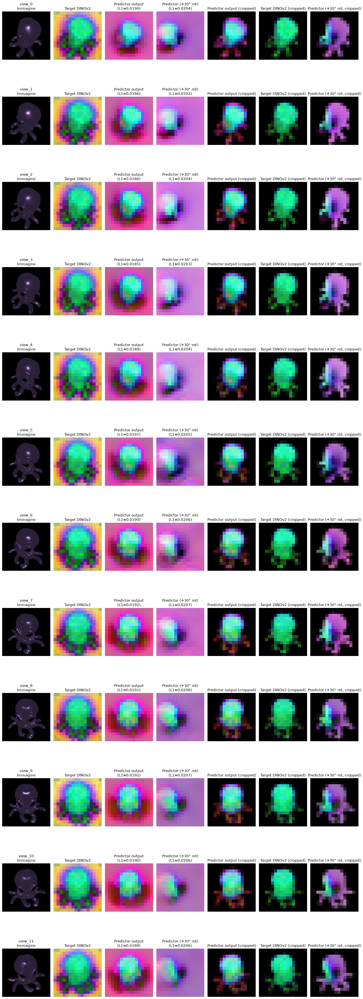

In [10]:
from sklearn.decomposition import PCA

N_OBJECTS = min(12, len(render_data))
GRID_SIZE = 16
WRONG_ROT_DEG = 30.0  # gradi di rotazione errata da aggiungere

MEAN_t = torch.tensor(MEAN, dtype=torch.float32, device=device).view(1, 3, 1, 1)
STD_t = torch.tensor(STD, dtype=torch.float32, device=device).view(1, 3, 1, 1)

context_t = feats3d.to(device)
centers_t = centers.to(device)

print(f"Context features: {context_t.shape}, centers: {centers_t.shape}")

def to_rgb_map_local(pca_tokens, grid_size=GRID_SIZE):
    """Normalizzazione min/max LOCALE, calcolata solo sui token passati (come nello script di validation)."""
    vmin = pca_tokens.min(axis=0, keepdims=True)
    vmax = pca_tokens.max(axis=0, keepdims=True)
    norm = (pca_tokens - vmin) / (vmax - vmin + 1e-8)
    norm = np.clip(norm, 0, 1)
    return norm.reshape(grid_size, grid_size, 3)

def rotation_matrix(axis, deg, device):
    """Matrice di rotazione 3x3 attorno a un asse ('x', 'y' o 'z')."""
    rad = np.deg2rad(deg)
    c, s = np.cos(rad), np.sin(rad)
    if axis == 'x':
        R = np.array([[1, 0, 0],
                      [0, c, -s],
                      [0, s,  c]], dtype=np.float32)
    elif axis == 'y':
        R = np.array([[ c, 0, s],
                      [ 0, 1, 0],
                      [-s, 0, c]], dtype=np.float32)
    elif axis == 'z':
        R = np.array([[c, -s, 0],
                      [s,  c, 0],
                      [0,  0, 1]], dtype=np.float32)
    else:
        raise ValueError("axis deve essere 'x', 'y' o 'z'")
    return torch.from_numpy(R).to(device)

R_offset = rotation_matrix('y', WRONG_ROT_DEG, device)  # <-- cambia asse se serve

view_ids = list(render_data.keys())[:N_OBJECTS]

fig, axes = plt.subplots(N_OBJECTS, 7, figsize=(16.8, 4 * N_OBJECTS))
if N_OBJECTS == 1:
    axes = axes[None, :]

for i, vid in enumerate(view_ids):
    view = render_data[vid]

    img_np = view["rgb"].astype(np.float32) / 255.0
    img_t = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device)
    img_t = (img_t - MEAN_t) / STD_t

    mask_t = torch.from_numpy(view["mask"].astype(np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(device)

    K_t = torch.from_numpy(view["K"]).unsqueeze(0).to(device).float()
    # R world-to-camera corretta: è R_pose, non R_cam (che è camera-to-world)
    rot_t = torch.from_numpy(view["R_pose"]).unsqueeze(0).to(device).float()
    trans_t = torch.from_numpy(view["T_cam"]).unsqueeze(0).to(device).float()

    rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)
    token_mask_np = pixel_mask_to_token_mask(view["mask"], grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np.reshape(-1)).float().unsqueeze(0).to(device)
    

    mask_t = torch.from_numpy(token_mask_np.reshape(-1)).float().unsqueeze(0).to(device)

    centroid_t = torch.from_numpy(centroid).unsqueeze(0).to(device).float()   # (1, 3)
    scale_t = torch.tensor([scale], device=device).float()      

    ray_dirs, moment_c = _generate_rays(K_t, rot_t, trans_t, centroid_t, scale_t)
    ray_dirs_wrong, moment_wrong = _generate_rays(K_t, rot_wrong_t, trans_t, centroid_t, scale_t)

    with torch.no_grad():
        target = encoder2d(img_t)
        pred = predictor(
            ray_dirs=ray_dirs,
            ray_moments=moment_c,
            context_features=context_t,
            context_centers=centers_t,
        )
        pred_wrong = predictor(
            ray_dirs=ray_dirs_wrong,
            ray_moments=moment_wrong,
            context_features=context_t,
            context_centers=centers_t,
        )
        l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
        l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()


    target_np = target.squeeze(0).cpu().numpy()          # (256, 768)
    pred_np = pred.squeeze(0).cpu().numpy()               # (256, 768)
    pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()    # (256, 768)

    # --- PCA fittata SOLO sul target di QUESTA vista ---
    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    pred_pca = pca.transform(pred_np)
    pred_wrong_pca = pca.transform(pred_wrong_np)  # stessa PCA del target, come richiesto

    # --- Normalizzazione min/max LOCALE ---
    target_map = to_rgb_map_local(target_pca)
    pred_map = to_rgb_map_local(pred_pca)
    pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"view_{vid}\nImmagine")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(pred_map)
    axes[i, 2].set_title(f"Predictor output\n(L1={l1_pred:.4f})")
    axes[i, 2].axis('off')

    axes[i, 3].imshow(pred_wrong_map)
    axes[i, 3].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot)\n(L1={l1_pred_wrong:.4f})")
    axes[i, 3].axis('off')

    axes[i, 4].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 4].set_title("Predictor output (cropped)")
    axes[i, 4].axis('off')

    axes[i, 5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 5].set_title("Target DINOv2 (cropped)")
    axes[i, 5].axis('off')


    axes[i, 6].imshow(pred_wrong_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1))
    axes[i, 6].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot, cropped)")
    axes[i, 6].axis('off')

plt.tight_layout()
plt.show();

In [11]:
# =========================
# Carica un batch dal dataset di validation (riusa il `cfg` già caricato in Cell 6)
# =========================
BATCH_SIZE = 10

dataset = hydra.utils.instantiate(cfg.data, dataset_source=cfg.gso.root, split="val")
loader_single = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, num_workers=0)
sample_iter = iter(loader_single)


INFO:src.data.dataset_HF_REF:[HF val] 1040 shards, 1030 modelli; TAR letto in streaming senza cache su disco


Santa_Cruz_Mens_YmsMDkFf11Z: L1 pred=0.0166 | L1 pred(+90°)=0.0211
WHALE_WHISTLE_6PCS_SET: L1 pred=0.0197 | L1 pred(+90°)=0.0225
Pokémon_Yellow_Special_Pikachu_Edition_Nintendo_Game_Boy_Color: L1 pred=0.0189 | L1 pred(+90°)=0.0223
Kid_Icarus_Uprising_Nintendo_3DS_Game: L1 pred=0.0167 | L1 pred(+90°)=0.0210
Reebok_ZIGSTORM: L1 pred=0.0183 | L1 pred(+90°)=0.0211
New_Super_Mario_BrosWii_Wii_Game: L1 pred=0.0185 | L1 pred(+90°)=0.0212
Sperry_TopSider_tNB9t6YBUf3: L1 pred=0.0172 | L1 pred(+90°)=0.0195
Perricone_MD_AcylGlutathione_Deep_Crease_Serum: L1 pred=0.0176 | L1 pred(+90°)=0.0217


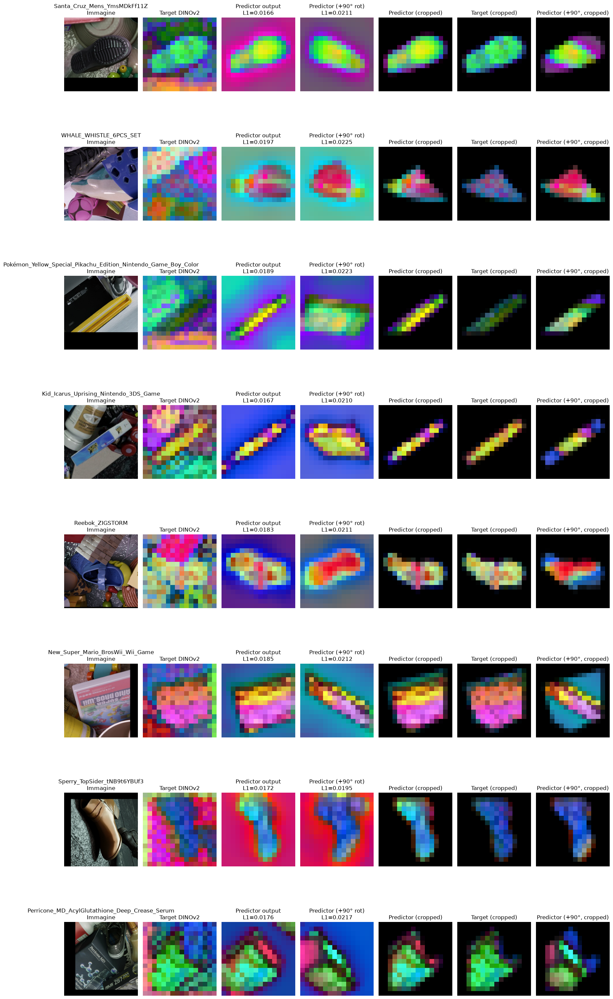

In [12]:
# =========================
# Visualizzazione target vs predictor su sample reali dal batch
# =========================
batch = next(sample_iter)
actual_bs = batch['image'].shape[0]


N_SHOW = min(8, actual_bs)
WRONG_ROT_DEG = 90.0
R_offset = rotation_matrix('y', WRONG_ROT_DEG, device)  # riusa da Cell 9

fig, axes = plt.subplots(N_SHOW, 7, figsize=(16.8, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    img_i = batch['image'][i].unsqueeze(0).to(device).float()   # (1,3,H,W)
    mask_i = batch['mask'][i].to(device).float()                 # (H,W)

    # --- Auto-detect: immagine gia' normalizzata (mean/std) o raw [0,1]? ---
    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i  # gia' normalizzata dal dataset

    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()   # world-to-camera
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)

    # --- context 3D e normalizzazione geometrica: gia' pronti dal dataset ---
    view_feats = batch["view_feats"][i].unsqueeze(0).float().to(device)   # (1, P, N, D)
    view_dirs  = batch["view_dirs"][i].unsqueeze(0).float().to(device)    # (1, P, N, 3)
    view_mask  = batch["view_mask"][i].unsqueeze(0).bool().to(device)     # (1, P, N)
    point_xyz  = batch["point_xyz"][i].unsqueeze(0).float().to(device)    # (1, P, 3)
    #context_t = batch['context_3d'][i].unsqueeze(0).to(device).float()
    #centers_t = batch['center_3d'][i].unsqueeze(0).to(device).float()
    centroid_t = batch['centroid'][i].reshape(-1)[None, :].to(device).float()  # forza (1, 3)
    scale_t    = batch['scale'][i].reshape(-1)[:1].to(device).float()          # forza (1,)

    ray_dirs, moment_c = _generate_rays(K_t, rot_t, trans_t, centroid_t, scale_t)
    ray_dirs_wrong, moment_wrong = _generate_rays(K_t, rot_wrong_t, trans_t, centroid_t, scale_t)

    # --- mask a livello di token (16x16) ---
    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)  # da Cell 8
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()  # (1, N)

    with torch.no_grad():
        target = encoder2d(img_t)
        context_t, centers_t = encoder3d.extractFeatures(view_feats, view_dirs, view_mask, point_xyz)
        pred = predictor(ray_dirs=ray_dirs, ray_moments=moment_c,
                          context_features=context_t, context_centers=centers_t)
        pred_wrong = predictor(ray_dirs=ray_dirs_wrong, ray_moments=moment_wrong,
                                context_features=context_t, context_centers=centers_t)

        # --- L1 mascherata (sull'embedding pieno, non sulla PCA) ---
        l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
        l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()

    target_np = target.squeeze(0).cpu().numpy()
    pred_np = pred.squeeze(0).cpu().numpy()
    pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    pred_pca = pca.transform(pred_np)
    pred_wrong_pca = pca.transform(pred_wrong_np)

    target_map = to_rgb_map_local(target_pca)
    pred_map = to_rgb_map_local(pred_pca)
    pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    print(f"{model_name}: L1 pred={l1_pred:.4f} | L1 pred(+{WRONG_ROT_DEG:.0f}°)={l1_pred_wrong:.4f}")

    axes[i, 0].imshow(bg_img); axes[i, 0].set_title(f"{model_name}\nImmagine"); axes[i, 0].axis('off')
    axes[i, 1].imshow(target_map); axes[i, 1].set_title("Target DINOv2"); axes[i, 1].axis('off')
    axes[i, 2].imshow(pred_map); axes[i, 2].set_title(f"Predictor output\nL1={l1_pred:.4f}"); axes[i, 2].axis('off')
    axes[i, 3].imshow(pred_wrong_map); axes[i, 3].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}° rot)\nL1={l1_pred_wrong:.4f}"); axes[i, 3].axis('off')
    axes[i, 4].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 4].set_title("Predictor (cropped)"); axes[i, 4].axis('off')
    axes[i, 5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 5].set_title("Target (cropped)"); axes[i, 5].axis('off')
    axes[i, 6].imshow(pred_wrong_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[i, 6].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}°, cropped)"); axes[i, 6].axis('off')

plt.tight_layout()
plt.show()

In [13]:
import trimesh
import pyrender
import numpy as np
import os

_CV_TO_GL = np.array([
    [1,  0,  0, 0],
    [0, -1,  0, 0],
    [0,  0, -1, 0],
    [0,  0,  0, 1],
], dtype=np.float32)


def render_gso_object(model_name, R, t, K, img_size=(224, 224),
                       bop_root='/data/riccardop02/datasets/gso_MP/google_scanned_objects/models_bop-renderer_scale=0.1',
                       centroid=None, scale=None,
                       bop_mesh_filename='meshes/model.ply'):

    # --- Trova e carica la mesh BOP (.ply) ---
    if model_name.startswith('gso_'):
        model_name = model_name[4:]

    mesh_path = os.path.join(bop_root, model_name, bop_mesh_filename)
    if not os.path.exists(mesh_path):
        raise FileNotFoundError(f"Mesh BOP non trovata per {model_name} in {bop_root}")

    tm = trimesh.load(mesh_path, process=False, force='mesh')

    # --- Normalizzazione opzionale (centroid/scale), coerente con process_model ---
    if centroid is not None and scale is not None:
        centroid = np.asarray(centroid, dtype=np.float32).reshape(3)
        tm.vertices = (tm.vertices - centroid) / scale
        t_render = (t + R @ centroid) / scale
    else:
        t_render = t

    mesh = pyrender.Mesh.from_trimesh(tm, smooth=True)

    # --- Scena ---
    scene = pyrender.Scene(bg_color=[0, 0, 0, 0], ambient_light=[0.4, 0.4, 0.4])
    scene.add(mesh)

    light = pyrender.DirectionalLight(color=np.ones(3), intensity=3.0)
    scene.add(light, pose=np.eye(4))

    fx, fy = K[0, 0], K[1, 1]
    cx, cy = K[0, 2], K[1, 2]
    camera = pyrender.IntrinsicsCamera(fx=fx, fy=fy, cx=cx, cy=cy, znear=0.01, zfar=100.0)

    extrinsic = np.eye(4, dtype=np.float32)
    extrinsic[:3, :3] = R
    extrinsic[:3, 3] = t_render

    cam_to_world_cv = np.linalg.inv(extrinsic)
    camera_pose = cam_to_world_cv @ _CV_TO_GL

    scene.add(camera, pose=camera_pose)

    r = pyrender.OffscreenRenderer(viewport_width=img_size[1], viewport_height=img_size[0])
    color, depth = r.render(scene)
    r.delete()

    return color

# TEST ROTATION (on Val)

Womens_Cloud_Logo_Authentic_Original_Boat_Shoe_in_Black_Supersoft_cZR022qFI4k: | Vera posa L1=0.0164 | +2° L1=0.0164 | +5° L1=0.0165 | +10° L1=0.0170 | +25° L1=0.0187 | +50° L1=0.0193 | +90° L1=0.0198 | +150° L1=0.0207 | +180° L1=0.0207 | +360° L1=0.0164
Sperry_TopSider_tNB9t6YBUf3: | Vera posa L1=0.0183 | +2° L1=0.0184 | +5° L1=0.0187 | +10° L1=0.0192 | +25° L1=0.0201 | +50° L1=0.0206 | +90° L1=0.0209 | +150° L1=0.0213 | +180° L1=0.0211 | +360° L1=0.0183
Perricone_MD_Skin_Clear_Supplements: | Vera posa L1=0.0172 | +2° L1=0.0176 | +5° L1=0.0185 | +10° L1=0.0197 | +25° L1=0.0208 | +50° L1=0.0215 | +90° L1=0.0218 | +150° L1=0.0210 | +180° L1=0.0200 | +360° L1=0.0172
Wishbone_Pencil_Case: | Vera posa L1=0.0172 | +2° L1=0.0172 | +5° L1=0.0172 | +10° L1=0.0172 | +25° L1=0.0179 | +50° L1=0.0183 | +90° L1=0.0190 | +150° L1=0.0198 | +180° L1=0.0196 | +360° L1=0.0172
Santa_Cruz_Mens_YmsMDkFf11Z: | Vera posa L1=0.0176 | +2° L1=0.0176 | +5° L1=0.0177 | +10° L1=0.0178 | +25° L1=0.0184 | +50° L1=0.

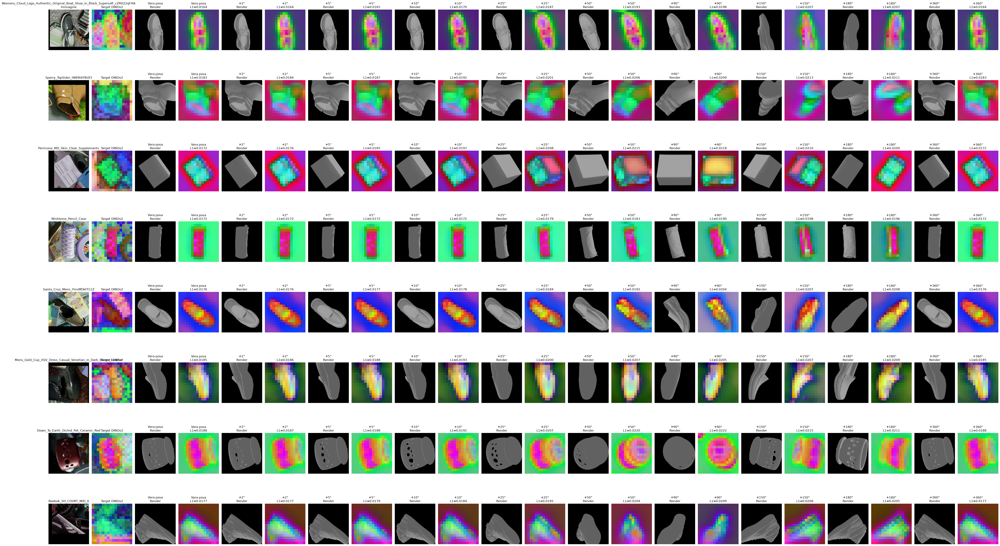

In [14]:
# =========================
# Visualizzazione target vs predictor vs render su sample reali dal batch
# Vera posa + N rotazioni errate (multipli di gradi su asse Y)
# Colonne: [Immagine] [Target DINOv2] [Render, Predictor] x len(rotazioni)
# =========================
batch = next(sample_iter)
actual_bs = batch['image'].shape[0]

N_SHOW = min(8, actual_bs)

# Lista delle rotazioni da testare: 0 = posa vera, poi offset crescenti
ROT_OFFSETS_DEG = [0.0, 2, 5, 10, 25.0, 50.0, 90, 150, 180, 360]
ROT_AXIS = 'y'
ROT_LABELS = ["Vera posa"] + [f"+{d:.0f}°" for d in ROT_OFFSETS_DEG[1:]]

R_offsets = [rotation_matrix(ROT_AXIS, d, device).unsqueeze(0).float() for d in ROT_OFFSETS_DEG]

N_COLS = 2 + 2 * len(ROT_OFFSETS_DEG)   # Immagine + Target + (Render, Predictor) per ogni rotazione
fig, axes = plt.subplots(N_SHOW, N_COLS, figsize=(2.4 * N_COLS, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    # --- Input immagine/maschera ---
    img_i = batch['image'][i].unsqueeze(0).to(device).float()
    mask_i = batch['mask'][i].to(device).float()

    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i

    # --- Camera / posa ---
    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    # --- Context 3D aggregator: per-sample, su device ---
    view_feats_i = batch['view_feats'][i].unsqueeze(0).float().to(device)   # (1, P, N, D)
    view_dirs_i  = batch['view_dirs'][i].unsqueeze(0).float().to(device)    # (1, P, N, 3)
    view_mask_i  = batch['view_mask'][i].unsqueeze(0).bool().to(device)     # (1, P, N)
    point_xyz_i  = batch['point_xyz'][i].unsqueeze(0).float().to(device)    # (1, P, 3)

    # --- centroid / scale: shape forzata (1,3) / (1,) prima di ogni uso ---
    centroid_t = batch['centroid'][i].reshape(-1)[None, :].to(device).float()  # (1, 3)
    scale_t    = batch['scale'][i].reshape(-1)[:1].to(device).float()          # (1,)

    # --- numpy per il render (K, centroid, scale) ---
    K_np = batch['K'][i].cpu().numpy()
    centroid_np = centroid_t.squeeze(0).cpu().numpy()   # (3,), stessa shape corretta usata sopra
    scale_np = float(scale_t.item())

    # --- Maschera a livello di token ---
    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    # --- Target DINOv2 e context 3D (calcolati una sola volta per sample) ---
    with torch.no_grad():
        target = encoder2d(img_t)
        context_t, centers_t = encoder3d.extractFeatures(
            view_feats_i, view_dirs_i, view_mask_i, point_xyz_i
        )
    target_np = target.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    # --- Immagine di sfondo (denormalizzata) ---
    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    # --- Colonna 0: immagine originale ---
    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"{model_name}\nImmagine" if i == 0 else model_name)
    axes[i, 0].axis('off')

    # --- Colonna 1: target DINOv2 ---
    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    print_str = f"{model_name}:"

    # --- Una coppia di colonne (Render, Predictor) per ogni rotazione ---
    for j, (R_off, label) in enumerate(zip(R_offsets, ROT_LABELS)):
        rot_j = torch.matmul(R_off, rot_t)  # se j==0, R_off è identità -> posa vera
        ray_dirs, moment = _generate_rays(K_t, rot_j, trans_t, centroid_t, scale_t)

        with torch.no_grad():
            pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                              context_features=context_t, context_centers=centers_t)
            l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()

        pred_np = pred.squeeze(0).cpu().numpy()
        pred_pca = pca.transform(pred_np)          # stessa PCA del target
        pred_map = to_rgb_map_local(pred_pca)

        # --- Render dell'oggetto con la posa ruotata ---
        R_np = rot_j.squeeze(0).cpu().numpy()
        t_np = trans_t.squeeze(0).cpu().numpy()
        rendered_img = render_gso_object(
            model_name, R_np, t_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )

        col_render = 2 + 2 * j
        col_pred = 2 + 2 * j + 1

        axes[i, col_render].imshow(rendered_img)
        axes[i, col_render].set_title(f"{label}\nRender")
        axes[i, col_render].axis('off')

        axes[i, col_pred].imshow(pred_map)
        axes[i, col_pred].set_title(f"{label}\nL1={l1_pred:.4f}")
        axes[i, col_pred].axis('off')

        print_str += f" | {label} L1={l1_pred:.4f}"

    print(print_str)

plt.tight_layout()
plt.show()

# TEST TRANSLATION (on Val)

Womens_Cloud_Logo_Authentic_Original_Boat_Shoe_in_Black_Supersoft_cZR022qFI4k: | Vera posa L1=0.0164 | +0.02·s x L1=0.0167 | -0.02·s x L1=0.0165 | +0.05·s x L1=0.0176 | -0.05·s x L1=0.0172 | +0.10·s x L1=0.0190 | -0.10·s x L1=0.0188 | +0.25·s x L1=0.0207 | -0.25·s x L1=0.0204 | +0.50·s x L1=0.0206 | -0.50·s x L1=0.0205
Sperry_TopSider_tNB9t6YBUf3: | Vera posa L1=0.0183 | +0.02·s x L1=0.0184 | -0.02·s x L1=0.0184 | +0.05·s x L1=0.0188 | -0.05·s x L1=0.0190 | +0.10·s x L1=0.0197 | -0.10·s x L1=0.0198 | +0.25·s x L1=0.0207 | -0.25·s x L1=0.0209 | +0.50·s x L1=0.0207 | -0.50·s x L1=0.0211
Perricone_MD_Skin_Clear_Supplements: | Vera posa L1=0.0172 | +0.02·s x L1=0.0173 | -0.02·s x L1=0.0173 | +0.05·s x L1=0.0178 | -0.05·s x L1=0.0178 | +0.10·s x L1=0.0189 | -0.10·s x L1=0.0189 | +0.25·s x L1=0.0203 | -0.25·s x L1=0.0199 | +0.50·s x L1=0.0203 | -0.50·s x L1=0.0201
Wishbone_Pencil_Case: | Vera posa L1=0.0172 | +0.02·s x L1=0.0172 | -0.02·s x L1=0.0172 | +0.05·s x L1=0.0175 | -0.05·s x L1=0.01

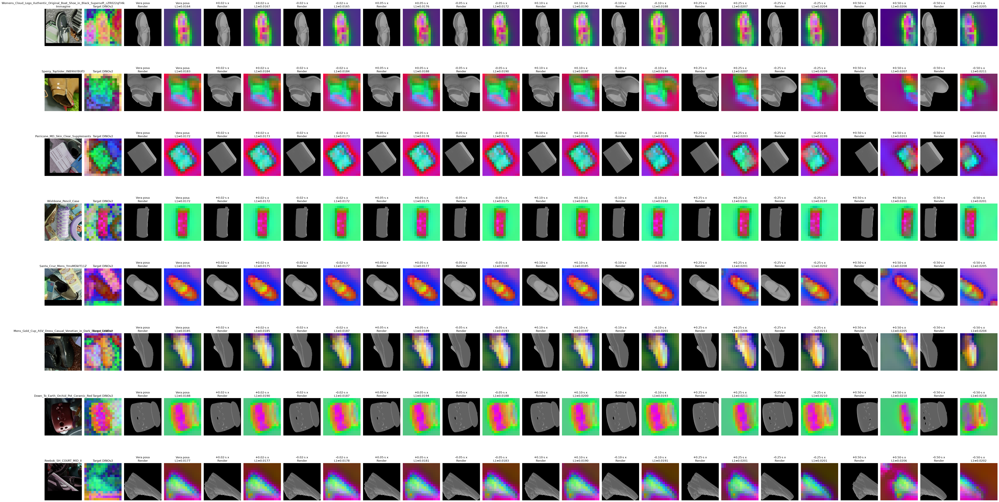

In [15]:
# =========================
# Visualizzazione target vs predictor vs render su sample reali dal batch
# Vera posa + N traslazioni errate (multipli di scala su un asse camera-frame)
# Colonne: [Immagine] [Target DINOv2] [Render, Predictor] x len(traslazioni)
# =========================
# batch = next(sample_iter)
# actual_bs = batch['image'].shape[0]

N_SHOW = min(8, actual_bs)

# --- Configurazione traslazioni ---
TRANS_AXIS = 'x'   # 'x', 'y' o 'z' (camera frame)
AXIS_IDX = {'x': 0, 'y': 1, 'z': 2}[TRANS_AXIS]

TRANS_OFFSETS_FRAC = [0.0, 0.02, -0.02, 0.05, -0.05, 0.1, -0.1, 0.25, -0.25, 0.5, -0.5]
TRANS_LABELS = ["Vera posa"] + [
    f"{'+' if f > 0 else ''}{f:.2f}·s {TRANS_AXIS}" for f in TRANS_OFFSETS_FRAC[1:]
]

N_TRANS = len(TRANS_OFFSETS_FRAC)
N_COLS = 2 + 2 * N_TRANS   # Immagine + Target + (Render, Predictor) per ogni traslazione
fig, axes = plt.subplots(N_SHOW, N_COLS, figsize=(2.4 * N_COLS, 4 * N_SHOW))
if N_SHOW == 1:
    axes = axes[None, :]

for i in range(N_SHOW):
    model_name = batch['model_name'][i]

    # --- Input immagine/maschera ---
    img_i = batch['image'][i].unsqueeze(0).to(device).float()
    mask_i = batch['mask'][i].to(device).float()

    if img_i.min() >= -0.01:
        img_t = (img_i - MEAN_t) / STD_t
    else:
        img_t = img_i

    # --- Camera / posa ---
    K_t = batch['K'][i].unsqueeze(0).to(device).float()
    rot_t = batch['rot_matrix'][i].unsqueeze(0).to(device).float()
    trans_t = batch['trans'][i].unsqueeze(0).to(device).float()

    # --- Context 3D aggregator: per-sample, su device ---
    view_feats_i = batch['view_feats'][i].unsqueeze(0).float().to(device)   # (1, P, N, D)
    view_dirs_i  = batch['view_dirs'][i].unsqueeze(0).float().to(device)    # (1, P, N, 3)
    view_mask_i  = batch['view_mask'][i].unsqueeze(0).bool().to(device)     # (1, P, N)
    point_xyz_i  = batch['point_xyz'][i].unsqueeze(0).float().to(device)    # (1, P, 3)

    # --- centroid / scale: shape forzata (1,3) / (1,) prima di ogni uso ---
    centroid_t = batch['centroid'][i].reshape(-1)[None, :].to(device).float()  # (1, 3)
    scale_t    = batch['scale'][i].reshape(-1)[:1].to(device).float()          # (1,)

    # --- numpy per il render (K, centroid, scale) ---
    K_np = batch['K'][i].cpu().numpy()
    centroid_np = centroid_t.squeeze(0).cpu().numpy()   # (3,)
    scale_np = float(scale_t.item())

    # --- Maschera a livello di token ---
    mask_np = mask_i.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    # --- Target DINOv2 e context 3D (calcolati una sola volta per sample) ---
    with torch.no_grad():
        target = encoder2d(img_t)
        context_t, centers_t = encoder3d.extractFeatures(
            view_feats_i, view_dirs_i, view_mask_i, point_xyz_i
        )
    target_np = target.squeeze(0).cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    # --- Immagine di sfondo (denormalizzata) ---
    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    # --- Colonna 0: immagine originale ---
    axes[i, 0].imshow(bg_img)
    axes[i, 0].set_title(f"{model_name}\nImmagine" if i == 0 else model_name)
    axes[i, 0].axis('off')

    # --- Colonna 1: target DINOv2 ---
    axes[i, 1].imshow(target_map)
    axes[i, 1].set_title("Target DINOv2")
    axes[i, 1].axis('off')

    print_str = f"{model_name}:"

    # --- Una coppia di colonne (Render, Predictor) per ogni traslazione ---
    for j, (offset_frac, label) in enumerate(zip(TRANS_OFFSETS_FRAC, TRANS_LABELS)):
        # Offset assoluto = frazione * scala dell'oggetto, applicato sull'asse scelto
        offset_abs = offset_frac * scale_t  # shape (1,)

        trans_j = trans_t.clone()
        trans_j[:, AXIS_IDX] = trans_j[:, AXIS_IDX] + offset_abs

        ray_dirs, moment = _generate_rays(K_t, rot_t, trans_j, centroid_t, scale_t)

        with torch.no_grad():
            pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                              context_features=context_t, context_centers=centers_t)
            l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()

        pred_np = pred.squeeze(0).cpu().numpy()
        pred_pca = pca.transform(pred_np)          # stessa PCA del target
        pred_map = to_rgb_map_local(pred_pca)

        # --- Render dell'oggetto con la posa traslata ---
        R_np = rot_t.squeeze(0).cpu().numpy()
        t_np = trans_j.squeeze(0).cpu().numpy()
        rendered_img = render_gso_object(
            model_name, R_np, t_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )

        col_render = 2 + 2 * j
        col_pred = 2 + 2 * j + 1

        axes[i, col_render].imshow(rendered_img)
        axes[i, col_render].set_title(f"{label}\nRender")
        axes[i, col_render].axis('off')

        axes[i, col_pred].imshow(pred_map)
        axes[i, col_pred].set_title(f"{label}\nL1={l1_pred:.4f}")
        axes[i, col_pred].axis('off')

        print_str += f" | {label} L1={l1_pred:.4f}"

    print(print_str)  # dentro il loop "for i": una riga per sample, non solo l'ultima

plt.tight_layout()
plt.show()

# TEST INFERENCE

Vera posa: L1=0.017205
Pose 0: L1=0.0183, ΔR=9.436°
Pose 1: L1=0.0183, ΔR=9.923°
Pose 2: L1=0.0186, ΔR=13.398°
Pose 3: L1=0.0187, ΔR=179.782°
Pose 4: L1=0.0188, ΔR=12.286°
Pose 5: L1=0.0190, ΔR=17.003°
Pose 6: L1=0.0190, ΔR=12.339°
Pose 7: L1=0.0190, ΔR=28.850°
Pose 8: L1=0.0191, ΔR=177.630°
Pose 9: L1=0.0191, ΔR=9.807°
Pose 10: L1=0.0191, ΔR=178.840°
Best wrt geodesic distance 9.436°, con L1=0.0183


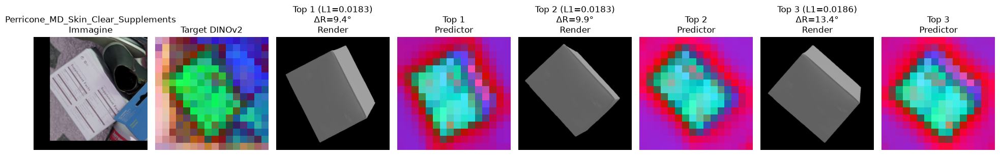

In [16]:
from scipy.spatial.transform import Rotation

## taking the data from a single object in the batch
Object = 2

img = batch['image'][Object].unsqueeze(0).to(device).float()   # (1,3,H,W)
mask = batch['mask'][Object].to(device).float()                 # (H,W)

# --- Auto-detect: immagine gia' normalizzata (mean/std) o raw [0,1]? ---
if img.min() >= -0.01:
    img_t = (img - MEAN_t) / STD_t
else:
    img_t = img  # gia' normalizzata dal dataset

R_real = batch['rot_matrix'][Object].unsqueeze(0).to(device).float()   # world-to-camera
t_real = batch['trans'][Object].unsqueeze(0).to(device).float()
R_real_np = R_real.squeeze(0).cpu().numpy()

# --- centroid / scale: shape forzata (1,3) / (1,) ---
centroid = batch['centroid'][Object].reshape(-1)[None, :].to(device).float()  # (1, 3)
scale    = batch['scale'][Object].reshape(-1)[:1].to(device).float()          # (1,)

# --- Context 3D aggregator, per-sample, su device ---
view_feats_o = batch['view_feats'][Object].unsqueeze(0).float().to(device)   # (1, P, N, D)
view_dirs_o  = batch['view_dirs'][Object].unsqueeze(0).float().to(device)    # (1, P, N, 3)
view_mask_o  = batch['view_mask'][Object].unsqueeze(0).bool().to(device)     # (1, P, N)
point_xyz_o  = batch['point_xyz'][Object].unsqueeze(0).float().to(device)    # (1, P, 3)

K = batch['K'][Object].unsqueeze(0).to(device).float()

mask_np = mask.squeeze().cpu().numpy()
token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)  # da Cell 8
token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()  # (1, N)

# --- Numpy per render ---
K_np = batch['K'][Object].cpu().numpy()
t_real_np = t_real.squeeze(0).cpu().numpy()
centroid_np = centroid.squeeze(0).cpu().numpy()   # (3,), coerente col fix sopra
scale_np = float(scale.item())
model_name = batch['model_name'][Object]

# --- Target DINOv2 e context 3D, calcolati una sola volta (non dipendono dalla posa) ---
with torch.no_grad():
    target = encoder2d(img_t)
    context_t, centers_t = encoder3d.extractFeatures(
        view_feats_o, view_dirs_o, view_mask_o, point_xyz_o
    )

    ray_dirs, moment = _generate_rays(K, R_real, t_real, centroid, scale)
    pred_real = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                           context_features=context_t, context_centers=centers_t)

L1_real = masked_l1_per_sample(pred_real, target, token_mask_t).item()

# --- Immagine di sfondo ---
img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)


def geodesic_distance(R1, R2):
    """Distanza geodetica in gradi tra due matrici di rotazione (o batch di R2)."""
    R_diff = R1.T @ R2
    angle = np.arccos(np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0))
    return np.rad2deg(angle)


# =========================
# Ricerca su pose random, BATCHATA a chunk (niente piu' 1 forward per posa)
# e SENZA tenere in memoria il tensore di predizione per ognuna delle N pose:
# per il ranking basta L1 + geodesic distance, il tensore lo ricalcoliamo
# solo per le top-K alla fine.
# =========================
RANDOM_POSES = 10000
CHUNK = 256  # abbassa se vai in OOM di VRAM

results = []  # ogni elemento: {'R': np (3,3), 'L1': float, 'diff': float}

n_done = 0
while n_done < RANDOM_POSES:
    b = min(CHUNK, RANDOM_POSES - n_done)

    R_chunk_np = Rotation.random(b).as_matrix().astype(np.float32)          # (b, 3, 3)
    R_chunk_t = torch.from_numpy(R_chunk_np).to(device)                    # (b, 3, 3)

    # Context/camera identici per ogni posa del chunk: espansi, non copiati (expand, non repeat)
    K_c = K.expand(b, -1, -1)
    t_c = t_real.expand(b, -1)
    centroid_c = centroid.expand(b, -1)
    scale_c = scale.expand(b)
    context_c = context_t.expand(b, -1, -1)
    centers_c = centers_t.expand(b, -1, -1)
    target_c = target.expand(b, -1, -1)
    token_mask_c = token_mask_t.expand(b, -1)

    ray_dirs_c, moment_c = _generate_rays(K_c, R_chunk_t, t_c, centroid_c, scale_c)

    with torch.no_grad():
        pred_c = predictor(ray_dirs=ray_dirs_c, ray_moments=moment_c,
                            context_features=context_c, context_centers=centers_c)
        l1_c = masked_l1_per_sample(pred_c, target_c, token_mask_c)  # (b,)

    l1_c_np = l1_c.cpu().numpy()
    for k in range(b):
        results.append({
            'R': R_chunk_np[k],
            'L1': float(l1_c_np[k]),
            'diff': geodesic_distance(R_real_np, R_chunk_np[k]),
        })

    n_done += b

print(f"Vera posa: L1={L1_real:.6f}")

results.sort(key=lambda x: x['L1'])
for i, res in enumerate(results[:11]):
    print(f"Pose {i}: L1={res['L1']:.4f}, ΔR={res['diff']:.3f}°")

results_by_diff = sorted(results, key=lambda x: x['diff'])
print(f"Best wrt geodesic distance {results_by_diff[0]['diff']:.3f}°, con L1={results_by_diff[0]['L1']:.4f}")

# =========================
# Plot: immagine, target, e le migliori 3 pose predette rispetto a L1
# (i pred delle top-K vengono ricalcolati qui, non tenuti in memoria da prima)
# =========================
TOP_K = 3
top_results = results[:TOP_K]  # gia' ordinati per L1 crescente

target_np = target.squeeze(0).cpu().numpy()
pca = PCA(n_components=3)
target_pca = pca.fit_transform(target_np)
target_map = to_rgb_map_local(target_pca)

N_COLS = 2 + 2 * TOP_K
fig, axes = plt.subplots(1, N_COLS, figsize=(2.4 * N_COLS, 4))

axes[0].imshow(bg_img)
axes[0].set_title(f"{model_name}\nImmagine")
axes[0].axis('off')

axes[1].imshow(target_map)
axes[1].set_title("Target DINOv2")
axes[1].axis('off')

for j, res in enumerate(top_results):
    R_j = res['R']
    R_j_t = torch.from_numpy(R_j).unsqueeze(0).to(device).float()

    with torch.no_grad():
        ray_dirs_j, moment_j = _generate_rays(K, R_j_t, t_real, centroid, scale)
        pred_j = predictor(ray_dirs=ray_dirs_j, ray_moments=moment_j,
                            context_features=context_t, context_centers=centers_t)

    pred_np = pred_j.squeeze(0).cpu().numpy()
    pred_pca = pca.transform(pred_np)          # stessa PCA del target
    pred_map = to_rgb_map_local(pred_pca)

    rendered_img = render_gso_object(
        model_name, R_j, t_real_np, K_np, img_size=bg_img.shape[:2],
        centroid=centroid_np, scale=scale_np,
    )

    col_render = 2 + 2 * j
    col_pred = 2 + 2 * j + 1

    axes[col_render].imshow(rendered_img)
    axes[col_render].set_title(f"Top {j+1} (L1={res['L1']:.4f})\nΔR={res['diff']:.1f}°\nRender")
    axes[col_render].axis('off')

    axes[col_pred].imshow(pred_map)
    axes[col_pred].set_title(f"Top {j+1}\nPredictor")
    axes[col_pred].axis('off')

plt.tight_layout()
plt.show()

In [19]:
class ConvBNReLU(nn.Sequential):
    def __init__(self, c_in, c_out, kernel=3, stride=1):
        super().__init__(
            nn.Conv2d(c_in, c_out, kernel, stride, padding=kernel // 2, bias=False),
            nn.GroupNorm(32, c_out),
            nn.ReLU(inplace=True),
        )
class BasicResidualBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.GroupNorm(32, channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.GroupNorm(32, channels)
    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)), inplace=True)
        return F.relu(x + self.bn2(self.conv2(y)), inplace=True)
def positional_encoding(length: int, channels: int, device, dtype):
    # Classic sinusoidal positional encoding, same conceptual role as FoundationPose.
    position = torch.arange(length, device=device, dtype=torch.float32)[:, None]
    div = torch.exp(torch.arange(0, channels, 2, device=device, dtype=torch.float32)
                    * (-math.log(10000.0) / channels))
    pe = torch.zeros(length, channels, device=device, dtype=torch.float32)
    pe[:, 0::2] = torch.sin(position * div)
    pe[:, 1::2] = torch.cos(position * div)
    return pe.to(dtype=dtype)
class LatentRefineNet(nn.Module):
    """Same block/channel counts as official FoundationPose RefineNet.
    Its RGB-D encoder starts with 7x7/3x3 stride-2 convolutions; here we instead
    project DINO tokens using 1x1, preserving the 16x16 spatial token grid.
    """
    def __init__(self, token_dim: int = 1024):
        super().__init__()
        self.encodeAB = nn.Sequential(
            ConvBNReLU(token_dim * 2, 256, kernel=1),
            BasicResidualBlock(256),
            BasicResidualBlock(256),
            ConvBNReLU(256, 512, kernel=3, stride=2),
            BasicResidualBlock(512),
            BasicResidualBlock(512),
        )
        # Official FoundationPose uses separate Transformer layers per head.
        self.rot_transformer = nn.TransformerEncoderLayer(
        d_model=512, nhead=4, dim_feedforward=512, batch_first=True)
        self.trans_transformer = nn.TransformerEncoderLayer(
        d_model=512, nhead=4, dim_feedforward=512, batch_first=True)
        self.rot_linear = nn.Linear(512, 3)
        self.trans_linear = nn.Linear(512, 3)
        # Identity update at initialization: lets before/after checks be meaningful.
        nn.init.zeros_(self.rot_linear.weight)
        nn.init.zeros_(self.rot_linear.bias)
        nn.init.zeros_(self.trans_linear.weight)
        nn.init.zeros_(self.trans_linear.bias)
    def forward(self, z_pred: torch.Tensor, z_target: torch.Tensor):
        # [batch_of_hypotheses, 256, token_dim]
        if z_pred.shape != z_target.shape or z_pred.shape[1] != TOKEN_COUNT:
            raise ValueError(f'Expected matching [N,{TOKEN_COUNT},C], got '
            f'{tuple(z_pred.shape)} vs {tuple(z_target.shape)}')
        H = W = GRID
        a = z_pred.transpose(1, 2).reshape(-1, z_pred.shape[-1], H, W)
        b = z_target.transpose(1, 2).reshape(-1, z_target.shape[-1], H, W)
        # Shared weights, like encodeA(torch.cat([A,B],dim=0)) in FoundationPose.
        ab = self.encodeAB(torch.cat((a, b), dim=1))
        seq = ab.flatten(2).transpose(1, 2)  # [N,64,512]
        seq = seq + positional_encoding(seq.shape[1], 512, seq.device, seq.dtype)[None]
        out_rot = self.rot_linear(self.rot_transformer(seq).mean(dim=1))
        out_trans = self.trans_linear(self.trans_transformer(seq).mean(dim=1))
        # Output is a normalized delta; no tanh clamp (global rotations up to pi).
        return out_rot, out_trans

In [20]:
# IMPORTING TRAINED REFINER
REFINER_CKPT = "/experiments/riccardop02/outputs/refinement_GT_GROUPNORM/best.pt"


checkpoint = torch.load(
    REFINER_CKPT,
    map_location="cpu",
    weights_only=False,
)

refiner = LatentRefineNet(
    token_dim=encoder2d.output_dim[-1]
).to(device)

refiner.load_state_dict(checkpoint["refiner"], strict=True)
refiner.eval().requires_grad_(False)

# Recuperiamo le normalizzazioni effettive del training
rot_normalizer = checkpoint["arch"]["rot_normalizer"]
trans_normalizer = checkpoint["arch"]["trans_normalizer"]

encoder2d.eval().requires_grad_(False)
encoder3d.eval().requires_grad_(False)
predictor.eval().requires_grad_(False)

print(f"Refiner loaded: {REFINER_CKPT}")
print(f"Training step: {checkpoint['step']}")
print(f"Rotation normalizer: {rot_normalizer}")
print(f"Translation normalizer: {trans_normalizer}")


Refiner loaded: /experiments/riccardop02/outputs/refinement_GT_GROUPNORM/best.pt
Training step: 19000
Rotation normalizer: 3.141592653589793
Translation normalizer: 100.0



[OBJ 0] Womens_Cloud_Logo_Authentic_Original_Boat_Shoe_in_Black_Supersoft_cZR022qFI4k: 120 pose campionate | GT L1=0.01639
[OBJ 0] Best geodesic: 18.476° | L1=0.01956

[OBJ 0] TOP 1 — Neural refinement
  Step 0: L1=0.01956 | ΔR=18.48° | Δt=29.95
  Step 1: L1=0.01683 | ΔR=5.98° | Δt=5.42
  Step 2: L1=0.01661 | ΔR=5.12° | Δt=5.10

[OBJ 0] TOP 2 — Neural refinement
  Step 0: L1=0.01995 | ΔR=175.89° | Δt=29.95
  Step 1: L1=0.02069 | ΔR=178.86° | Δt=13.30
  Step 2: L1=0.02065 | ΔR=177.24° | Δt=18.62

[OBJ 0] TOP 3 — Neural refinement
  Step 0: L1=0.01996 | ΔR=40.11° | Δt=29.95
  Step 1: L1=0.01721 | ΔR=7.33° | Δt=9.03
  Step 2: L1=0.01671 | ΔR=6.55° | Δt=4.85


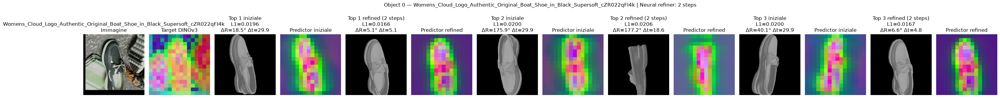


[OBJ 1] Sperry_TopSider_tNB9t6YBUf3: 120 pose campionate | GT L1=0.01829
[OBJ 1] Best geodesic: 19.204° | L1=0.02066

[OBJ 1] TOP 1 — Neural refinement
  Step 0: L1=0.02066 | ΔR=19.20° | Δt=56.92
  Step 1: L1=0.01910 | ΔR=10.12° | Δt=39.81
  Step 2: L1=0.01846 | ΔR=7.47° | Δt=26.51

[OBJ 1] TOP 2 — Neural refinement
  Step 0: L1=0.02083 | ΔR=93.86° | Δt=56.92
  Step 1: L1=0.02075 | ΔR=79.67° | Δt=42.28
  Step 2: L1=0.02060 | ΔR=42.97° | Δt=36.88

[OBJ 1] TOP 3 — Neural refinement
  Step 0: L1=0.02085 | ΔR=103.62° | Δt=56.92
  Step 1: L1=0.02076 | ΔR=126.40° | Δt=45.76
  Step 2: L1=0.01986 | ΔR=142.00° | Δt=43.80


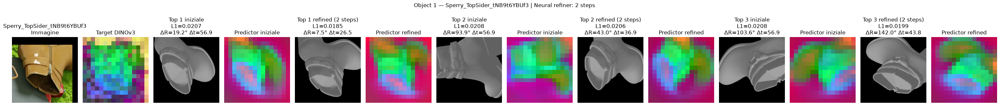


[OBJ 2] Perricone_MD_Skin_Clear_Supplements: 120 pose campionate | GT L1=0.01720
[OBJ 2] Best geodesic: 23.237° | L1=0.02006

[OBJ 2] TOP 1 — Neural refinement
  Step 0: L1=0.01951 | ΔR=103.12° | Δt=100.48
  Step 1: L1=0.01952 | ΔR=93.22° | Δt=30.92
  Step 2: L1=0.01990 | ΔR=93.92° | Δt=41.05

[OBJ 2] TOP 2 — Neural refinement
  Step 0: L1=0.01958 | ΔR=71.31° | Δt=100.48
  Step 1: L1=0.01971 | ΔR=85.68° | Δt=34.71
  Step 2: L1=0.01991 | ΔR=89.98° | Δt=33.72

[OBJ 2] TOP 3 — Neural refinement
  Step 0: L1=0.01961 | ΔR=173.90° | Δt=100.48
  Step 1: L1=0.01904 | ΔR=173.86° | Δt=45.91
  Step 2: L1=0.01901 | ΔR=175.59° | Δt=13.82


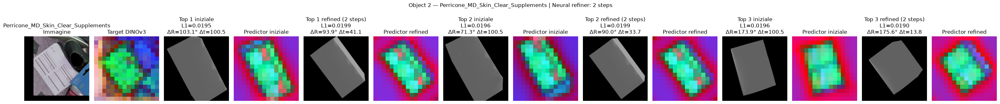


[OBJ 3] Wishbone_Pencil_Case: 120 pose campionate | GT L1=0.01719
[OBJ 3] Best geodesic: 31.328° | L1=0.01885

[OBJ 3] TOP 1 — Neural refinement
  Step 0: L1=0.01843 | ΔR=172.00° | Δt=34.79
  Step 1: L1=0.01795 | ΔR=179.58° | Δt=11.50
  Step 2: L1=0.01795 | ΔR=179.75° | Δt=10.28

[OBJ 3] TOP 2 — Neural refinement
  Step 0: L1=0.01844 | ΔR=179.50° | Δt=34.79
  Step 1: L1=0.01802 | ΔR=176.92° | Δt=20.25
  Step 2: L1=0.01799 | ΔR=177.60° | Δt=18.74

[OBJ 3] TOP 3 — Neural refinement
  Step 0: L1=0.01854 | ΔR=76.80° | Δt=34.79
  Step 1: L1=0.01803 | ΔR=69.48° | Δt=24.04
  Step 2: L1=0.01803 | ΔR=69.57° | Δt=21.33


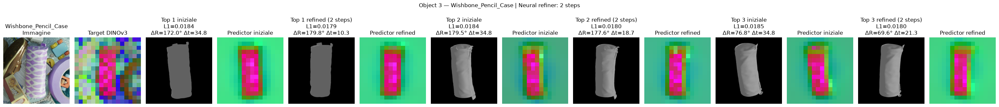


[OBJ 4] Santa_Cruz_Mens_YmsMDkFf11Z: 120 pose campionate | GT L1=0.01757
[OBJ 4] Best geodesic: 31.779° | L1=0.01972

[OBJ 4] TOP 1 — Neural refinement
  Step 0: L1=0.01967 | ΔR=115.75° | Δt=18.05
  Step 1: L1=0.01979 | ΔR=157.94° | Δt=24.77
  Step 2: L1=0.01987 | ΔR=177.63° | Δt=30.83

[OBJ 4] TOP 2 — Neural refinement
  Step 0: L1=0.01968 | ΔR=47.27° | Δt=18.05
  Step 1: L1=0.01880 | ΔR=12.98° | Δt=8.62
  Step 2: L1=0.01784 | ΔR=9.38° | Δt=9.59

[OBJ 4] TOP 3 — Neural refinement
  Step 0: L1=0.01972 | ΔR=31.78° | Δt=18.05
  Step 1: L1=0.01795 | ΔR=7.31° | Δt=10.28
  Step 2: L1=0.01762 | ΔR=5.87° | Δt=9.55


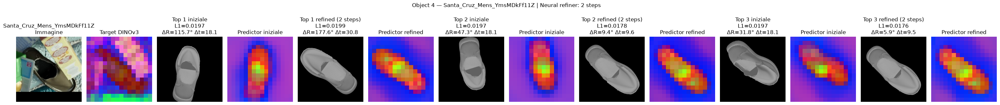


[OBJ 5] Mens_Gold_Cup_ASV_Dress_Casual_Venetian_in_Dark_Brown_Leather: 120 pose campionate | GT L1=0.01853
[OBJ 5] Best geodesic: 42.734° | L1=0.02052

[OBJ 5] TOP 1 — Neural refinement
  Step 0: L1=0.02022 | ΔR=61.19° | Δt=41.26
  Step 1: L1=0.01940 | ΔR=17.34° | Δt=33.94
  Step 2: L1=0.01867 | ΔR=13.23° | Δt=12.76

[OBJ 5] TOP 2 — Neural refinement
  Step 0: L1=0.02034 | ΔR=156.88° | Δt=41.26
  Step 1: L1=0.01981 | ΔR=167.70° | Δt=15.69
  Step 2: L1=0.01979 | ΔR=176.87° | Δt=38.41

[OBJ 5] TOP 3 — Neural refinement
  Step 0: L1=0.02038 | ΔR=85.53° | Δt=41.26
  Step 1: L1=0.02026 | ΔR=121.15° | Δt=22.24
  Step 2: L1=0.02025 | ΔR=126.45° | Δt=29.28


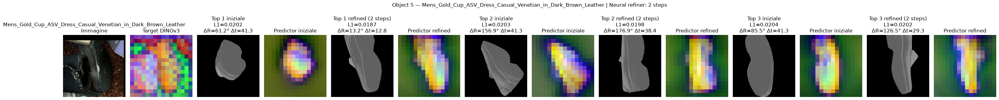


[OBJ 6] Down_To_Earth_Orchid_Pot_Ceramic_Red: 120 pose campionate | GT L1=0.01878
[OBJ 6] Best geodesic: 22.104° | L1=0.01921

[OBJ 6] TOP 1 — Neural refinement
  Step 0: L1=0.01916 | ΔR=45.14° | Δt=78.97
  Step 1: L1=0.01906 | ΔR=38.98° | Δt=20.30
  Step 2: L1=0.01908 | ΔR=39.05° | Δt=26.29

[OBJ 6] TOP 2 — Neural refinement
  Step 0: L1=0.01917 | ΔR=75.68° | Δt=78.97
  Step 1: L1=0.01905 | ΔR=75.19° | Δt=17.27
  Step 2: L1=0.01917 | ΔR=77.70° | Δt=23.59

[OBJ 6] TOP 3 — Neural refinement
  Step 0: L1=0.01921 | ΔR=22.10° | Δt=78.97
  Step 1: L1=0.01903 | ΔR=14.07° | Δt=18.95
  Step 2: L1=0.01904 | ΔR=8.30° | Δt=21.85


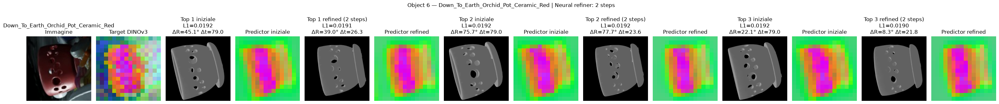


[OBJ 7] Reebok_SH_COURT_MID_II: 120 pose campionate | GT L1=0.01767
[OBJ 7] Best geodesic: 37.033° | L1=0.02121

[OBJ 7] TOP 1 — Neural refinement
  Step 0: L1=0.01985 | ΔR=174.99° | Δt=58.35
  Step 1: L1=0.01989 | ΔR=177.13° | Δt=52.25
  Step 2: L1=0.01987 | ΔR=177.75° | Δt=50.02

[OBJ 7] TOP 2 — Neural refinement
  Step 0: L1=0.02013 | ΔR=158.52° | Δt=58.35
  Step 1: L1=0.01994 | ΔR=173.02° | Δt=55.35
  Step 2: L1=0.02006 | ΔR=174.18° | Δt=52.03

[OBJ 7] TOP 3 — Neural refinement
  Step 0: L1=0.02018 | ΔR=165.31° | Δt=58.35
  Step 1: L1=0.02022 | ΔR=176.44° | Δt=50.39
  Step 2: L1=0.02002 | ΔR=175.90° | Δt=47.02


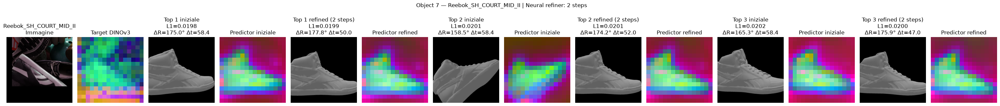


[OBJ 8] Squirrel: 120 pose campionate | GT L1=0.01802
[OBJ 8] Best geodesic: 9.467° | L1=0.01874

[OBJ 8] TOP 1 — Neural refinement
  Step 0: L1=0.01874 | ΔR=9.47° | Δt=90.20
  Step 1: L1=0.01866 | ΔR=6.75° | Δt=43.52
  Step 2: L1=0.01813 | ΔR=4.82° | Δt=31.38

[OBJ 8] TOP 2 — Neural refinement
  Step 0: L1=0.01919 | ΔR=22.71° | Δt=90.20
  Step 1: L1=0.01821 | ΔR=4.65° | Δt=64.21
  Step 2: L1=0.01819 | ΔR=4.24° | Δt=47.10

[OBJ 8] TOP 3 — Neural refinement
  Step 0: L1=0.02009 | ΔR=153.87° | Δt=90.20
  Step 1: L1=0.02032 | ΔR=177.03° | Δt=54.92
  Step 2: L1=0.02039 | ΔR=168.43° | Δt=41.54


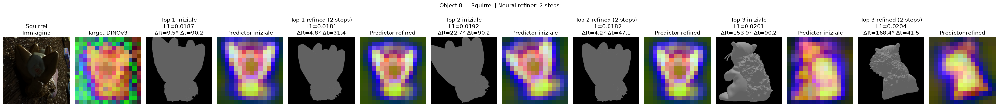


[OBJ 9] Cream_Tieks_Italian_Leather_Ballet_Flats: 120 pose campionate | GT L1=0.01675
[OBJ 9] Best geodesic: 33.776° | L1=0.01917

[OBJ 9] TOP 1 — Neural refinement
  Step 0: L1=0.01917 | ΔR=33.78° | Δt=35.46
  Step 1: L1=0.01851 | ΔR=5.85° | Δt=18.18
  Step 2: L1=0.01691 | ΔR=3.48° | Δt=4.86

[OBJ 9] TOP 2 — Neural refinement
  Step 0: L1=0.02006 | ΔR=165.95° | Δt=35.46
  Step 1: L1=0.01995 | ΔR=176.85° | Δt=26.05
  Step 2: L1=0.01973 | ΔR=176.64° | Δt=12.58

[OBJ 9] TOP 3 — Neural refinement
  Step 0: L1=0.02043 | ΔR=43.26° | Δt=35.46
  Step 1: L1=0.01746 | ΔR=7.94° | Δt=21.51
  Step 2: L1=0.01679 | ΔR=4.05° | Δt=11.10


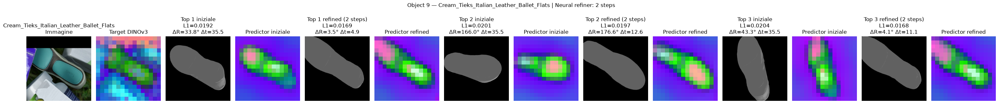

In [21]:

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pytorch3d.transforms import so3_exp_map
import math
# ============================================================
# CONFIG
# ============================================================

N_DIRS = 12
N_ROLL = 10
TOP_K = 3
REFINE_STEPS = 2

# Per confrontare esattamente il vecchio esperimento,
# True usa la traduzione GT come nel codice gradient descent.
# False usa t0, come durante il training del refiner.
USE_GT_TRANSLATION = False

def geodesic_distance(R1, R2):
    R_diff = R1.T @ R2
    angle = np.arccos(np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0))
    return np.rad2deg(angle)


def skew_np(v):
    return np.array([
        [0, -v[2], v[1]],
        [v[2], 0, -v[0]],
        [-v[1], v[0], 0]
    ])


def rotation_matrix_axis_angle_np(axis, angle):
    axis = axis / np.linalg.norm(axis)
    K_ = skew_np(axis)
    return np.eye(3) + np.sin(angle) * K_ + (1 - np.cos(angle)) * (K_ @ K_)


def rotation_from_direction_np(direction, forward=np.array([0.0, 0.0, 1.0])):
    direction = direction / np.linalg.norm(direction)
    v = np.cross(forward, direction)
    c = np.dot(forward, direction)
    s = np.linalg.norm(v)
    if s < 1e-8:
        if c > 0:
            return np.eye(3)
        orth = np.array([1.0, 0.0, 0.0]) if abs(forward[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
        axis = np.cross(forward, orth)
        return rotation_matrix_axis_angle_np(axis, np.pi)
    K_ = skew_np(v)
    return np.eye(3) + K_ + K_ @ K_ * ((1 - c) / (s ** 2))


def fibonacci_sphere(n):
    points = []
    golden_angle = np.pi * (3.0 - np.sqrt(5.0))
    for i in range(n):
        y = 1 - (i / float(max(n - 1, 1))) * 2
        radius = np.sqrt(max(0.0, 1 - y * y))
        theta = golden_angle * i
        x = np.cos(theta) * radius
        z = np.sin(theta) * radius
        points.append([x, y, z])
    return np.array(points)


directions_global = fibonacci_sphere(N_DIRS)
golden_ratio = (1 + np.sqrt(5)) / 2


def geodesic_distance(R1, R2):
    R_diff = R1.T @ R2
    angle = np.arccos(
        np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0)
    )
    return np.rad2deg(angle)


def process_object(OBJ, verbose=True):

    # ========================================================
    # 1. DATA
    # ========================================================

    img = batch["image"][OBJ].unsqueeze(0).to(device).float()
    mask = batch["mask"][OBJ].to(device).float()

    if img.min() >= -0.01:
        img_t = (img - MEAN_t) / STD_t
    else:
        img_t = img

    R_real = batch["rot_matrix"][OBJ].reshape(1, 3, 3).to(device).float()
    t_real = batch["trans"][OBJ].reshape(1, 3).to(device).float()

    R_real_np = R_real[0].cpu().numpy()
    t_real_np = t_real[0].cpu().numpy()

    centroid = batch["centroid"][OBJ].reshape(1, 3).to(device).float()
    scale = batch["scale"][OBJ].reshape(1).to(device).float()

    K = batch["K"][OBJ].reshape(1, 3, 3).to(device).float()
    K_np = K[0].cpu().numpy()

    model_name = batch["model_name"][OBJ]

    # Traslazione iniziale
    if USE_GT_TRANSLATION:
        t_init = t_real.clone()
    elif "t0" in batch:
        t_init = batch["t0"][OBJ].reshape(1, 3).to(device).float()
    else:
        # Fallback: stesso t_real usato nel vecchio test
        t_init = t_real.clone()
        print(
            f"[OBJ {OBJ}] WARNING: t0 non presente, "
            "uso t_real. Per un test realistico aggiungi t0."
        )

    mask_np = mask.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(
        mask_np, grid_size=GRID_SIZE
    )
    token_mask_t = torch.from_numpy(
        token_mask_np
    ).reshape(1, -1).to(device).float()

    view_feats_o = batch["view_feats"][OBJ].unsqueeze(0).to(device).float()
    view_dirs_o = batch["view_dirs"][OBJ].unsqueeze(0).to(device).float()
    view_mask_o = batch["view_mask"][OBJ].unsqueeze(0).to(device).bool()
    point_xyz_o = batch["point_xyz"][OBJ].unsqueeze(0).to(device).float()

    # ========================================================
    # 2. ENCODE TARGET AND CONTEXT
    # ========================================================

    with torch.no_grad():

        target = encoder2d(img_t)

        context_t, centers_t = encoder3d.extractFeatures(
            view_feats_o,
            view_dirs_o,
            view_mask_o,
            point_xyz_o,
        )

        # GT reference per confronto (diagnostica)
        ray_dirs, moment = _generate_rays(
            K, R_real, t_real, centroid, scale
        )

        pred_real = predictor(
            ray_dirs=ray_dirs,
            ray_moments=moment,
            context_features=context_t,
            context_centers=centers_t,
        )

        L1_real = masked_l1_per_sample(
            pred_real, target, token_mask_t
        ).item()

    # ========================================================
    # 3. SAMPLING: STESSO DEL GRADIENT DESCENT
    # ========================================================

    results = []

    with torch.no_grad():

        for direction in directions_global:

            R_dir = rotation_from_direction_np(direction)

            for ri in range(N_ROLL):

                psi = 2 * np.pi * (
                    (ri * golden_ratio) % 1.0
                )

                R_roll = rotation_matrix_axis_angle_np(
                    direction, psi
                )

                R = R_roll @ R_dir

                R_t = torch.from_numpy(R).reshape(
                    1, 3, 3
                ).to(device).float()

                ray_dirs, moment = _generate_rays(
                    K, R_t, t_init, centroid, scale
                )

                pred = predictor(
                    ray_dirs=ray_dirs,
                    ray_moments=moment,
                    context_features=context_t,
                    context_centers=centers_t,
                )

                l1 = masked_l1_per_sample(
                    pred, target, token_mask_t
                ).item()

                results.append({
                    "R": R,
                    "L1": l1,
                    "diff": geodesic_distance(R_real_np, R),
                })

    results.sort(key=lambda x: x["L1"])
    results_by_diff = sorted(results, key=lambda x: x["diff"])

    if verbose:
        print(
            f"\n[OBJ {OBJ}] {model_name}: "
            f"{len(results)} pose campionate "
            f"| GT L1={L1_real:.5f}"
        )

        print(
            f"[OBJ {OBJ}] Best geodesic: "
            f"{results_by_diff[0]['diff']:.3f}° "
            f"| L1={results_by_diff[0]['L1']:.5f}"
        )

    top_candidates = results[:TOP_K]

    # ========================================================
    # 4. NEURAL REFINEMENT
    # ========================================================

    refined_results = []

    for j, cand in enumerate(top_candidates):

        R_current = torch.from_numpy(
            cand["R"]
        ).reshape(1, 3, 3).to(device).float()

        t_current = t_init.clone()

        R_initial_np = cand["R"].copy()
        t_initial_np = t_current[0].cpu().numpy().copy()

        with torch.no_grad():

            # Predictor iniziale
            ray_dirs, moment = _generate_rays(
                K, R_current, t_current, centroid, scale
            )

            pred_initial = predictor(
                ray_dirs=ray_dirs,
                ray_moments=moment,
                context_features=context_t,
                context_centers=centers_t,
            )

            pred_init_np = pred_initial[0].float().cpu().numpy()

            history = [{
                "step": 0,
                "L1": cand["L1"],
                "rot_err": cand["diff"],
                "trans_err": torch.linalg.norm(
                    t_current - t_real
                ).item(),
            }]

            # ------------------------------------------------
            # Iterative neural refinement
            # ------------------------------------------------

            for step in range(1, REFINE_STEPS + 1):

                ray_dirs, moment = _generate_rays(
                    K,
                    R_current,
                    t_current,
                    centroid,
                    scale,
                )

                z_pred = predictor(
                    ray_dirs=ray_dirs,
                    ray_moments=moment,
                    context_features=context_t,
                    context_centers=centers_t,
                )

                r_norm, t_norm = refiner(z_pred, target)

                # Denormalizzazione come nel training
                delta_r = r_norm.float() * rot_normalizer
                delta_t = t_norm.float() * trans_normalizer

                # LEFT multiplication come nel training
                R_delta = so3_exp_map(delta_r)

                R_current = R_delta @ R_current
                t_current = t_current + delta_t

                # Valuta la posa aggiornata
                ray_dirs, moment = _generate_rays(
                    K,
                    R_current,
                    t_current,
                    centroid,
                    scale,
                )

                pred_updated = predictor(
                    ray_dirs=ray_dirs,
                    ray_moments=moment,
                    context_features=context_t,
                    context_centers=centers_t,
                )

                l1_step = masked_l1_per_sample(
                    pred_updated, target, token_mask_t
                ).item()

                rot_err = geodesic_distance(
                    R_real_np,
                    R_current[0].cpu().numpy(),
                )

                trans_err = torch.linalg.norm(
                    t_current - t_real
                ).item()

                history.append({
                    "step": step,
                    "L1": l1_step,
                    "rot_err": rot_err,
                    "trans_err": trans_err,
                })

        R_final_np = R_current[0].cpu().numpy()
        t_final_np = t_current[0].cpu().numpy()
        pred_final_np = pred_updated[0].float().cpu().numpy()

        refined_results.append({
            "R_init": R_initial_np,
            "t_init": t_initial_np,
            "R_final": R_final_np,
            "t_final": t_final_np,
            "L1_init": history[0]["L1"],
            "L1_final": history[-1]["L1"],
            "diff_init": history[0]["rot_err"],
            "diff_final": history[-1]["rot_err"],
            "trans_init": history[0]["trans_err"],
            "trans_final": history[-1]["trans_err"],
            "pred_init_np": pred_init_np,
            "pred_final_np": pred_final_np,
            "history": history,
        })

        if verbose:
            print(f"\n[OBJ {OBJ}] TOP {j+1} — Neural refinement")

            for h in history:
                print(
                    f"  Step {h['step']}: "
                    f"L1={h['L1']:.5f} | "
                    f"ΔR={h['rot_err']:.2f}° | "
                    f"Δt={h['trans_err']:.2f}"
                )

    # ========================================================
    # 5. PLOT: STESSO FORMATO DEL VECCHIO ESPERIMENTO
    # ========================================================

    img_denorm = (
        img_t * STD_t + MEAN_t
    ).clamp(0, 1)

    bg_img = (
        img_denorm[0]
        .permute(1, 2, 0)
        .cpu()
        .numpy() * 255
    ).astype(np.uint8)

    target_np = target[0].float().cpu().numpy()

    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    centroid_np = centroid[0].cpu().numpy()
    scale_np = float(scale.item())

    N_COLS = 2 + 4 * TOP_K

    fig, axes = plt.subplots(
        1, N_COLS,
        figsize=(2.2 * N_COLS, 4),
    )

    axes[0].imshow(bg_img)
    axes[0].set_title(f"{model_name}\nImmagine")
    axes[0].axis("off")

    axes[1].imshow(target_map)
    axes[1].set_title("Target DINOv3")
    axes[1].axis("off")

    for j, res in enumerate(refined_results):

        base_col = 2 + 4 * j

        # Render iniziale
        render_init = render_gso_object(
            model_name,
            res["R_init"],
            res["t_init"],
            K_np,
            img_size=bg_img.shape[:2],
            centroid=centroid_np,
            scale=scale_np,
        )

        pred_init_map = to_rgb_map_local(
            pca.transform(res["pred_init_np"])
        )

        axes[base_col].imshow(render_init)
        axes[base_col].set_title(
            f"Top {j+1} iniziale\n"
            f"L1={res['L1_init']:.4f}\n"
            f"ΔR={res['diff_init']:.1f}° "
            f"Δt={res['trans_init']:.1f}"
        )
        axes[base_col].axis("off")

        axes[base_col + 1].imshow(pred_init_map)
        axes[base_col + 1].set_title("Predictor iniziale")
        axes[base_col + 1].axis("off")

        # Render finale
        render_final = render_gso_object(
            model_name,
            res["R_final"],
            res["t_final"],
            K_np,
            img_size=bg_img.shape[:2],
            centroid=centroid_np,
            scale=scale_np,
        )

        pred_final_map = to_rgb_map_local(
            pca.transform(res["pred_final_np"])
        )

        axes[base_col + 2].imshow(render_final)
        axes[base_col + 2].set_title(
            f"Top {j+1} refined ({REFINE_STEPS} steps)\n"
            f"L1={res['L1_final']:.4f}\n"
            f"ΔR={res['diff_final']:.1f}° "
            f"Δt={res['trans_final']:.1f}"
        )
        axes[base_col + 2].axis("off")

        axes[base_col + 3].imshow(pred_final_map)
        axes[base_col + 3].set_title("Predictor refined")
        axes[base_col + 3].axis("off")

    plt.suptitle(
        f"Object {OBJ} — {model_name} "
        f"| Neural refiner: {REFINE_STEPS} steps"
    )

    plt.tight_layout()
    plt.show()

    return {
        "OBJ": OBJ,
        "model_name": model_name,
        "L1_real": L1_real,
        "results_sorted": results,
        "refined_results": refined_results,
    }


# ============================================================
# 6. ESEGUI SU TUTTO IL BATCH
# ============================================================

actual_bs = batch["image"].shape[0]

all_objects_results = []

for OBJ in range(actual_bs):
    res = process_object(OBJ)
    all_objects_results.append(res)



[OBJ 0] Womens_Cloud_Logo_Authentic_Original_Boat_Shoe_in_Black_Supersoft_cZR022qFI4k: 120 pose campionate | GT L1=0.01639
[OBJ 0] Best geodesic: 18.476° | L1=0.01956

[OBJ 0] TOP 1 — Neural refinement
  Step 0: L1=0.01956 | ΔR=18.48° | Δt=29.95
  Step 1: L1=0.01676 | ΔR=5.98° | Δt=4.58
  Step 2: L1=0.01654 | ΔR=5.16° | Δt=4.82
  Step 3: L1=0.01645 | ΔR=4.89° | Δt=5.61
  Step 4: L1=0.01642 | ΔR=4.82° | Δt=6.57
  Step 5: L1=0.01641 | ΔR=4.82° | Δt=7.60
  Step 6: L1=0.01641 | ΔR=4.89° | Δt=8.71
  Step 7: L1=0.01641 | ΔR=4.96° | Δt=9.84
  Step 8: L1=0.01641 | ΔR=5.06° | Δt=10.98

[OBJ 0] TOP 2 — Neural refinement
  Step 0: L1=0.01995 | ΔR=175.89° | Δt=29.95
  Step 1: L1=0.02068 | ΔR=178.86° | Δt=13.07
  Step 2: L1=0.02065 | ΔR=177.30° | Δt=19.05
  Step 3: L1=0.02021 | ΔR=170.22° | Δt=25.81
  Step 4: L1=0.02008 | ΔR=157.71° | Δt=26.69
  Step 5: L1=0.02000 | ΔR=167.81° | Δt=35.28
  Step 6: L1=0.02006 | ΔR=164.35° | Δt=42.71
  Step 7: L1=0.02001 | ΔR=167.54° | Δt=53.58
  Step 8: L1=0.02002 

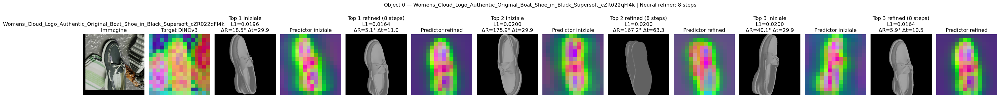


[OBJ 1] Sperry_TopSider_tNB9t6YBUf3: 120 pose campionate | GT L1=0.01829
[OBJ 1] Best geodesic: 19.204° | L1=0.02066

[OBJ 1] TOP 1 — Neural refinement
  Step 0: L1=0.02066 | ΔR=19.20° | Δt=56.92
  Step 1: L1=0.01875 | ΔR=10.12° | Δt=35.33
  Step 2: L1=0.01842 | ΔR=8.02° | Δt=25.70
  Step 3: L1=0.01832 | ΔR=6.63° | Δt=23.58
  Step 4: L1=0.01828 | ΔR=5.53° | Δt=22.43
  Step 5: L1=0.01824 | ΔR=4.61° | Δt=21.85
  Step 6: L1=0.01823 | ΔR=3.87° | Δt=21.52
  Step 7: L1=0.01822 | ΔR=3.28° | Δt=21.46
  Step 8: L1=0.01823 | ΔR=2.84° | Δt=21.53

[OBJ 1] TOP 2 — Neural refinement
  Step 0: L1=0.02083 | ΔR=93.86° | Δt=56.92
  Step 1: L1=0.02078 | ΔR=79.67° | Δt=38.59
  Step 2: L1=0.02058 | ΔR=44.36° | Δt=31.68
  Step 3: L1=0.01978 | ΔR=11.36° | Δt=22.12
  Step 4: L1=0.01839 | ΔR=9.13° | Δt=5.56
  Step 5: L1=0.01834 | ΔR=6.92° | Δt=4.61
  Step 6: L1=0.01829 | ΔR=5.45° | Δt=3.62
  Step 7: L1=0.01826 | ΔR=4.42° | Δt=2.80
  Step 8: L1=0.01825 | ΔR=3.67° | Δt=2.11

[OBJ 1] TOP 3 — Neural refinement
  

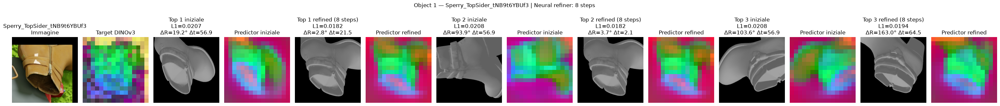


[OBJ 2] Perricone_MD_Skin_Clear_Supplements: 120 pose campionate | GT L1=0.01720
[OBJ 2] Best geodesic: 23.237° | L1=0.02006

[OBJ 2] TOP 1 — Neural refinement
  Step 0: L1=0.01951 | ΔR=103.12° | Δt=100.48
  Step 1: L1=0.01974 | ΔR=93.22° | Δt=12.83
  Step 2: L1=0.01986 | ΔR=94.11° | Δt=80.03
  Step 3: L1=0.01977 | ΔR=92.90° | Δt=146.88
  Step 4: L1=0.01967 | ΔR=91.89° | Δt=191.18
  Step 5: L1=0.01968 | ΔR=91.07° | Δt=217.27
  Step 6: L1=0.01967 | ΔR=90.75° | Δt=230.20
  Step 7: L1=0.01965 | ΔR=90.44° | Δt=237.31
  Step 8: L1=0.01963 | ΔR=90.31° | Δt=241.90

[OBJ 2] TOP 2 — Neural refinement
  Step 0: L1=0.01958 | ΔR=71.31° | Δt=100.48
  Step 1: L1=0.01983 | ΔR=85.68° | Δt=14.66
  Step 2: L1=0.01986 | ΔR=89.71° | Δt=70.67
  Step 3: L1=0.01979 | ΔR=91.36° | Δt=131.43
  Step 4: L1=0.01967 | ΔR=91.61° | Δt=177.96
  Step 5: L1=0.01968 | ΔR=91.12° | Δt=207.53
  Step 6: L1=0.01968 | ΔR=90.65° | Δt=224.13
  Step 7: L1=0.01967 | ΔR=90.45° | Δt=233.42
  Step 8: L1=0.01964 | ΔR=90.29° | Δt=239.

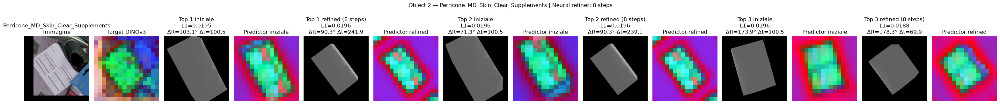


[OBJ 3] Wishbone_Pencil_Case: 120 pose campionate | GT L1=0.01719
[OBJ 3] Best geodesic: 31.328° | L1=0.01885

[OBJ 3] TOP 1 — Neural refinement
  Step 0: L1=0.01843 | ΔR=172.00° | Δt=34.79
  Step 1: L1=0.01797 | ΔR=179.58° | Δt=11.14
  Step 2: L1=0.01795 | ΔR=179.74° | Δt=10.36
  Step 3: L1=0.01793 | ΔR=179.48° | Δt=10.14
  Step 4: L1=0.01792 | ΔR=179.32° | Δt=10.22
  Step 5: L1=0.01791 | ΔR=179.18° | Δt=10.53
  Step 6: L1=0.01790 | ΔR=179.06° | Δt=10.97
  Step 7: L1=0.01790 | ΔR=178.97° | Δt=11.45
  Step 8: L1=0.01790 | ΔR=178.92° | Δt=12.01

[OBJ 3] TOP 2 — Neural refinement
  Step 0: L1=0.01844 | ΔR=179.50° | Δt=34.79
  Step 1: L1=0.01800 | ΔR=176.92° | Δt=18.92
  Step 2: L1=0.01799 | ΔR=177.55° | Δt=17.39
  Step 3: L1=0.01797 | ΔR=177.99° | Δt=15.93
  Step 4: L1=0.01796 | ΔR=178.36° | Δt=14.55
  Step 5: L1=0.01795 | ΔR=178.70° | Δt=13.32
  Step 6: L1=0.01794 | ΔR=178.93° | Δt=12.12
  Step 7: L1=0.01793 | ΔR=179.15° | Δt=10.99
  Step 8: L1=0.01793 | ΔR=179.32° | Δt=9.91

[OBJ 3] T

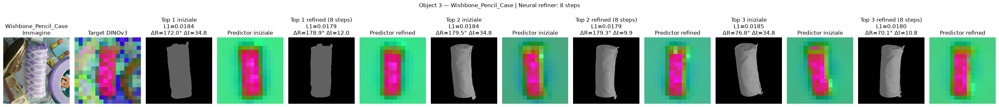


[OBJ 4] Santa_Cruz_Mens_YmsMDkFf11Z: 120 pose campionate | GT L1=0.01757
[OBJ 4] Best geodesic: 31.779° | L1=0.01972

[OBJ 4] TOP 1 — Neural refinement
  Step 0: L1=0.01967 | ΔR=115.75° | Δt=18.05
  Step 1: L1=0.01980 | ΔR=157.94° | Δt=25.10
  Step 2: L1=0.01987 | ΔR=177.61° | Δt=31.20
  Step 3: L1=0.01962 | ΔR=169.40° | Δt=33.98
  Step 4: L1=0.01977 | ΔR=179.00° | Δt=34.03
  Step 5: L1=0.01979 | ΔR=170.56° | Δt=34.08
  Step 6: L1=0.01985 | ΔR=179.05° | Δt=34.15
  Step 7: L1=0.01976 | ΔR=170.27° | Δt=34.92
  Step 8: L1=0.01980 | ΔR=179.43° | Δt=34.56

[OBJ 4] TOP 2 — Neural refinement
  Step 0: L1=0.01968 | ΔR=47.27° | Δt=18.05
  Step 1: L1=0.01876 | ΔR=12.98° | Δt=8.46
  Step 2: L1=0.01781 | ΔR=9.39° | Δt=9.46
  Step 3: L1=0.01761 | ΔR=7.80° | Δt=8.62
  Step 4: L1=0.01753 | ΔR=6.64° | Δt=7.44
  Step 5: L1=0.01749 | ΔR=5.71° | Δt=6.16
  Step 6: L1=0.01750 | ΔR=4.99° | Δt=4.79
  Step 7: L1=0.01749 | ΔR=4.43° | Δt=3.56
  Step 8: L1=0.01749 | ΔR=3.90° | Δt=2.70

[OBJ 4] TOP 3 — Neural re

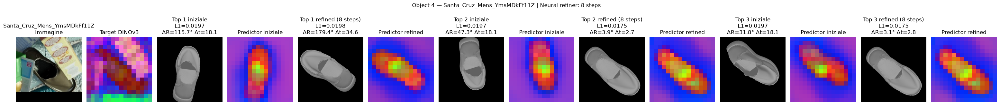


[OBJ 5] Mens_Gold_Cup_ASV_Dress_Casual_Venetian_in_Dark_Brown_Leather: 120 pose campionate | GT L1=0.01853
[OBJ 5] Best geodesic: 42.734° | L1=0.02052

[OBJ 5] TOP 1 — Neural refinement
  Step 0: L1=0.02022 | ΔR=61.19° | Δt=41.26
  Step 1: L1=0.01939 | ΔR=17.34° | Δt=33.58
  Step 2: L1=0.01863 | ΔR=13.21° | Δt=14.18
  Step 3: L1=0.01862 | ΔR=12.00° | Δt=16.65
  Step 4: L1=0.01863 | ΔR=11.16° | Δt=19.17
  Step 5: L1=0.01866 | ΔR=10.49° | Δt=21.78
  Step 6: L1=0.01866 | ΔR=9.93° | Δt=24.30
  Step 7: L1=0.01867 | ΔR=9.44° | Δt=26.86
  Step 8: L1=0.01868 | ΔR=9.00° | Δt=29.33

[OBJ 5] TOP 2 — Neural refinement
  Step 0: L1=0.02034 | ΔR=156.88° | Δt=41.26
  Step 1: L1=0.01981 | ΔR=167.70° | Δt=16.71
  Step 2: L1=0.01979 | ΔR=177.06° | Δt=42.54
  Step 3: L1=0.01974 | ΔR=178.61° | Δt=50.23
  Step 4: L1=0.01969 | ΔR=176.46° | Δt=61.17
  Step 5: L1=0.01968 | ΔR=174.86° | Δt=67.22
  Step 6: L1=0.01965 | ΔR=173.64° | Δt=73.95
  Step 7: L1=0.01964 | ΔR=172.70° | Δt=78.68
  Step 8: L1=0.01964 | ΔR

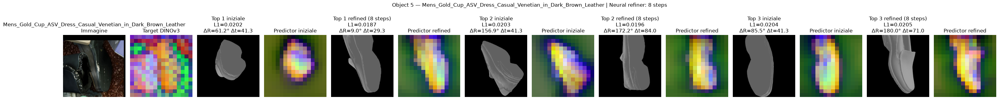


[OBJ 6] Down_To_Earth_Orchid_Pot_Ceramic_Red: 120 pose campionate | GT L1=0.01878
[OBJ 6] Best geodesic: 22.104° | L1=0.01921

[OBJ 6] TOP 1 — Neural refinement
  Step 0: L1=0.01916 | ΔR=45.14° | Δt=78.97
  Step 1: L1=0.01933 | ΔR=38.98° | Δt=5.84
  Step 2: L1=0.01916 | ΔR=37.98° | Δt=40.92
  Step 3: L1=0.01910 | ΔR=38.12° | Δt=64.42
  Step 4: L1=0.01905 | ΔR=37.92° | Δt=79.47
  Step 5: L1=0.01902 | ΔR=37.65° | Δt=91.75
  Step 6: L1=0.01903 | ΔR=37.41° | Δt=101.66
  Step 7: L1=0.01904 | ΔR=37.12° | Δt=110.59
  Step 8: L1=0.01904 | ΔR=36.78° | Δt=117.95

[OBJ 6] TOP 2 — Neural refinement
  Step 0: L1=0.01917 | ΔR=75.68° | Δt=78.97
  Step 1: L1=0.01950 | ΔR=75.19° | Δt=10.95
  Step 2: L1=0.01920 | ΔR=76.47° | Δt=35.51
  Step 3: L1=0.01905 | ΔR=80.38° | Δt=51.55
  Step 4: L1=0.01900 | ΔR=83.29° | Δt=64.39
  Step 5: L1=0.01898 | ΔR=85.44° | Δt=75.66
  Step 6: L1=0.01897 | ΔR=87.04° | Δt=84.90
  Step 7: L1=0.01895 | ΔR=88.34° | Δt=92.66
  Step 8: L1=0.01895 | ΔR=89.43° | Δt=98.97

[OBJ 6] 

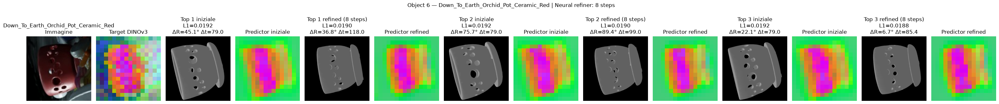


[OBJ 7] Reebok_SH_COURT_MID_II: 120 pose campionate | GT L1=0.01767
[OBJ 7] Best geodesic: 37.033° | L1=0.02121

[OBJ 7] TOP 1 — Neural refinement
  Step 0: L1=0.01985 | ΔR=174.99° | Δt=58.35
  Step 1: L1=0.01989 | ΔR=177.13° | Δt=51.20
  Step 2: L1=0.01985 | ΔR=177.69° | Δt=49.20
  Step 3: L1=0.01984 | ΔR=177.39° | Δt=48.13
  Step 4: L1=0.01980 | ΔR=176.88° | Δt=47.59
  Step 5: L1=0.01982 | ΔR=176.45° | Δt=47.20
  Step 6: L1=0.01984 | ΔR=176.22° | Δt=46.85
  Step 7: L1=0.01985 | ΔR=176.16° | Δt=46.49
  Step 8: L1=0.01985 | ΔR=176.10° | Δt=46.08

[OBJ 7] TOP 2 — Neural refinement
  Step 0: L1=0.02013 | ΔR=158.52° | Δt=58.35
  Step 1: L1=0.01994 | ΔR=173.02° | Δt=54.87
  Step 2: L1=0.02005 | ΔR=174.36° | Δt=51.02
  Step 3: L1=0.01988 | ΔR=175.24° | Δt=47.36
  Step 4: L1=0.01985 | ΔR=175.62° | Δt=45.93
  Step 5: L1=0.01982 | ΔR=175.82° | Δt=45.31
  Step 6: L1=0.01984 | ΔR=175.87° | Δt=45.02
  Step 7: L1=0.01985 | ΔR=175.86° | Δt=44.83
  Step 8: L1=0.01986 | ΔR=175.82° | Δt=44.64

[OBJ 7

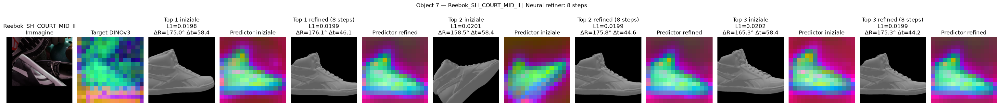


[OBJ 8] Squirrel: 120 pose campionate | GT L1=0.01802
[OBJ 8] Best geodesic: 9.467° | L1=0.01874

[OBJ 8] TOP 1 — Neural refinement
  Step 0: L1=0.01874 | ΔR=9.47° | Δt=90.20
  Step 1: L1=0.01905 | ΔR=6.75° | Δt=32.21
  Step 2: L1=0.01808 | ΔR=4.78° | Δt=16.06
  Step 3: L1=0.01802 | ΔR=4.22° | Δt=17.41
  Step 4: L1=0.01803 | ΔR=3.99° | Δt=18.56
  Step 5: L1=0.01805 | ΔR=3.94° | Δt=19.64
  Step 6: L1=0.01805 | ΔR=3.98° | Δt=20.68
  Step 7: L1=0.01806 | ΔR=4.10° | Δt=21.71
  Step 8: L1=0.01807 | ΔR=4.25° | Δt=22.70

[OBJ 8] TOP 2 — Neural refinement
  Step 0: L1=0.01919 | ΔR=22.71° | Δt=90.20
  Step 1: L1=0.01827 | ΔR=4.65° | Δt=57.54
  Step 2: L1=0.01813 | ΔR=4.30° | Δt=41.37
  Step 3: L1=0.01808 | ΔR=3.85° | Δt=40.89
  Step 4: L1=0.01810 | ΔR=3.64° | Δt=40.90
  Step 5: L1=0.01810 | ΔR=3.61° | Δt=40.76
  Step 6: L1=0.01810 | ΔR=3.67° | Δt=40.60
  Step 7: L1=0.01810 | ΔR=3.79° | Δt=40.20
  Step 8: L1=0.01810 | ΔR=3.91° | Δt=39.81

[OBJ 8] TOP 3 — Neural refinement
  Step 0: L1=0.02009 |

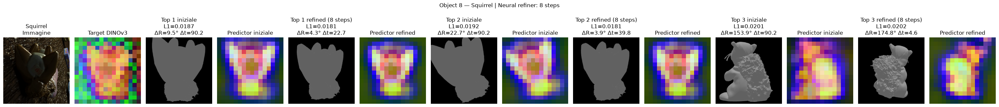


[OBJ 9] Cream_Tieks_Italian_Leather_Ballet_Flats: 120 pose campionate | GT L1=0.01675
[OBJ 9] Best geodesic: 33.776° | L1=0.01917

[OBJ 9] TOP 1 — Neural refinement
  Step 0: L1=0.01917 | ΔR=33.78° | Δt=35.46
  Step 1: L1=0.01840 | ΔR=5.85° | Δt=16.78
  Step 2: L1=0.01713 | ΔR=3.54° | Δt=7.57
  Step 3: L1=0.01687 | ΔR=2.22° | Δt=7.04
  Step 4: L1=0.01680 | ΔR=1.35° | Δt=6.60
  Step 5: L1=0.01675 | ΔR=0.81° | Δt=6.23
  Step 6: L1=0.01673 | ΔR=0.84° | Δt=5.93
  Step 7: L1=0.01674 | ΔR=1.22° | Δt=5.72
  Step 8: L1=0.01673 | ΔR=1.68° | Δt=5.50

[OBJ 9] TOP 2 — Neural refinement
  Step 0: L1=0.02006 | ΔR=165.95° | Δt=35.46
  Step 1: L1=0.01996 | ΔR=176.85° | Δt=25.37
  Step 2: L1=0.01966 | ΔR=176.69° | Δt=14.27
  Step 3: L1=0.01928 | ΔR=176.66° | Δt=27.17
  Step 4: L1=0.01929 | ΔR=176.66° | Δt=33.57
  Step 5: L1=0.01929 | ΔR=177.31° | Δt=39.40
  Step 6: L1=0.01927 | ΔR=177.57° | Δt=43.90
  Step 7: L1=0.01927 | ΔR=177.75° | Δt=47.83
  Step 8: L1=0.01926 | ΔR=178.00° | Δt=51.10

[OBJ 9] TOP 

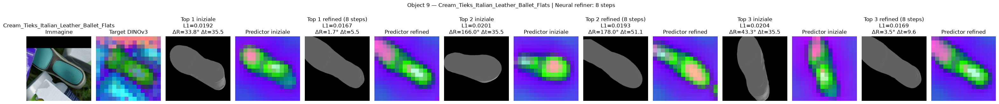

In [24]:


import numpy as np

import torch

import torch.nn.functional as F

import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from pytorch3d.transforms import so3_exp_map

import math

# ============================================================

# CONFIG

# ============================================================



N_DIRS = 12

N_ROLL = 10

TOP_K = 3

REFINE_STEPS = 8



# Per confrontare esattamente il vecchio esperimento,

# True usa la traduzione GT come nel codice gradient descent.

# False usa t0, come durante il training del refiner.

USE_GT_TRANSLATION = False



def geodesic_distance(R1, R2):

    R_diff = R1.T @ R2

    angle = np.arccos(np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0))

    return np.rad2deg(angle)





def skew_np(v):

    return np.array([

        [0, -v[2], v[1]],

        [v[2], 0, -v[0]],

        [-v[1], v[0], 0]

    ])





def rotation_matrix_axis_angle_np(axis, angle):

    axis = axis / np.linalg.norm(axis)

    K_ = skew_np(axis)

    return np.eye(3) + np.sin(angle) * K_ + (1 - np.cos(angle)) * (K_ @ K_)





def rotation_from_direction_np(direction, forward=np.array([0.0, 0.0, 1.0])):

    direction = direction / np.linalg.norm(direction)

    v = np.cross(forward, direction)

    c = np.dot(forward, direction)

    s = np.linalg.norm(v)

    if s < 1e-8:

        if c > 0:

            return np.eye(3)

        orth = np.array([1.0, 0.0, 0.0]) if abs(forward[0]) < 0.9 else np.array([0.0, 1.0, 0.0])

        axis = np.cross(forward, orth)

        return rotation_matrix_axis_angle_np(axis, np.pi)

    K_ = skew_np(v)

    return np.eye(3) + K_ + K_ @ K_ * ((1 - c) / (s ** 2))





def fibonacci_sphere(n):

    points = []

    golden_angle = np.pi * (3.0 - np.sqrt(5.0))

    for i in range(n):

        y = 1 - (i / float(max(n - 1, 1))) * 2

        radius = np.sqrt(max(0.0, 1 - y * y))

        theta = golden_angle * i

        x = np.cos(theta) * radius

        z = np.sin(theta) * radius

        points.append([x, y, z])

    return np.array(points)





directions_global = fibonacci_sphere(N_DIRS)

golden_ratio = (1 + np.sqrt(5)) / 2





def geodesic_distance(R1, R2):

    R_diff = R1.T @ R2

    angle = np.arccos(

        np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0)

    )

    return np.rad2deg(angle)





def process_object(OBJ, verbose=True):



    # ========================================================

    # 1. DATA

    # ========================================================



    img = batch["image"][OBJ].unsqueeze(0).to(device).float()

    mask = batch["mask"][OBJ].to(device).float()



    if img.min() >= -0.01:

        img_t = (img - MEAN_t) / STD_t

    else:

        img_t = img



    R_real = batch["rot_matrix"][OBJ].reshape(1, 3, 3).to(device).float()

    t_real = batch["trans"][OBJ].reshape(1, 3).to(device).float()



    R_real_np = R_real[0].cpu().numpy()

    t_real_np = t_real[0].cpu().numpy()



    centroid = batch["centroid"][OBJ].reshape(1, 3).to(device).float()

    scale = batch["scale"][OBJ].reshape(1).to(device).float()



    K = batch["K"][OBJ].reshape(1, 3, 3).to(device).float()

    K_np = K[0].cpu().numpy()



    model_name = batch["model_name"][OBJ]



    # Traslazione iniziale

    if USE_GT_TRANSLATION:

        t_init = t_real.clone()

    elif "t0" in batch:

        t_init = batch["t0"][OBJ].reshape(1, 3).to(device).float()

    else:

        # Fallback: stesso t_real usato nel vecchio test

        t_init = t_real.clone()

        print(

f"[OBJ {OBJ}] WARNING: t0 non presente, "

            "uso t_real. Per un test realistico aggiungi t0."

        )



    mask_np = mask.squeeze().cpu().numpy()

    token_mask_np = pixel_mask_to_token_mask(

        mask_np, grid_size=GRID_SIZE

    )

    token_mask_t = torch.from_numpy(

        token_mask_np

    ).reshape(1, -1).to(device).float()



    view_feats_o = batch["view_feats"][OBJ].unsqueeze(0).to(device).float()

    view_dirs_o = batch["view_dirs"][OBJ].unsqueeze(0).to(device).float()

    view_mask_o = batch["view_mask"][OBJ].unsqueeze(0).to(device).bool()

    point_xyz_o = batch["point_xyz"][OBJ].unsqueeze(0).to(device).float()



    # ========================================================

    # 2. ENCODE TARGET AND CONTEXT

    # ========================================================



    with torch.no_grad():



        target = encoder2d(img_t)



        context_t, centers_t = encoder3d.extractFeatures(

            view_feats_o,

            view_dirs_o,

            view_mask_o,

            point_xyz_o,

        )



        # GT reference per confronto (diagnostica)

        ray_dirs, moment = _generate_rays(

            K, R_real, t_real, centroid, scale

        )



        pred_real = predictor(

ray_dirs=ray_dirs,

ray_moments=moment,

context_features=context_t,

context_centers=centers_t,

        )



        L1_real = masked_l1_per_sample(

            pred_real, target, token_mask_t

        ).item()



    # ========================================================

    # 3. SAMPLING: STESSO DEL GRADIENT DESCENT

    # ========================================================



    results = []



    with torch.no_grad():



        for direction in directions_global:



            R_dir = rotation_from_direction_np(direction)



            for ri in range(N_ROLL):



                psi = 2 * np.pi * (

                    (ri * golden_ratio) % 1.0

                )



                R_roll = rotation_matrix_axis_angle_np(

                    direction, psi

                )



                R = R_roll @ R_dir



                R_t = torch.from_numpy(R).reshape(

                    1, 3, 3

                ).to(device).float()



                ray_dirs, moment = _generate_rays(

                    K, R_t, t_init, centroid, scale

                )



                pred = predictor(

ray_dirs=ray_dirs,

ray_moments=moment,

context_features=context_t,

context_centers=centers_t,

                )



                l1 = masked_l1_per_sample(

                    pred, target, token_mask_t

                ).item()



                results.append({

                    "R": R,

                    "L1": l1,

                    "diff": geodesic_distance(R_real_np, R),

                })



    results.sort(key=lambda x: x["L1"])

    results_by_diff = sorted(results, key=lambda x: x["diff"])



    if verbose:

        print(

f"\n[OBJ {OBJ}] {model_name}: "

f"{len(results)} pose campionate "

f"| GT L1={L1_real:.5f}"

        )



        print(

f"[OBJ {OBJ}] Best geodesic: "

f"{results_by_diff[0]['diff']:.3f}° "

f"| L1={results_by_diff[0]['L1']:.5f}"

        )



    top_candidates = results[:TOP_K]



    # ========================================================

    # 4. NEURAL REFINEMENT

    # ========================================================



    refined_results = []



    for j, cand in enumerate(top_candidates):



        R_current = torch.from_numpy(

            cand["R"]

        ).reshape(1, 3, 3).to(device).float()



        t_current = t_init.clone()



        R_initial_np = cand["R"].copy()

        t_initial_np = t_current[0].cpu().numpy().copy()



        with torch.no_grad():



            # Predictor iniziale

            ray_dirs, moment = _generate_rays(

                K, R_current, t_current, centroid, scale

            )



            pred_initial = predictor(

ray_dirs=ray_dirs,

ray_moments=moment,

context_features=context_t,

context_centers=centers_t,

            )



            pred_init_np = pred_initial[0].float().cpu().numpy()



            history = [{

                "step": 0,

                "L1": cand["L1"],

                "rot_err": cand["diff"],

                "trans_err": torch.linalg.norm(

                    t_current - t_real

                ).item(),

            }]



            # ------------------------------------------------

            # Iterative neural refinement

            # ------------------------------------------------



            for step in range(1, REFINE_STEPS + 1):



                ray_dirs, moment = _generate_rays(

                    K,

                    R_current,

                    t_current,

                    centroid,

                    scale,

                )



                z_pred = predictor(

ray_dirs=ray_dirs,

ray_moments=moment,

context_features=context_t,

context_centers=centers_t,

                )



                r_norm, t_norm = refiner(z_pred, target)



                # Denormalizzazione come nel training

                delta_r = r_norm.float() * rot_normalizer

                delta_t = t_norm.float() * scale



                # LEFT multiplication come nel training

                R_delta = so3_exp_map(delta_r)



                R_current = R_delta @ R_current

                t_current = t_current + delta_t



                # Valuta la posa aggiornata

                ray_dirs, moment = _generate_rays(

                    K,

                    R_current,

                    t_current,

                    centroid,

                    scale,

                )



                pred_updated = predictor(

ray_dirs=ray_dirs,

ray_moments=moment,

context_features=context_t,

context_centers=centers_t,

                )



                l1_step = masked_l1_per_sample(

                    pred_updated, target, token_mask_t

                ).item()



                rot_err = geodesic_distance(

                    R_real_np,

                    R_current[0].cpu().numpy(),

                )



                trans_err = torch.linalg.norm(

                    t_current - t_real

                ).item()



                history.append({

                    "step": step,

                    "L1": l1_step,

                    "rot_err": rot_err,

                    "trans_err": trans_err,

                })



        R_final_np = R_current[0].cpu().numpy()

        t_final_np = t_current[0].cpu().numpy()

        pred_final_np = pred_updated[0].float().cpu().numpy()



        refined_results.append({

            "R_init": R_initial_np,

            "t_init": t_initial_np,

            "R_final": R_final_np,

            "t_final": t_final_np,

            "L1_init": history[0]["L1"],

            "L1_final": history[-1]["L1"],

            "diff_init": history[0]["rot_err"],

            "diff_final": history[-1]["rot_err"],

            "trans_init": history[0]["trans_err"],

            "trans_final": history[-1]["trans_err"],

            "pred_init_np": pred_init_np,

            "pred_final_np": pred_final_np,

            "history": history,

        })



        if verbose:

            print(f"\n[OBJ {OBJ}] TOP {j+1} — Neural refinement")



            for h in history:

                print(

f"  Step {h['step']}: "

f"L1={h['L1']:.5f} | "

f"ΔR={h['rot_err']:.2f}° | "

f"Δt={h['trans_err']:.2f}"

                )



    # ========================================================

    # 5. PLOT: STESSO FORMATO DEL VECCHIO ESPERIMENTO

    # ========================================================



    img_denorm = (

        img_t * STD_t + MEAN_t

    ).clamp(0, 1)



    bg_img = (

        img_denorm[0]

        .permute(1, 2, 0)

        .cpu()

        .numpy() * 255

    ).astype(np.uint8)



    target_np = target[0].float().cpu().numpy()



    pca = PCA(n_components=3)

    target_pca = pca.fit_transform(target_np)

    target_map = to_rgb_map_local(target_pca)



    centroid_np = centroid[0].cpu().numpy()

    scale_np = float(scale.item())



    N_COLS = 2 + 4 * TOP_K



    fig, axes = plt.subplots(

        1, N_COLS,

figsize=(2.2 * N_COLS, 4),

    )



    axes[0].imshow(bg_img)

    axes[0].set_title(f"{model_name}\nImmagine")

    axes[0].axis("off")



    axes[1].imshow(target_map)

    axes[1].set_title("Target DINOv3")

    axes[1].axis("off")



    for j, res in enumerate(refined_results):



        base_col = 2 + 4 * j



        # Render iniziale

        render_init = render_gso_object(

            model_name,

            res["R_init"],

            res["t_init"],

            K_np,

img_size=bg_img.shape[:2],

centroid=centroid_np,

scale=scale_np,

        )



        pred_init_map = to_rgb_map_local(

            pca.transform(res["pred_init_np"])

        )



        axes[base_col].imshow(render_init)

        axes[base_col].set_title(

f"Top {j+1} iniziale\n"

f"L1={res['L1_init']:.4f}\n"

f"ΔR={res['diff_init']:.1f}° "

f"Δt={res['trans_init']:.1f}"

        )

        axes[base_col].axis("off")



        axes[base_col + 1].imshow(pred_init_map)

        axes[base_col + 1].set_title("Predictor iniziale")

        axes[base_col + 1].axis("off")



        # Render finale

        render_final = render_gso_object(

            model_name,

            res["R_final"],

            res["t_final"],

            K_np,

img_size=bg_img.shape[:2],

centroid=centroid_np,

scale=scale_np,

        )



        pred_final_map = to_rgb_map_local(

            pca.transform(res["pred_final_np"])

        )



        axes[base_col + 2].imshow(render_final)

        axes[base_col + 2].set_title(

f"Top {j+1} refined ({REFINE_STEPS} steps)\n"

f"L1={res['L1_final']:.4f}\n"

f"ΔR={res['diff_final']:.1f}° "

f"Δt={res['trans_final']:.1f}"

        )

        axes[base_col + 2].axis("off")



        axes[base_col + 3].imshow(pred_final_map)

        axes[base_col + 3].set_title("Predictor refined")

        axes[base_col + 3].axis("off")



    plt.suptitle(

f"Object {OBJ} — {model_name} "

f"| Neural refiner: {REFINE_STEPS} steps"

    )



    plt.tight_layout()

    plt.show()



    return {

        "OBJ": OBJ,

        "model_name": model_name,

        "L1_real": L1_real,

        "results_sorted": results,

        "refined_results": refined_results,

    }





# ============================================================

# 6. ESEGUI SU TUTTO IL BATCH

# ============================================================



actual_bs = batch["image"].shape[0]



all_objects_results = []



for OBJ in range(actual_bs):

    res = process_object(OBJ)

    all_objects_results.append(res)


[OBJ 0] Womens_Cloud_Logo_Authentic_Original_Boat_Shoe_in_Black_Supersoft_cZR022qFI4k: campionate 400 pose | Best Pose (R real) L1=0.0167
[OBJ 0] Best wrt geodesic distance 15.313°, con L1=0.0184
    step 0: loss=0.018363, grad_norm=0.010247
    step 20: loss=0.016769, grad_norm=0.004118
    step 40: loss=0.016741, grad_norm=0.003933
    step 60: loss=0.016719, grad_norm=0.002351
    step 80: loss=0.016715, grad_norm=0.000611
    step 100: loss=0.016715, grad_norm=0.000473
    step 120: loss=0.016715, grad_norm=0.000098
    step 140: loss=0.016715, grad_norm=0.000066
[OBJ 0] Refine: L1 0.0184 -> 0.0167 | ΔR 15.31° -> 1.24° | step usati: 145
    step 0: loss=0.019189, grad_norm=0.007298
    step 20: loss=0.017448, grad_norm=0.008365
    step 40: loss=0.016768, grad_norm=0.003212
    step 60: loss=0.016732, grad_norm=0.004187
    step 80: loss=0.016715, grad_norm=0.003488
    step 100: loss=0.016713, grad_norm=0.001278
    step 120: loss=0.016713, grad_norm=0.000323
    step 140: loss=0.

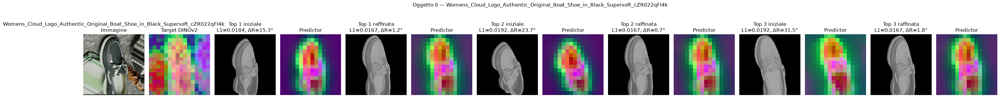

[OBJ 1] Sperry_TopSider_tNB9t6YBUf3: campionate 400 pose | Best Pose (R real) L1=0.0187
[OBJ 1] Best wrt geodesic distance 12.659°, con L1=0.0191
    step 0: loss=0.019111, grad_norm=0.007187
    step 20: loss=0.018651, grad_norm=0.001574
    step 40: loss=0.018645, grad_norm=0.001442
    step 60: loss=0.018642, grad_norm=0.001156
    step 80: loss=0.018641, grad_norm=0.000350
    step 100: loss=0.018641, grad_norm=0.000138
    step 120: loss=0.018641, grad_norm=0.000044
[OBJ 1] Refine: L1 0.0191 -> 0.0186 | ΔR 12.66° -> 4.16° | step usati: 126
    step 0: loss=0.020076, grad_norm=0.003801
    step 20: loss=0.018753, grad_norm=0.006403
    step 40: loss=0.018667, grad_norm=0.003120
    step 60: loss=0.018646, grad_norm=0.001436
    step 80: loss=0.018643, grad_norm=0.000620
    step 100: loss=0.018642, grad_norm=0.000169
    step 120: loss=0.018642, grad_norm=0.000081
    step 140: loss=0.018642, grad_norm=0.000034
[OBJ 1] Refine: L1 0.0201 -> 0.0186 | ΔR 13.32° -> 3.92° | step usati: 

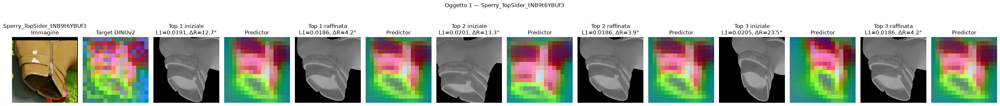

[OBJ 2] Perricone_MD_Skin_Clear_Supplements: campionate 400 pose | Best Pose (R real) L1=0.0174
[OBJ 2] Best wrt geodesic distance 22.488°, con L1=0.0205
    step 0: loss=0.019529, grad_norm=0.011309
    step 20: loss=0.018776, grad_norm=0.005987
    step 40: loss=0.018701, grad_norm=0.001390
    step 60: loss=0.018690, grad_norm=0.001917
    step 80: loss=0.018687, grad_norm=0.000607
    step 100: loss=0.018687, grad_norm=0.000578
    step 120: loss=0.018687, grad_norm=0.000195
    step 140: loss=0.018687, grad_norm=0.000007
[OBJ 2] Refine: L1 0.0195 -> 0.0187 | ΔR 179.52° -> 178.10° | step usati: 146
    step 0: loss=0.019892, grad_norm=0.006555
    step 20: loss=0.018756, grad_norm=0.003400
    step 40: loss=0.018764, grad_norm=0.004299
    step 60: loss=0.018736, grad_norm=0.001783
    step 80: loss=0.018730, grad_norm=0.001176
    step 100: loss=0.018730, grad_norm=0.000646
    step 120: loss=0.018730, grad_norm=0.000250
    step 140: loss=0.018730, grad_norm=0.000051
[OBJ 2] Refi

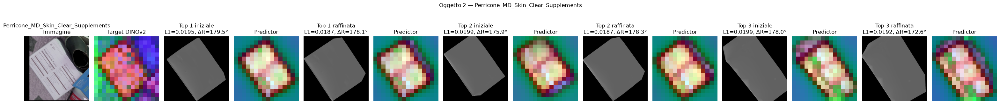

[OBJ 3] Wishbone_Pencil_Case: campionate 400 pose | Best Pose (R real) L1=0.0175
[OBJ 3] Best wrt geodesic distance 29.765°, con L1=0.0187
    step 0: loss=0.018389, grad_norm=0.002671
    step 20: loss=0.018381, grad_norm=0.001962
    step 40: loss=0.018375, grad_norm=0.001123
    step 60: loss=0.018375, grad_norm=0.000635
    step 80: loss=0.018375, grad_norm=0.000237
    step 100: loss=0.018375, grad_norm=0.000085
[OBJ 3] Refine: L1 0.0184 -> 0.0184 | ΔR 167.95° -> 170.40° | step usati: 114
    step 0: loss=0.018530, grad_norm=0.002187
    step 20: loss=0.018434, grad_norm=0.000957
    step 40: loss=0.018379, grad_norm=0.001253
    step 60: loss=0.018366, grad_norm=0.001513
    step 80: loss=0.018361, grad_norm=0.000682
    step 100: loss=0.018361, grad_norm=0.000327
    step 120: loss=0.018361, grad_norm=0.000077
    step 140: loss=0.018361, grad_norm=0.000032
[OBJ 3] Refine: L1 0.0185 -> 0.0184 | ΔR 155.97° -> 167.93° | step usati: 148
    step 0: loss=0.018558, grad_norm=0.001835

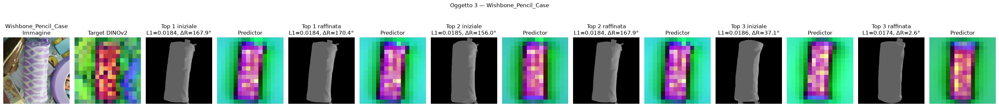

[OBJ 4] Santa_Cruz_Mens_YmsMDkFf11Z: campionate 400 pose | Best Pose (R real) L1=0.0179
[OBJ 4] Best wrt geodesic distance 14.890°, con L1=0.0183
    step 0: loss=0.018339, grad_norm=0.002091
    step 20: loss=0.017905, grad_norm=0.000970
    step 40: loss=0.017822, grad_norm=0.003142
    step 60: loss=0.017812, grad_norm=0.001922
    step 80: loss=0.017811, grad_norm=0.001082
    step 100: loss=0.017811, grad_norm=0.000335
    step 120: loss=0.017811, grad_norm=0.000169
    step 140: loss=0.017811, grad_norm=0.000021
[OBJ 4] Refine: L1 0.0183 -> 0.0178 | ΔR 14.89° -> 2.88° | step usati: 145
    step 0: loss=0.018717, grad_norm=0.002153
    step 20: loss=0.018061, grad_norm=0.001716
    step 40: loss=0.017827, grad_norm=0.003417
    step 60: loss=0.017812, grad_norm=0.003883
    step 80: loss=0.017806, grad_norm=0.003613
    step 100: loss=0.017805, grad_norm=0.001493
    step 120: loss=0.017805, grad_norm=0.000571
    step 140: loss=0.017805, grad_norm=0.000267
[OBJ 4] Refine: L1 0.01

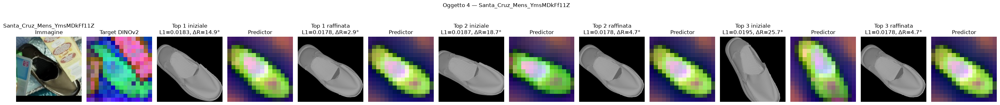

[OBJ 5] Mens_Gold_Cup_ASV_Dress_Casual_Venetian_in_Dark_Brown_Leather: campionate 400 pose | Best Pose (R real) L1=0.0187
[OBJ 5] Best wrt geodesic distance 18.329°, con L1=0.0195
    step 0: loss=0.019356, grad_norm=0.004198
    step 20: loss=0.018755, grad_norm=0.001480
    step 40: loss=0.018670, grad_norm=0.001592
    step 60: loss=0.018647, grad_norm=0.002071
    step 80: loss=0.018643, grad_norm=0.001810
    step 100: loss=0.018643, grad_norm=0.000240
    step 120: loss=0.018643, grad_norm=0.000264
    step 140: loss=0.018643, grad_norm=0.000103
[OBJ 5] Refine: L1 0.0194 -> 0.0186 | ΔR 23.54° -> 4.78° | step usati: 160
    step 0: loss=0.019468, grad_norm=0.005660
    step 20: loss=0.018667, grad_norm=0.005104
    step 40: loss=0.018661, grad_norm=0.001318
    step 60: loss=0.018649, grad_norm=0.000939
    step 80: loss=0.018643, grad_norm=0.000772
    step 100: loss=0.018643, grad_norm=0.000552
    step 120: loss=0.018643, grad_norm=0.000119
    step 140: loss=0.018643, grad_nor

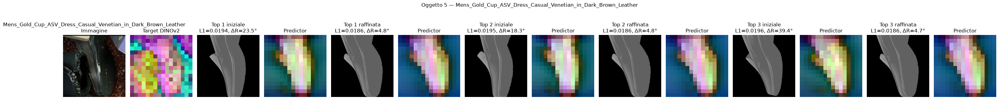

[OBJ 6] Down_To_Earth_Orchid_Pot_Ceramic_Red: campionate 400 pose | Best Pose (R real) L1=0.0186
[OBJ 6] Best wrt geodesic distance 16.387°, con L1=0.0197
    step 0: loss=0.019481, grad_norm=0.005155
    step 20: loss=0.018872, grad_norm=0.001236
    step 40: loss=0.018760, grad_norm=0.002296
    step 60: loss=0.018740, grad_norm=0.001600
    step 80: loss=0.018736, grad_norm=0.002205
    step 100: loss=0.018735, grad_norm=0.000920
    step 120: loss=0.018735, grad_norm=0.000089
    step 140: loss=0.018735, grad_norm=0.000057
    step 160: loss=0.018735, grad_norm=0.000048
[OBJ 6] Refine: L1 0.0195 -> 0.0187 | ΔR 124.44° -> 136.17° | step usati: 162
    step 0: loss=0.019492, grad_norm=0.005604
    step 20: loss=0.018778, grad_norm=0.001631
    step 40: loss=0.018743, grad_norm=0.000110
    step 60: loss=0.018737, grad_norm=0.001048
    step 80: loss=0.018735, grad_norm=0.001113
    step 100: loss=0.018735, grad_norm=0.000384
    step 120: loss=0.018735, grad_norm=0.000189
    step 14

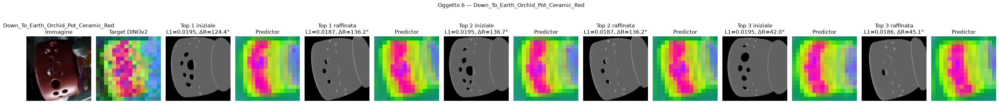

[OBJ 7] Reebok_SH_COURT_MID_II: campionate 400 pose | Best Pose (R real) L1=0.0182
[OBJ 7] Best wrt geodesic distance 18.627°, con L1=0.0197
    step 0: loss=0.019616, grad_norm=0.004371
    step 20: loss=0.018798, grad_norm=0.003234
    step 40: loss=0.018316, grad_norm=0.002897
    step 60: loss=0.018158, grad_norm=0.001735
    step 80: loss=0.018143, grad_norm=0.002418
    step 100: loss=0.018141, grad_norm=0.000299
    step 120: loss=0.018141, grad_norm=0.000141
    step 140: loss=0.018141, grad_norm=0.000052
[OBJ 7] Refine: L1 0.0196 -> 0.0181 | ΔR 26.02° -> 2.00° | step usati: 152
    step 0: loss=0.019690, grad_norm=0.004138
    step 20: loss=0.018705, grad_norm=0.005698
    step 40: loss=0.018237, grad_norm=0.002958
    step 60: loss=0.018160, grad_norm=0.002155
    step 80: loss=0.018143, grad_norm=0.002742
    step 100: loss=0.018137, grad_norm=0.000820
    step 120: loss=0.018137, grad_norm=0.000271
    step 140: loss=0.018137, grad_norm=0.000196
    step 160: loss=0.018136,

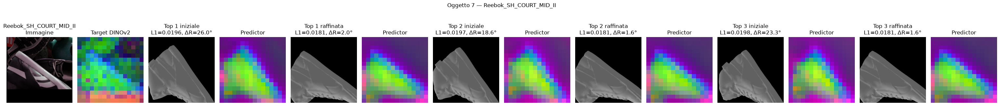

[OBJ 8] Squirrel: campionate 400 pose | Best Pose (R real) L1=0.0182
[OBJ 8] Best wrt geodesic distance 24.809°, con L1=0.0206
    step 0: loss=0.020163, grad_norm=0.003830
    step 20: loss=0.019434, grad_norm=0.003867
    step 40: loss=0.018656, grad_norm=0.003177
    step 60: loss=0.018187, grad_norm=0.002327
    step 80: loss=0.018182, grad_norm=0.000695
    step 100: loss=0.018174, grad_norm=0.000713
    step 120: loss=0.018174, grad_norm=0.000285
    step 140: loss=0.018174, grad_norm=0.000112
    step 160: loss=0.018174, grad_norm=0.000058
[OBJ 8] Refine: L1 0.0202 -> 0.0182 | ΔR 37.41° -> 1.08° | step usati: 169
    step 0: loss=0.020260, grad_norm=0.001074
    step 20: loss=0.020194, grad_norm=0.001062
    step 40: loss=0.020191, grad_norm=0.000952
    step 60: loss=0.020191, grad_norm=0.000456
    step 80: loss=0.020190, grad_norm=0.000112
    step 100: loss=0.020190, grad_norm=0.000026
[OBJ 8] Refine: L1 0.0203 -> 0.0202 | ΔR 160.96° -> 165.78° | step usati: 115
    step 0: 

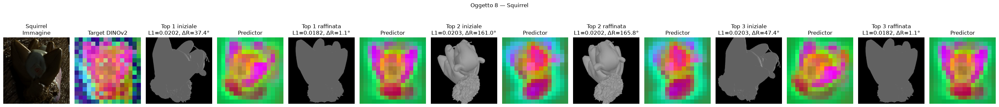

[OBJ 9] Cream_Tieks_Italian_Leather_Ballet_Flats: campionate 400 pose | Best Pose (R real) L1=0.0172
[OBJ 9] Best wrt geodesic distance 8.301°, con L1=0.0179
    step 0: loss=0.017850, grad_norm=0.013378
    step 20: loss=0.017128, grad_norm=0.004205
    step 40: loss=0.017093, grad_norm=0.002211
    step 60: loss=0.017083, grad_norm=0.001874
    step 80: loss=0.017082, grad_norm=0.000759
    step 100: loss=0.017082, grad_norm=0.000357
    step 120: loss=0.017082, grad_norm=0.000124
    step 140: loss=0.017082, grad_norm=0.000031
[OBJ 9] Refine: L1 0.0179 -> 0.0171 | ΔR 8.30° -> 2.08° | step usati: 141
    step 0: loss=0.019653, grad_norm=0.004316
    step 20: loss=0.017177, grad_norm=0.001428
    step 40: loss=0.017133, grad_norm=0.004753
    step 60: loss=0.017091, grad_norm=0.002548
    step 80: loss=0.017083, grad_norm=0.002359
    step 100: loss=0.017082, grad_norm=0.000745
    step 120: loss=0.017082, grad_norm=0.000315
    step 140: loss=0.017081, grad_norm=0.000099
[OBJ 9] Refi

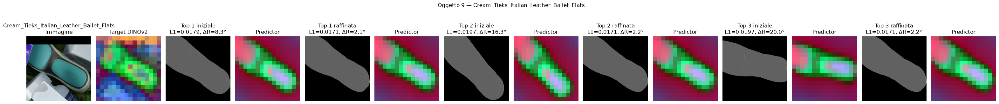

In [17]:
from scipy.spatial.transform import Rotation
from pytorch3d.transforms import so3_exp_map
import itertools

# =========================
# Utility: geometria SO(3) (numpy, per sampling deterministico)
# =========================

def geodesic_distance(R1, R2):
    R_diff = R1.T @ R2
    angle = np.arccos(np.clip((np.trace(R_diff) - 1) / 2, -1.0, 1.0))
    return np.rad2deg(angle)


def skew_np(v):
    return np.array([
        [0, -v[2], v[1]],
        [v[2], 0, -v[0]],
        [-v[1], v[0], 0]
    ])


def rotation_matrix_axis_angle_np(axis, angle):
    axis = axis / np.linalg.norm(axis)
    K_ = skew_np(axis)
    return np.eye(3) + np.sin(angle) * K_ + (1 - np.cos(angle)) * (K_ @ K_)


def rotation_from_direction_np(direction, forward=np.array([0.0, 0.0, 1.0])):
    direction = direction / np.linalg.norm(direction)
    v = np.cross(forward, direction)
    c = np.dot(forward, direction)
    s = np.linalg.norm(v)
    if s < 1e-8:
        if c > 0:
            return np.eye(3)
        orth = np.array([1.0, 0.0, 0.0]) if abs(forward[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
        axis = np.cross(forward, orth)
        return rotation_matrix_axis_angle_np(axis, np.pi)
    K_ = skew_np(v)
    return np.eye(3) + K_ + K_ @ K_ * ((1 - c) / (s ** 2))


def fibonacci_sphere(n):
    points = []
    golden_angle = np.pi * (3.0 - np.sqrt(5.0))
    for i in range(n):
        y = 1 - (i / float(max(n - 1, 1))) * 2
        radius = np.sqrt(max(0.0, 1 - y * y))
        theta = golden_angle * i
        x = np.cos(theta) * radius
        z = np.sin(theta) * radius
        points.append([x, y, z])
    return np.array(points)


N_DIRS = 20
N_ROLL = 20
TOP_K = 3
REFINE_LR = 0.01
LOSS_TOL = 1e-8
MAX_STEPS = 2000
PATIENCE = 30
GRAD_NORM_LOG_EVERY = 20

directions_global = fibonacci_sphere(N_DIRS)
golden_ratio = (1 + np.sqrt(5)) / 2

# Congela i modelli UNA VOLTA SOLA prima del refine: solo `w` deve ricevere
# gradiente, altrimenti ogni backward() calcola (e tiene in memoria) i
# gradienti anche per i parametri di encoder3d/predictor, inutilmente.
for p in itertools.chain(encoder2d.parameters(), encoder3d.parameters(), predictor.parameters()):
    p.requires_grad_(False)


def process_object(OBJ, verbose=True):
    """Esegue sampling + refine (Riemannian Adam) + plot per un singolo oggetto del batch."""

    # --- dati dell'oggetto ---
    img = batch['image'][OBJ].unsqueeze(0).to(device).float()
    mask = batch['mask'][OBJ].to(device).float()

    if img.min() >= -0.01:
        img_t = (img - MEAN_t) / STD_t
    else:
        img_t = img

    R_real = batch['rot_matrix'][OBJ].unsqueeze(0).to(device).float()
    t_real = batch['trans'][OBJ].unsqueeze(0).to(device).float()
    R_real_np = R_real.squeeze(0).cpu().numpy()

    # --- centroid / scale: shape forzata (1,3) / (1,) ---
    centroid = batch['centroid'][OBJ].reshape(-1)[None, :].to(device).float()
    scale = batch['scale'][OBJ].reshape(-1)[:1].to(device).float()

    # --- Context 3D aggregator, per-sample, su device ---
    view_feats_o = batch['view_feats'][OBJ].unsqueeze(0).float().to(device)
    view_dirs_o  = batch['view_dirs'][OBJ].unsqueeze(0).float().to(device)
    view_mask_o  = batch['view_mask'][OBJ].unsqueeze(0).bool().to(device)
    point_xyz_o  = batch['point_xyz'][OBJ].unsqueeze(0).float().to(device)

    K = batch['K'][OBJ].unsqueeze(0).to(device).float()

    mask_np = mask.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    K_np = batch['K'][OBJ].cpu().numpy()
    t_real_np = t_real.squeeze(0).cpu().numpy()
    model_name = batch['model_name'][OBJ]

    with torch.no_grad():
        target = encoder2d(img_t)
        context_t, centers_t = encoder3d.extractFeatures(
            view_feats_o, view_dirs_o, view_mask_o, point_xyz_o
        )
        ray_dirs, moment = _generate_rays(K, R_real, t_real, centroid, scale)
        pred_real = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                               context_features=context_t, context_centers=centers_t)

    centroid_np = centroid.squeeze(0).cpu().numpy()  # coerente col fix sopra
    scale_np = float(scale.item())

    img_denorm = (img_t * STD_t + MEAN_t).clamp(0, 1)
    bg_img = (img_denorm.squeeze(0).permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)

    L1_real = masked_l1_per_sample(pred_real, target, token_mask_t).item()

    # --- 1) sampling deterministico: NIENTE 'pred' salvato per tutte le 400 pose,
    #     solo R/L1/diff (leggeri). I pred delle top-K vengono ricalcolati dopo. ---
    results = []
    with torch.no_grad():
        for direction in directions_global:
            R_dir = rotation_from_direction_np(direction)
            for ri in range(N_ROLL):
                psi = 2 * np.pi * ((ri * golden_ratio) % 1.0)
                R_roll = rotation_matrix_axis_angle_np(direction, psi)
                R = R_roll @ R_dir

                R_t = torch.from_numpy(R).unsqueeze(0).to(device).float()
                ray_dirs, moment = _generate_rays(K, R_t, t_real, centroid, scale)
                pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                                  context_features=context_t, context_centers=centers_t)

                results.append({
                    'R': R,
                    'L1': masked_l1_per_sample(pred, target, token_mask_t).item(),
                    'diff': geodesic_distance(R_real_np, R),
                })

    if verbose:
        print(f"[OBJ {OBJ}] {model_name}: campionate {len(results)} pose "
              f"| Best Pose (R real) L1={L1_real:.4f}")

    results.sort(key=lambda x: x['L1'])
    results_by_diff = sorted(results, key=lambda x: x['diff'])
    if verbose:
        print(f"[OBJ {OBJ}] Best wrt geodesic distance {results_by_diff[0]['diff']:.3f}°, "
              f"con L1={results_by_diff[0]['L1']:.4f}")

    top_candidates = results[:TOP_K]

    # Ricalcolo il pred SOLO per le top-K (serve per il plot "iniziale")
    top_preds_init = []
    with torch.no_grad():
        for cand in top_candidates:
            R_t = torch.from_numpy(cand['R']).unsqueeze(0).to(device).float()
            ray_dirs, moment = _generate_rays(K, R_t, t_real, centroid, scale)
            pred_init = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                                   context_features=context_t, context_centers=centers_t)
            top_preds_init.append(pred_init.squeeze(0).cpu().numpy())

    # --- 2) refine con Riemannian Adam (left-trivialization su SO(3)) sulle top-3 ---
    refined_results = []

    for cand in top_candidates:
        R_current = torch.from_numpy(cand['R']).unsqueeze(0).to(device).float()

        w = torch.zeros(1, 3, device=device, requires_grad=True)
        optimizer = torch.optim.Adam([w], lr=REFINE_LR)

        l1_history = [cand['L1']]
        prev_loss = None
        patience_counter = 0
        step_used = 0

        for step in range(MAX_STEPS):
            optimizer.zero_grad()

            R_step = so3_exp_map(w) @ R_current
            ray_dirs, moment = _generate_rays(K, R_step, t_real, centroid, scale)
            pred = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                              context_features=context_t, context_centers=centers_t)
            loss = masked_l1_per_sample(pred, target, token_mask_t)
            current_loss = loss.item()

            loss.backward()
            grad_norm = w.grad.norm().item()
            optimizer.step()

            with torch.no_grad():
                R_current = (so3_exp_map(w) @ R_current).detach()
                w.zero_()

            step_used = step + 1

            if verbose and step % GRAD_NORM_LOG_EVERY == 0:
                print(f"    step {step}: loss={current_loss:.6f}, grad_norm={grad_norm:.6f}")

            if prev_loss is not None and (prev_loss - current_loss) < LOSS_TOL:
                patience_counter += 1
                if patience_counter >= PATIENCE:
                    break
            else:
                patience_counter = 0
            prev_loss = current_loss
            l1_history.append(current_loss)

        with torch.no_grad():
            ray_dirs, moment = _generate_rays(K, R_current, t_real, centroid, scale)
            pred_final = predictor(ray_dirs=ray_dirs, ray_moments=moment,
                                    context_features=context_t, context_centers=centers_t)
            l1_final = masked_l1_per_sample(pred_final, target, token_mask_t).item()

        R_final_np = R_current.squeeze(0).cpu().numpy()
        diff_final = geodesic_distance(R_real_np, R_final_np)

        refined_results.append({
            'R_init': cand['R'], 'L1_init': cand['L1'], 'diff_init': cand['diff'],
            'R_final': R_final_np,
            'pred_final_np': pred_final.detach().squeeze(0).cpu().numpy(),  # numpy, non tensor GPU
            'L1_final': l1_final, 'diff_final': diff_final,
            'l1_history': l1_history,
        })

        if verbose:
            print(f"[OBJ {OBJ}] Refine: L1 {cand['L1']:.4f} -> {l1_final:.4f} "
                  f"| ΔR {cand['diff']:.2f}° -> {diff_final:.2f}° "
                  f"| step usati: {step_used}")

    # --- 3) plot per questo oggetto ---
    target_np = target.squeeze(0).cpu().numpy()
    pca = PCA(n_components=3)
    target_pca = pca.fit_transform(target_np)
    target_map = to_rgb_map_local(target_pca)

    N_COLS = 2 + 4 * TOP_K
    fig, axes = plt.subplots(1, N_COLS, figsize=(2.2 * N_COLS, 4))

    axes[0].imshow(bg_img)
    axes[0].set_title(f"{model_name}\nImmagine")
    axes[0].axis('off')

    axes[1].imshow(target_map)
    axes[1].set_title("Target DINOv2")
    axes[1].axis('off')

    for j, res in enumerate(refined_results):
        base_col = 2 + 4 * j

        render_init = render_gso_object(
            model_name, res['R_init'], t_real_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )
        pred_init_map = to_rgb_map_local(pca.transform(top_preds_init[j]))

        axes[base_col].imshow(render_init)
        axes[base_col].set_title(f"Top {j+1} iniziale\nL1={res['L1_init']:.4f}, ΔR={res['diff_init']:.1f}°")
        axes[base_col].axis('off')

        axes[base_col + 1].imshow(pred_init_map)
        axes[base_col + 1].set_title("Predictor")
        axes[base_col + 1].axis('off')

        render_final = render_gso_object(
            model_name, res['R_final'], t_real_np, K_np, img_size=bg_img.shape[:2],
            centroid=centroid_np, scale=scale_np,
        )
        pred_final_map = to_rgb_map_local(pca.transform(res['pred_final_np']))

        axes[base_col + 2].imshow(render_final)
        axes[base_col + 2].set_title(f"Top {j+1} raffinata\nL1={res['L1_final']:.4f}, ΔR={res['diff_final']:.1f}°")
        axes[base_col + 2].axis('off')

        axes[base_col + 3].imshow(pred_final_map)
        axes[base_col + 3].set_title("Predictor")
        axes[base_col + 3].axis('off')

    plt.suptitle(f"Oggetto {OBJ} — {model_name}")
    plt.tight_layout()
    plt.show()

    # Nessun tensore GPU/pred completo tenuto nel dizionario restituito: solo
    # numeri e array numpy leggeri. E' questo l'oggetto che si accumula in
    # all_objects_results per l'intero batch, quindi deve restare piccolo.
    return {
        'OBJ': OBJ,
        'model_name': model_name,
        'L1_real': L1_real,
        'results_sorted': [{'R': r['R'], 'L1': r['L1'], 'diff': r['diff']} for r in results],
        'refined_results': refined_results,
    }


# =========================
# Esegui su tutti gli oggetti del batch
# =========================
actual_bs = batch['image'].shape[0]  # BATCH_SIZE non era definito

all_objects_results = []
for OBJ in range(actual_bs):
    res = process_object(OBJ)
    all_objects_results.append(res)

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from pytorch3d.transforms import so3_exp_map
from mpl_toolkits.mplot3d import Axes3D  # noqa: necessario per projection='3d'


def random_tangent_basis(seed=None):
    """Due vettori tangenti ortonormali random nell'algebra di Lie so(3) (R^3)."""
    rng = np.random.default_rng(seed)
    v1 = rng.normal(size=3)
    v1 /= np.linalg.norm(v1)
    v2 = rng.normal(size=3)
    v2 -= np.dot(v2, v1) * v1
    v2 /= np.linalg.norm(v2)
    return v1, v2


def compute_loss_manifold(OBJ, R_center_np, v1, v2, extent_deg=180, n_grid=41,
                           chunk=512, verbose=True):
    """
    Calcola la L1 su una griglia n_grid x n_grid nel piano tangente attorno a
    R_center_np, batchando i forward pass a `chunk` alla volta invece di uno
    per pixel (n_grid=41 -> 1681 forward, altrimenti uno alla volta).
    """
    img = batch['image'][OBJ].unsqueeze(0).to(device).float()
    mask = batch['mask'][OBJ].to(device).float()

    if img.min() >= -0.01:
        img_t = (img - MEAN_t) / STD_t
    else:
        img_t = img

    t_real = batch['trans'][OBJ].unsqueeze(0).to(device).float()

    # --- centroid / scale: shape forzata (1,3) / (1,) ---
    centroid = batch['centroid'][OBJ].reshape(-1)[None, :].to(device).float()
    scale = batch['scale'][OBJ].reshape(-1)[:1].to(device).float()

    # --- Context 3D aggregator, per-sample, su device ---
    view_feats_o = batch['view_feats'][OBJ].unsqueeze(0).float().to(device)
    view_dirs_o  = batch['view_dirs'][OBJ].unsqueeze(0).float().to(device)
    view_mask_o  = batch['view_mask'][OBJ].unsqueeze(0).bool().to(device)
    point_xyz_o  = batch['point_xyz'][OBJ].unsqueeze(0).float().to(device)

    K = batch['K'][OBJ].unsqueeze(0).to(device).float()

    mask_np = mask.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    with torch.no_grad():
        target = encoder2d(img_t)
        context_t, centers_t = encoder3d.extractFeatures(
            view_feats_o, view_dirs_o, view_mask_o, point_xyz_o
        )

    extent_rad = np.deg2rad(extent_deg)
    alphas = np.linspace(-extent_rad, extent_rad, n_grid)
    betas = np.linspace(-extent_rad, extent_rad, n_grid)
    AA, BB = np.meshgrid(alphas, betas)

    R_center_t = torch.from_numpy(R_center_np).unsqueeze(0).to(device).float()

    # tutti i vettori tangenti della griglia, appiattiti: (n_grid*n_grid, 3)
    W_flat = (AA.reshape(-1, 1) * v1[None, :] + BB.reshape(-1, 1) * v2[None, :]).astype(np.float32)
    n_total = W_flat.shape[0]
    loss_flat = np.zeros(n_total, dtype=np.float32)

    with torch.no_grad():
        n_done = 0
        while n_done < n_total:
            b = min(chunk, n_total - n_done)
            w_b = torch.from_numpy(W_flat[n_done:n_done + b]).to(device)          # (b, 3)
            R_b = so3_exp_map(w_b) @ R_center_t.expand(b, -1, -1)                 # (b, 3, 3)

            K_b = K.expand(b, -1, -1)
            t_b = t_real.expand(b, -1)
            centroid_b = centroid.expand(b, -1)
            scale_b = scale.expand(b)
            context_b = context_t.expand(b, -1, -1)
            centers_b = centers_t.expand(b, -1, -1)
            target_b = target.expand(b, -1, -1)
            token_mask_b = token_mask_t.expand(b, -1)

            ray_dirs_b, moment_b = _generate_rays(K_b, R_b, t_b, centroid_b, scale_b)
            pred_b = predictor(ray_dirs=ray_dirs_b, ray_moments=moment_b,
                                context_features=context_b, context_centers=centers_b)
            l1_b = masked_l1_per_sample(pred_b, target_b, token_mask_b)

            loss_flat[n_done:n_done + b] = l1_b.cpu().numpy()
            n_done += b

    loss_grid = loss_flat.reshape(n_grid, n_grid)

    if verbose:
        print(f"Griglia {n_grid}x{n_grid} completata ({n_total} forward pass, chunk={chunk}), "
              f"L1 range=[{loss_grid.min():.4f}, {loss_grid.max():.4f}]")

    return AA, BB, loss_grid  # radianti


import plotly.graph_objects as go
import numpy as np
import plotly.graph_objects as go
from scipy.ndimage import minimum_filter


def plot_loss_manifold(OBJ, model_name, AA, BB, loss_grid, center_label="R_real",
                       tol=0.0, show_secondary=False, exclude_deg=10, nbhd=5):
    """
    rosso  = posa vera (centro della griglia)
    blu    = minimo globale della griglia, mostrato solo se è più basso della posa vera
    arancione (opzionale) = minimi locali secondari, più alti della vera, fuori da exclude_deg
    """
    AA_deg, BB_deg = np.rad2deg(AA), np.rad2deg(BB)
    ci, cj = loss_grid.shape[0] // 2, loss_grid.shape[1] // 2
    loss_real = loss_grid[ci, cj]

    # v1, v2 sono ortonormali -> |w| = sqrt(α²+β²) è l'angolo di rotazione; riavvolgo oltre 180°
    theta = np.rad2deg(np.sqrt(AA**2 + BB**2)) % 360.0
    dist_deg = np.minimum(theta, 360.0 - theta)

    # minimo globale della griglia
    gi, gj = np.unravel_index(np.argmin(loss_grid), loss_grid.shape)
    gmin, gdist = loss_grid[gi, gj], dist_deg[gi, gj]
    delta = gmin - loss_real

    fig = go.Figure()
    fig.add_trace(go.Surface(x=AA_deg, y=BB_deg, z=loss_grid, colorscale='Viridis',
                             colorbar=dict(title="L1 loss"), showscale=True, name="loss"))
    fig.add_trace(go.Scatter3d(x=[0], y=[0], z=[loss_real], mode='markers',
                               marker=dict(size=7, color='red'), name=center_label))

    # blu: solo se il minimo globale è più basso della posa vera
    if delta < -tol and (gi, gj) != (ci, cj):
        fig.add_trace(go.Scatter3d(x=[AA_deg[gi, gj]], y=[BB_deg[gi, gj]], z=[gmin],
                                   mode='markers', marker=dict(size=7, color='blue'),
                                   name=f"minimo globale ({gdist:.1f}° dalla vera)"))
        subtitle = (f"blu = minimo globale, \n più basso della vera: {gdist:.1f}° di distanza, "
                    f"\nΔL1={delta:+.5f} ({delta / loss_real * 100:+.2f}%)")
        print(f"[OBJ {OBJ}] minimo globale L1={gmin:.5f} (vera {loss_real:.5f}, Δ={delta:+.5f}) "
              f"a {gdist:.1f}° dalla posa vera")
    else:
        subtitle = "la posa vera è il minimo della fetta"
        print(f"[OBJ {OBJ}] la posa vera è il minimo (L1={loss_real:.5f})")

    # arancione (opzionale): minimi locali secondari, più alti della vera
    if show_secondary:
        is_local_min = loss_grid == minimum_filter(loss_grid, size=nbhd, mode="nearest")
        sec = is_local_min & (dist_deg > exclude_deg)
        sec[gi, gj] = False                      # il globale è già mostrato (o è la vera)
        if sec.any():
            si, sj = np.where(sec)
            fig.add_trace(go.Scatter3d(
                x=AA_deg[si, sj], y=BB_deg[si, sj], z=loss_grid[si, sj], mode='markers',
                marker=dict(size=4, color='orange'),
                text=[f"{dist_deg[i, j]:.0f}° dalla vera, Δ={loss_grid[i, j] - loss_real:+.4f}"
                      for i, j in zip(si, sj)],
                name="minimi locali secondari"))

    fig.update_scenes(xaxis_title='α (°) — direzione v1',
                      yaxis_title='β (°) — direzione v2',
                      zaxis_title='L1 loss')
    fig.update_layout(
        height=700, width=900,
        title_text=f"Manifold L1 — OBJ {OBJ} ({model_name})<br>rosso = {center_label} | {subtitle}",
        legend=dict(x=0.75, y=0.9))
    fig.show()


# =========================
# ESEGUI: confronta un oggetto che funziona bene con uno che fallisce
# =========================
EXTENT_DEG = 90
N_GRID = 41
CHUNK = 512  # abbassa se vai in OOM di VRAM

actual_bs = batch['image'].shape[0]
n_objects = min(40, actual_bs)  # non assumere che il batch ne contenga sempre 40

allobj = [(i, 0) for i in range(n_objects)]
for OBJ_TO_TEST, seed in allobj:
    R_real_np = batch['rot_matrix'][OBJ_TO_TEST].cpu().numpy()
    model_name = batch['model_name'][OBJ_TO_TEST]

    v1, v2 = random_tangent_basis(seed=seed)
    AA, BB, loss_grid = compute_loss_manifold(OBJ_TO_TEST, R_real_np, v1, v2,
                                               extent_deg=EXTENT_DEG, n_grid=N_GRID,
                                               chunk=CHUNK)
    plot_loss_manifold(OBJ_TO_TEST, model_name, AA, BB, loss_grid, center_label="R_real")

Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0167, 0.0215]
[OBJ 0] la posa vera è il minimo (L1=0.01674)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0187, 0.0216]
[OBJ 1] la posa vera è il minimo (L1=0.01875)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0174, 0.0219]
[OBJ 2] la posa vera è il minimo (L1=0.01744)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0175, 0.0206]
[OBJ 3] la posa vera è il minimo (L1=0.01747)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0179, 0.0211]
[OBJ 4] la posa vera è il minimo (L1=0.01786)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0187, 0.0214]
[OBJ 5] la posa vera è il minimo (L1=0.01872)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0186, 0.0222]
[OBJ 6] la posa vera è il minimo (L1=0.01861)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0182, 0.0214]
[OBJ 7] la posa vera è il minimo (L1=0.01816)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0182, 0.0211]
[OBJ 8] la posa vera è il minimo (L1=0.01818)


Griglia 41x41 completata (1681 forward pass, chunk=512), L1 range=[0.0172, 0.0214]
[OBJ 9] la posa vera è il minimo (L1=0.01716)


In [19]:
import numpy as np
import torch
import plotly.graph_objects as go
from pytorch3d.transforms import so3_exp_map


def compute_loss_volume(
    OBJ,
    R_center_np,
    extent_deg=15,
    n_points=4000,
    chunk=512,
    sampling="uniform_cube",
    verbose=True,
):
    """
    Campiona perturbazioni 3D nel tangente di SO(3) attorno a R_center
    e calcola la masked L1 per ogni punto.

    Output:
        W_deg   : (N, 3) perturbazioni [wx, wy, wz] in gradi
        loss_np : (N,)   energia masked L1
        loss_gt : float  energia alla GT (w = 0)
    """
    img = batch['image'][OBJ].unsqueeze(0).to(device).float()
    mask = batch['mask'][OBJ].to(device).float()

    if img.min() >= -0.01:
        img_t = (img - MEAN_t) / STD_t
    else:
        img_t = img

    t_real = batch['trans'][OBJ].unsqueeze(0).to(device).float()

    centroid = batch['centroid'][OBJ].reshape(-1)[None, :].to(device).float()
    scale = batch['scale'][OBJ].reshape(-1)[:1].to(device).float()

    view_feats_o = batch['view_feats'][OBJ].unsqueeze(0).float().to(device)
    view_dirs_o  = batch['view_dirs'][OBJ].unsqueeze(0).float().to(device)
    view_mask_o  = batch['view_mask'][OBJ].unsqueeze(0).bool().to(device)
    point_xyz_o  = batch['point_xyz'][OBJ].unsqueeze(0).float().to(device)

    K = batch['K'][OBJ].unsqueeze(0).to(device).float()

    mask_np = mask.squeeze().cpu().numpy()
    token_mask_np = pixel_mask_to_token_mask(mask_np, grid_size=GRID_SIZE)
    token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

    with torch.no_grad():
        target = encoder2d(img_t)
        context_t, centers_t = encoder3d.extractFeatures(
            view_feats_o, view_dirs_o, view_mask_o, point_xyz_o
        )

    extent_rad = np.deg2rad(extent_deg)

    # --------------------------------------------------------
    # Campionamento perturbazioni nello spazio tangente R^3
    # --------------------------------------------------------
    if sampling == "uniform_cube":
        W = np.random.uniform(
            low=-extent_rad, high=extent_rad, size=(n_points, 3)
        ).astype(np.float32)

    elif sampling == "uniform_ball":
        # punti uniformi in una sfera di raggio extent_rad
        dirs = np.random.normal(size=(n_points, 3)).astype(np.float32)
        dirs /= np.linalg.norm(dirs, axis=1, keepdims=True) + 1e-8
        radii = np.random.rand(n_points, 1).astype(np.float32) ** (1.0 / 3.0)
        W = dirs * radii * extent_rad

    else:
        raise ValueError(f"sampling non supportato: {sampling}")

    # aggiungo esplicitamente la GT: w = 0
    W = np.concatenate([np.zeros((1, 3), dtype=np.float32), W], axis=0)

    R_center_t = torch.from_numpy(R_center_np).unsqueeze(0).to(device).float()

    n_total = W.shape[0]
    loss_np = np.zeros(n_total, dtype=np.float32)

    with torch.no_grad():
        n_done = 0
        while n_done < n_total:
            b = min(chunk, n_total - n_done)

            w_b = torch.from_numpy(W[n_done:n_done + b]).to(device)   # (b, 3)
            R_b = so3_exp_map(w_b) @ R_center_t.expand(b, -1, -1)     # (b, 3, 3)

            K_b = K.expand(b, -1, -1)
            t_b = t_real.expand(b, -1)
            centroid_b = centroid.expand(b, -1)
            scale_b = scale.expand(b)
            context_b = context_t.expand(b, -1, -1)
            centers_b = centers_t.expand(b, -1, -1)
            target_b = target.expand(b, -1, -1)
            token_mask_b = token_mask_t.expand(b, -1)

            ray_dirs_b, moment_b = _generate_rays(
                K_b, R_b, t_b, centroid_b, scale_b
            )

            pred_b = predictor(
                ray_dirs=ray_dirs_b,
                ray_moments=moment_b,
                context_features=context_b,
                context_centers=centers_b
            )

            l1_b = masked_l1_per_sample(pred_b, target_b, token_mask_b)
            loss_np[n_done:n_done + b] = l1_b.detach().cpu().numpy()

            n_done += b

    W_deg = np.rad2deg(W)
    loss_gt = float(loss_np[0])

    if verbose:
        print(
            f"[OBJ {OBJ}] campionati {n_total} punti "
            f"(sampling={sampling}, extent=±{extent_deg}°), "
            f"L1 range=[{loss_np.min():.5f}, {loss_np.max():.5f}], "
            f"L1(GT)={loss_gt:.5f}"
        )

    return W_deg, loss_np, loss_gt


def plot_loss_volume(
    OBJ,
    model_name,
    W_deg,
    loss_np,
    loss_gt,
    show_best=True,
    show_low_energy_only=False,
    q=0.15,
    point_size=4,
):
    """
    Plotly 3D scatter:
      x,y,z = perturbazione tangente [wx, wy, wz] in gradi
      colore = energia (masked L1)

    GT = punto rosso in (0,0,0)
    best sampled = punto blu (se show_best=True)
    """
    x = W_deg[:, 0]
    y = W_deg[:, 1]
    z = W_deg[:, 2]

    # opzionale: mostra solo i punti a energia più bassa
    mask_keep = np.ones_like(loss_np, dtype=bool)
    if show_low_energy_only:
        thr = np.quantile(loss_np, q)
        mask_keep = loss_np <= thr
        mask_keep[0] = True  # tieni sempre la GT

    xk = x[mask_keep]
    yk = y[mask_keep]
    zk = z[mask_keep]
    lk = loss_np[mask_keep]

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=xk,
        y=yk,
        z=zk,
        mode="markers",
        marker=dict(
            size=point_size,
            color=lk,
            colorscale="Viridis",
            colorbar=dict(title="L1 loss"),
            opacity=0.75,
        ),
        text=[
            f"L1={v:.5f}<br>"
            f"Distanza GT={np.linalg.norm(w):.2f}°"
            for v, w in zip(lk, W_deg[mask_keep])
        ],
        hovertemplate=(
            "wx=%{x:.2f}°<br>"
            "wy=%{y:.2f}°<br>"
            "wz=%{z:.2f}°<br>"
            "%{text}<extra></extra>"
        ),
        name="campioni"
    ))

    # GT = perturbazione nulla
    fig.add_trace(go.Scatter3d(
        x=[0.0],
        y=[0.0],
        z=[0.0],
        mode="markers+text",
        marker=dict(size=8, color="red", symbol="diamond"),
        text=[f"GT<br>L1={loss_gt:.5f}"],
        textposition="top center",
        name="GT"
    ))

    # miglior punto campionato
    if show_best:
        best_idx = int(np.argmin(loss_np))
        fig.add_trace(go.Scatter3d(
            x=[W_deg[best_idx, 0]],
            y=[W_deg[best_idx, 1]],
            z=[W_deg[best_idx, 2]],
            mode="markers+text",
            marker=dict(size=8, color="blue", symbol="circle"),
            text=[f"best<br>L1={loss_np[best_idx]:.5f}"],
            textposition="top center",
            name="best sampled"
        ))

        dist_best = np.linalg.norm(W_deg[best_idx])
        delta = float(loss_np[best_idx] - loss_gt)

        if best_idx == 0:
            subtitle = "la GT è il miglior punto campionato"
            print(f"[OBJ {OBJ}] GT migliore punto campionato, L1={loss_gt:.5f}")
        else:
            subtitle = (
                f"best a {dist_best:.2f}° dalla GT, "
                f"ΔL1={delta:+.5f}"
            )
            print(
                f"[OBJ {OBJ}] best sampled L1={loss_np[best_idx]:.5f}, "
                f"GT L1={loss_gt:.5f}, Δ={delta:+.5f}, "
                f"||w_best||={dist_best:.2f}°"
            )
    else:
        subtitle = f"L1(GT)={loss_gt:.5f}"

    fig.update_layout(
        title=(
            f"Loss volume — OBJ {OBJ} ({model_name})<br>"
            f"rosso = GT, blu = best sampled | {subtitle}"
        ),
        scene=dict(
            xaxis_title="wx (°)",
            yaxis_title="wy (°)",
            zaxis_title="wz (°)",
            aspectmode="cube",
        ),
        width=950,
        height=800,
        legend=dict(x=0.02, y=0.98),
    )

    fig.show()

In [20]:
EXTENT_DEG = 15
N_POINTS = 3000
CHUNK = 20

actual_bs = batch['image'].shape[0]
n_objects = min(10, actual_bs)

for OBJ_TO_TEST in range(n_objects):
    R_real_np = batch['rot_matrix'][OBJ_TO_TEST].cpu().numpy()
    model_name = batch['model_name'][OBJ_TO_TEST]

    W_deg, loss_np, loss_gt = compute_loss_volume(
        OBJ=OBJ_TO_TEST,
        R_center_np=R_real_np,
        extent_deg=EXTENT_DEG,
        n_points=N_POINTS,
        chunk=CHUNK,
        sampling="uniform_cube",
        verbose=True,
    )

    plot_loss_volume(
        OBJ=OBJ_TO_TEST,
        model_name=model_name,
        W_deg=W_deg,
        loss_np=loss_np,
        loss_gt=loss_gt,
        show_best=True,
        show_low_energy_only=True,   # spesso più leggibile
        q=0.20,
        point_size=4,
    )

[OBJ 0] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01673, 0.02029], L1(GT)=0.01674
[OBJ 0] best sampled L1=0.01673, GT L1=0.01674, Δ=-0.00001, ||w_best||=1.13°


[OBJ 1] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01865, 0.02148], L1(GT)=0.01875
[OBJ 1] best sampled L1=0.01865, GT L1=0.01875, Δ=-0.00010, ||w_best||=4.45°


[OBJ 2] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01744, 0.02062], L1(GT)=0.01744
[OBJ 2] GT migliore punto campionato, L1=0.01744


[OBJ 3] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01744, 0.01931], L1(GT)=0.01747
[OBJ 3] best sampled L1=0.01744, GT L1=0.01747, Δ=-0.00002, ||w_best||=1.79°


[OBJ 4] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01782, 0.01993], L1(GT)=0.01786
[OBJ 4] best sampled L1=0.01782, GT L1=0.01786, Δ=-0.00003, ||w_best||=2.37°


[OBJ 5] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01867, 0.02064], L1(GT)=0.01872
[OBJ 5] best sampled L1=0.01867, GT L1=0.01872, Δ=-0.00004, ||w_best||=8.20°


[OBJ 6] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01856, 0.02073], L1(GT)=0.01861
[OBJ 6] best sampled L1=0.01856, GT L1=0.01861, Δ=-0.00005, ||w_best||=5.41°


[OBJ 7] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01815, 0.02059], L1(GT)=0.01816
[OBJ 7] best sampled L1=0.01815, GT L1=0.01816, Δ=-0.00001, ||w_best||=1.73°


[OBJ 8] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01818, 0.02078], L1(GT)=0.01818
[OBJ 8] GT migliore punto campionato, L1=0.01818


[OBJ 9] campionati 3001 punti (sampling=uniform_cube, extent=±15°), L1 range=[0.01709, 0.02031], L1(GT)=0.01716
[OBJ 9] best sampled L1=0.01709, GT L1=0.01716, Δ=-0.00007, ||w_best||=2.23°


# BOP OBJECT


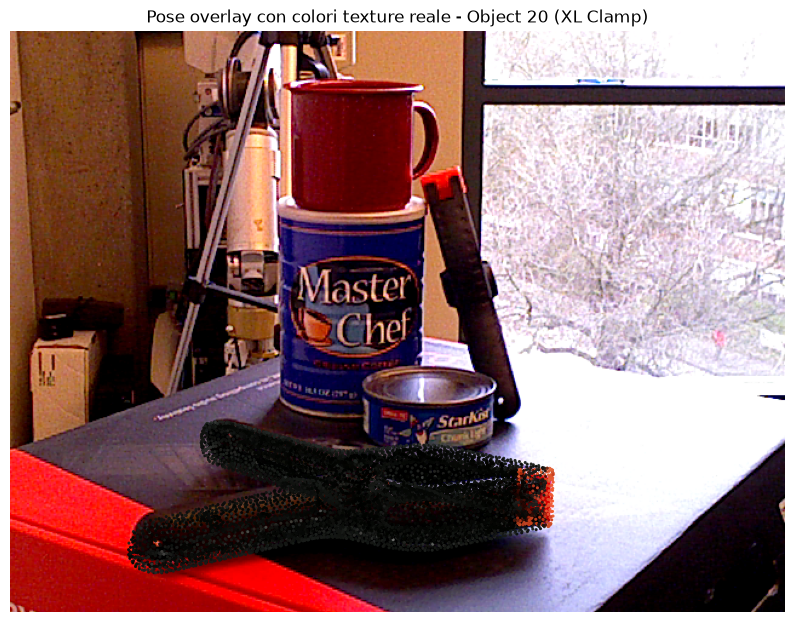

In [21]:
# CHOOSE A SINGLE IMAGE. IN THIS CASE FROM THE DATASET YCBV (Scene 48, Image 47, Object 20 - XL Clamp)

import json
import numpy as np
import trimesh
import cv2
import matplotlib.pyplot as plt
import torch
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["HYDRA_FULL_ERROR"] = "1" # Debug

rgb_path = "/data/riccardop02/datasets/ycbv/test/000048/rgb/000047.png"
mask_path = "/data/riccardop02/datasets/ycbv/test/000048/mask_visib/000001_000004.png"
scene_camera_path = "/data/riccardop02/datasets/ycbv/test/000048/scene_camera.json"
model_path = "/data/riccardop02/datasets/ycbv/models/obj_000020.ply"


Pose = {
    "cam_R_m2c": [-0.9993032187000758, -0.03468586763469483, 0.013799769394337228,
                   0.02273746658654025, -0.27237133848523803, 0.9619233928797483,
                  -0.02960648331060263, 0.9615662504172701, 0.2729703664836574],
    "cam_t_m2c": [-20.983454465364908, 85.55142809136696, 684.4252367092936]
}

# --- Intrinseci ---
with open(scene_camera_path, "r") as f:
    scene_camera = json.load(f)
K = np.array(scene_camera["47"]["cam_K"]).reshape(3, 3)

# --- Carica mesh (texture già embedded automaticamente da trimesh) ---
mesh = trimesh.load(model_path, process=False)
vertices = np.array(mesh.vertices)               # (10064, 3)
uv = np.array(mesh.visual.uv)                     # (10064, 2)

# --- Usa la texture già caricata da trimesh, non ricaricarla da file ---
texture_img = np.array(mesh.visual.material.image.convert("RGB"))  # (4096, 4096, 3)
tex_h, tex_w = texture_img.shape[:2]

# --- Converti UV in coordinate pixel della texture ---
u_px = np.clip((uv[:, 0] * (tex_w - 1)).astype(int), 0, tex_w - 1)
v_px = np.clip(((1 - uv[:, 1]) * (tex_h - 1)).astype(int), 0, tex_h - 1)  # flip verticale

vertex_colors = texture_img[v_px, u_px] / 255.0   # (10064, 3), in [0,1]

# --- Trasforma i vertici in camera coords e proietta ---
R = np.array(Pose["cam_R_m2c"]).reshape(3, 3)
t = np.array(Pose["cam_t_m2c"]).reshape(3, 1)

points_cam = (R @ vertices.T) + t
points_img_h = K @ points_cam
points_img = (points_img_h[:2, :] / points_img_h[2, :]).T

# --- Carica RGB della scena ---
rgb = cv2.imread(rgb_path)
rgb_rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

valid = (points_img[:, 0] >= 0) & (points_img[:, 0] < w) & \
        (points_img[:, 1] >= 0) & (points_img[:, 1] < h)

# --- Plot con i colori reali della texture ---
plt.figure(figsize=(10, 8))
plt.imshow(rgb_rgb)
plt.scatter(points_img[valid, 0], points_img[valid, 1],
            s=1.5, c=vertex_colors[valid], alpha=0.9)
plt.title("Pose overlay con colori texture reale - Object 20 (XL Clamp)")
plt.axis('off')
plt.show()

In [22]:
def load_ycbv_mesh(model_path: str) -> trimesh.Trimesh:
    """Equivalente di load_gso_mesh, ma per un singolo file .ply YCB-V con texture embedded."""
    mesh = trimesh.load(model_path, process=False)
    if not isinstance(mesh, trimesh.Trimesh):
        raise ValueError(f"Expected a single mesh, got {type(mesh)}")
    return mesh


def fibonacci_sphere(n: int, radius: float) -> np.ndarray:
    """n posizioni camera quasi-uniformi su una sfera di raggio `radius`."""
    idx = np.arange(n)
    golden = (1 + 5 ** 0.5) / 2
    theta = 2 * np.pi * idx / golden
    z = 1 - (2 * idx + 1) / n
    r_xy = np.sqrt(np.maximum(0.0, 1 - z * z))
    x, y = r_xy * np.cos(theta), r_xy * np.sin(theta)
    return (np.stack([x, y, z], axis=-1) * radius).astype(np.float32)

def process_model(model_dir: str, encoder2d, n_points: int, n_views: int,
                  cam_radius: float, fov_deg: float, device: torch.device):

    # Load the mesh
    mesh = load_ycbv_mesh(model_dir)

    # Sample points on the mesh surface and apply FPS to get n_points
    dense_xyz = trimesh.sample.sample_surface(mesh, 20000)[0].astype(np.float32)
    points = fps_torch(torch.from_numpy(dense_xyz).to(device), n_points)

    #compute centroid and scale to normalize points and mesh to canonical frame
    centroid = points.mean(dim=0, keepdim=True)
    points_c = points - centroid
    scale = points_c.norm(dim=-1).max().clamp(min=1e-6)
    points_n = points_c / scale                                 # frame canonico

    mesh_c = mesh.copy()
    mesh_c.vertices = (mesh_c.vertices - centroid.cpu().numpy()) / scale.item()

    # Compute the intrinsic matrix
    image_size = get_target_size(encoder2d)
    f = 0.5 * image_size / np.tan(np.radians(fov_deg) / 2)
    K_np = np.array([[f, 0, image_size / 2], [0, f, image_size / 2], [0, 0, 1]], dtype=np.float32)
    K = torch.from_numpy(K_np).to(device)

    # Obtain camera positions on a sphere around the object to render multiple views that cover entirely the object 
    cam_positions = fibonacci_sphere(n_views, radius=cam_radius)
    view_feats, view_dirs, masks = [], [], []

    for cam_pos in cam_positions:
        # Compute the camera extrinsic matrix (R, trans) using the look_at_RT function
        R_np, trans_np = look_at_RT(cam_pos)
        R, trans = torch.from_numpy(R_np).to(device), torch.from_numpy(trans_np).to(device)

        # Render the view of the mesh from the camera position and obtain the color and depth images
        color, depth = render_view(mesh_c, R_np, trans_np, K_np, image_size)
        depth_t = torch.from_numpy(depth).to(device)


        feat_grid, H_proc, W_proc = extract_dinov2_grid(encoder2d, color, device)
        assert H_proc == image_size and W_proc == image_size, \
            "il processor ha ritagliato/scalato: K non è più coerente con la griglia di feature"

        # Project the 3D points into the camera view and compute the visibility mask
        uv, z_point = project_points(points_n, R, trans, K)
        vis = visibility_mask(uv, z_point, depth_t, image_size)

        feats = sample_feature_grid(feat_grid, uv, image_size) * vis.unsqueeze(-1)

        cam_pos_t = torch.from_numpy(cam_pos).to(device)
        d = F.normalize(cam_pos_t.unsqueeze(0) - points_n, dim=-1) * vis.unsqueeze(-1)

        view_feats.append(feats.cpu().numpy())
        view_dirs.append(d.cpu().numpy())
        masks.append(vis.cpu().numpy())

    return (points_n.cpu().numpy(),
            np.stack(view_feats, axis=1),    # (P, n_views, D)
            np.stack(view_dirs, axis=1),     # (P, n_views, 3)
            np.stack(masks, axis=1),         # (P, n_views)
            centroid.cpu().numpy(), scale.item())


context: (1, 512, 1024) | centers: (1, 512, 3) | centroid: (1, 3) | scale: (1,)
Object 20 (XL Clamp): L1 pred=0.0182 | L1 pred(+40°)=0.0199


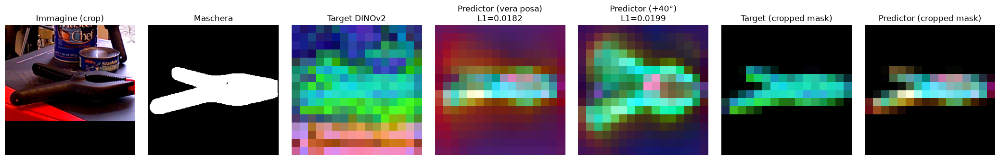

In [23]:
# =========================
# Visualizzazione: BOP (YCB-V) - target vs predictor, vera posa vs posa sbagliata
# =========================
from sklearn.decomposition import PCA

IMG_SIZE = 256          # deve combaciare con quello usato in training/encoder2d
CROP_MARGIN = 1.02       # margine attorno al bbox della maschera (1.0 = bbox esatto)
WRONG_ROT_DEG = 40.0
ROT_AXIS = 'x'

# --- Carica immagine e maschera ---
mask_full = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
rgb_full = cv2.cvtColor(cv2.imread(rgb_path), cv2.COLOR_BGR2RGB)
h, w = rgb_full.shape[:2]

# --- Bbox della maschera + margine, crop quadrato ---
ys, xs = np.where(mask_full > 0)
x0, x1 = xs.min(), xs.max()
y0, y1 = ys.min(), ys.max()
cx_box, cy_box = (x0 + x1) / 2, (y0 + y1) / 2
side = max(x1 - x0, y1 - y0) * CROP_MARGIN

x0c, x1c = int(cx_box - side / 2), int(cx_box + side / 2)
y0c, y1c = int(cy_box - side / 2), int(cy_box + side / 2)

# --- Crop (con padding se esce dai bordi immagine) ---
pad_l, pad_t = max(0, -x0c), max(0, -y0c)
pad_r, pad_b = max(0, x1c - w), max(0, y1c - h)
x0c, y0c = max(0, x0c), max(0, y0c)
x1c, y1c = min(w, x1c), min(h, y1c)

rgb_crop = rgb_full[y0c:y1c, x0c:x1c]
mask_crop = mask_full[y0c:y1c, x0c:x1c]
if any([pad_l, pad_t, pad_r, pad_b]):
    rgb_crop = cv2.copyMakeBorder(rgb_crop, pad_t, pad_b, pad_l, pad_r, cv2.BORDER_CONSTANT, value=0)
    mask_crop = cv2.copyMakeBorder(mask_crop, pad_t, pad_b, pad_l, pad_r, cv2.BORDER_CONSTANT, value=0)

crop_side = rgb_crop.shape[0]  # quadrato

# --- Resize a IMG_SIZE ---
rgb_resized = cv2.resize(rgb_crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
mask_resized = cv2.resize(mask_crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

# --- K aggiornata per il crop + resize (crop shift + scale) ---
K_crop = K.copy()
K_crop[0, 2] -= (x0c - pad_l)   
K_crop[1, 2] -= (y0c - pad_t)  
scale_factor = IMG_SIZE / crop_side
K_crop = K_crop * np.array([[scale_factor, 0, scale_factor],
                             [0, scale_factor, scale_factor],
                             [0, 0, 1]])
K_crop[2, 2] = 1.0

# --- Tensor immagine, normalizzata come si aspetta encoder2d ---
img_np = rgb_resized.astype(np.float32) / 255.0
img_t_raw = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device).float()
img_t = (img_t_raw - MEAN_t) / STD_t

K_t = torch.from_numpy(K_crop).unsqueeze(0).to(device).float()

# --- Posa vera dalla annotazione BOP ---
R_true = np.array(Pose["cam_R_m2c"]).reshape(3, 3)
t_true = np.array(Pose["cam_t_m2c"]).reshape(3)
rot_t = torch.from_numpy(R_true).unsqueeze(0).to(device).float()
trans_t = torch.from_numpy(t_true).unsqueeze(0).to(device).float()

# --- centroid/scale/context 3D dal CAD model (Cell 2) ---
points, view_feats, view_dirs, mask, centroid, scale = process_model(
    model_path, encoder2d, n_points=512, n_views=24,
    cam_radius=2.5, fov_deg=40.0, device=device
)

# numpy -> torch + aggiunta dimensione batch (B=1)
points_t     = torch.from_numpy(points).unsqueeze(0).to(device).float()      # (1, P, 3)
view_feats_t = torch.from_numpy(view_feats).unsqueeze(0).to(device).float()  # (1, P, N, D)
view_dirs_t  = torch.from_numpy(view_dirs).unsqueeze(0).to(device).float()   # (1, P, N, 3)
mask_t       = torch.from_numpy(mask).unsqueeze(0).to(device).bool()         # (1, P, N)

with torch.no_grad():
    feats3d, centers = encoder3d.extractFeatures(view_feats_t, view_dirs_t, mask_t, points_t)

context_t = feats3d.float()
centers_t = centers.float()
centroid_t = torch.from_numpy(np.asarray(centroid, dtype=np.float32)).reshape(1, 3).to(device)
scale_t = torch.tensor([float(scale)], device=device, dtype=torch.float32)   # (1,)

print("context:", tuple(context_t.shape), "| centers:", tuple(centers_t.shape),
      "| centroid:", tuple(centroid_t.shape), "| scale:", tuple(scale_t.shape))

# --- posa "sbagliata" ---
R_offset = rotation_matrix(ROT_AXIS, WRONG_ROT_DEG, device)
rot_wrong_t = torch.matmul(R_offset.unsqueeze(0).float(), rot_t)

ray_dirs, moment_c = _generate_rays(K_t, rot_t, trans_t, centroid_t, scale_t)
ray_dirs_wrong, moment_wrong = _generate_rays(K_t, rot_wrong_t, trans_t, centroid_t, scale_t)

# --- maschera a livello di token ---
mask_bin = (mask_resized > 0).astype(np.float32)
token_mask_np = pixel_mask_to_token_mask(mask_bin, grid_size=GRID_SIZE)
token_mask_t = torch.from_numpy(token_mask_np).reshape(1, -1).to(device).float()

with torch.no_grad():
    target = encoder2d(img_t)
    pred = predictor(ray_dirs=ray_dirs, ray_moments=moment_c,
                      context_features=context_t, context_centers=centers_t)
    pred_wrong = predictor(ray_dirs=ray_dirs_wrong, ray_moments=moment_wrong,
                            context_features=context_t, context_centers=centers_t)

    l1_pred = masked_l1_per_sample(pred, target, token_mask_t).item()
    l1_pred_wrong = masked_l1_per_sample(pred_wrong, target, token_mask_t).item()

target_np = target.squeeze(0).cpu().numpy()
pred_np = pred.squeeze(0).cpu().numpy()
pred_wrong_np = pred_wrong.squeeze(0).cpu().numpy()

pca = PCA(n_components=3)
target_pca = pca.fit_transform(target_np)
pred_pca = pca.transform(pred_np)
pred_wrong_pca = pca.transform(pred_wrong_np)

target_map = to_rgb_map_local(target_pca)
pred_map = to_rgb_map_local(pred_pca)
pred_wrong_map = to_rgb_map_local(pred_wrong_pca)

print(f"Object 20 (XL Clamp): L1 pred={l1_pred:.4f} | L1 pred(+{WRONG_ROT_DEG:.0f}°)={l1_wrong:.4f}" if False else
      f"Object 20 (XL Clamp): L1 pred={l1_pred:.4f} | L1 pred(+{WRONG_ROT_DEG:.0f}°)={l1_pred_wrong:.4f}")

fig, axes = plt.subplots(1, 7, figsize=(21, 3.2))
axes[0].imshow(rgb_resized); axes[0].set_title("Immagine (crop)"); axes[0].axis('off')
axes[1].imshow(mask_resized, cmap='gray'); axes[1].set_title("Maschera"); axes[1].axis('off')
axes[2].imshow(target_map); axes[2].set_title("Target DINOv2"); axes[2].axis('off')
axes[3].imshow(pred_map); axes[3].set_title(f"Predictor (vera posa)\nL1={l1_pred:.4f}"); axes[3].axis('off')
axes[4].imshow(pred_wrong_map); axes[4].set_title(f"Predictor (+{WRONG_ROT_DEG:.0f}°)\nL1={l1_pred_wrong:.4f}"); axes[4].axis('off')
axes[5].imshow(target_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[5].set_title("Target (cropped mask)"); axes[5].axis('off')
axes[6].imshow(pred_map * token_mask_np.reshape(GRID_SIZE, GRID_SIZE, 1)); axes[6].set_title("Predictor (cropped mask)"); axes[6].axis('off')

plt.tight_layout()
plt.show()

[Santa_Cruz_Mens_YmsMDkFf11Z] mesh=Santa_Cruz_Mens_YmsMDkFf11Z/meshes/model.obj visual=texture uv=sì immagine_caricata=False file_texture=['Santa_Cruz_Mens_YmsMDkFf11Z/materials/textures/texture.png', 'Santa_Cruz_Mens_YmsMDkFf11Z/thumbnails/0.jpg', 'Santa_Cruz_Mens_YmsMDkFf11Z/thumbnails/1.jpg']
[Down_To_Earth_Orchid_Pot_Ceramic_Red] mesh=Down_To_Earth_Orchid_Pot_Ceramic_Red/meshes/model.obj visual=texture uv=sì immagine_caricata=False file_texture=['Down_To_Earth_Orchid_Pot_Ceramic_Red/materials/textures/texture.png', 'Down_To_Earth_Orchid_Pot_Ceramic_Red/thumbnails/0.jpg', 'Down_To_Earth_Orchid_Pot_Ceramic_Red/thumbnails/1.jpg']
[Perricone_MD_Skin_Clear_Supplements] mesh=Perricone_MD_Skin_Clear_Supplements/meshes/model.obj visual=texture uv=sì immagine_caricata=False file_texture=['Perricone_MD_Skin_Clear_Supplements/materials/textures/texture.png', 'Perricone_MD_Skin_Clear_Supplements/thumbnails/0.jpg', 'Perricone_MD_Skin_Clear_Supplements/thumbnails/1.jpg']
[Reebok_SH_COURT_MID_II]

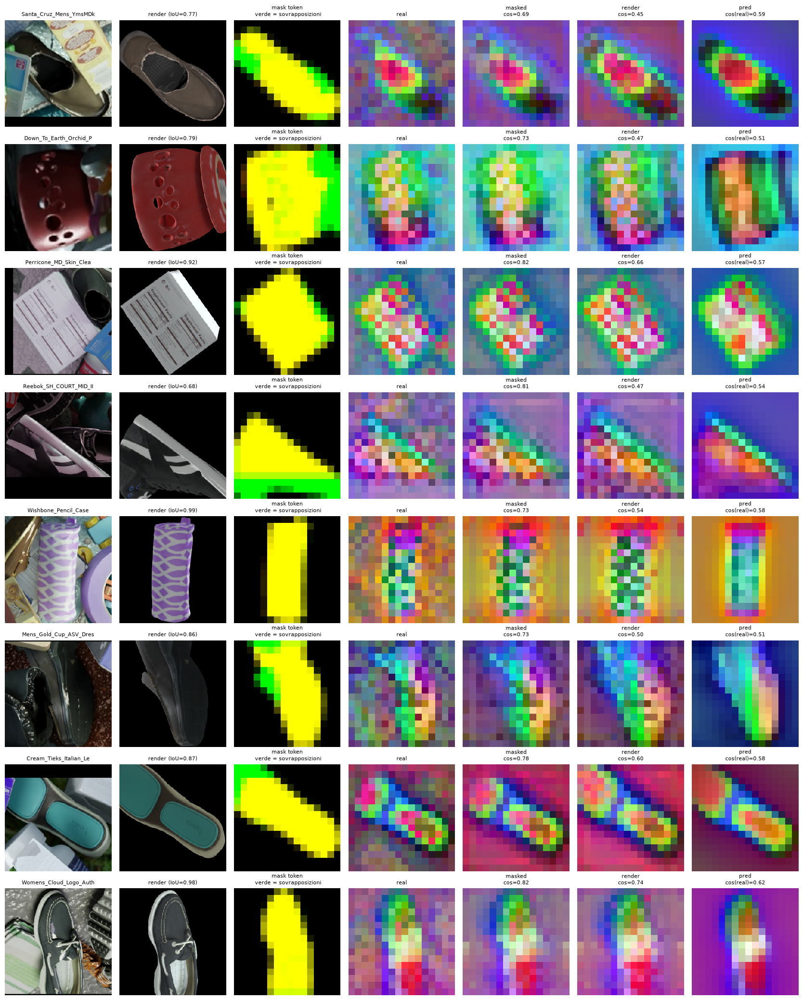

: 

In [ ]:
# =========================
# Quanto è "sporco" il target reale? real vs masked vs render TEXTURIZZATO (EGL)
# =========================
import os, sys
import numpy as np, torch, torch.nn.functional as F, trimesh, pyrender
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

BOP_ROOT = '/data/riccardop02/datasets/gso_MP/google_scanned_objects/models_bop-renderer_scale=0.1'
GSO_ROOT = '/data/riccardop02/datasets/gso'
GSO_CANDIDATES = ('meshes/model.obj', 'model.obj', 'meshes/model.glb', 'model.glb')
N_OBJ, SEED = 8, 0
_CV_TO_GL = np.diag([1., -1., -1., 1.]).astype(np.float32)
_MESH_CACHE = {}

# --- soglie per il test diagnostico sulla mask del render ---
IOU_MIN = 0.5      # sovrapposizione minima mask reale / mask render, sotto la quale scarto l'oggetto
MIN_TOKENS = 5      # minimo di token validi (sia per w reale che per w_render)

import glob
from PIL import Image
from trimesh.visual import TextureVisuals
from trimesh.visual.material import PBRMaterial

def _find_texture_files(name):
    files = []
    for ext in ('png', 'jpg', 'jpeg'):
        files += glob.glob(os.path.join(GSO_ROOT, name, '**', f'*.{ext}'), recursive=True)
    return sorted(files, key=lambda p: ('texture' not in os.path.basename(p).lower(), p))

def _has_image(vis):
    mat = getattr(vis, 'material', None)
    img = getattr(mat, 'image', None)
    if img is None:
        img = getattr(mat, 'baseColorTexture', None)
    return img is not None

def load_textured_aligned(name):
    """Mesh GSO con texture, allineata al frame del .ply BOP (scala + centro bbox)."""
    if name in _MESH_CACHE:
        return _MESH_CACHE[name]
    ply = trimesh.load(os.path.join(BOP_ROOT, name, 'meshes/model.ply'), process=False, force='mesh')
    path = next((os.path.join(GSO_ROOT, name, c) for c in GSO_CANDIDATES
                 if os.path.exists(os.path.join(GSO_ROOT, name, c))), None)
    if path is None:
        raise FileNotFoundError(f"mesh GSO texturizzata non trovata per {name} in {GSO_ROOT}")
    gso = trimesh.load(path, force='mesh')

    # --- texture: se trimesh non l'ha caricata, la applico a mano ---
    uv = getattr(gso.visual, 'uv', None)
    tex_files = _find_texture_files(name)
    print(f"[{name[:40]}] mesh={os.path.relpath(path, GSO_ROOT)} visual={gso.visual.kind} "
          f"uv={'sì' if uv is not None else 'NO'} immagine_caricata={_has_image(gso.visual)} "
          f"file_texture={[os.path.relpath(f, GSO_ROOT) for f in tex_files[:3]]}")
    if not _has_image(gso.visual):
        if uv is None:
            raise RuntimeError(f"{name}: la mesh non ha coordinate UV, non posso applicare la texture")
        if not tex_files:
            raise FileNotFoundError(f"{name}: nessun file di texture sotto {GSO_ROOT}/{name}")
        img = Image.open(tex_files[0]).convert('RGB')
        gso.visual = TextureVisuals(uv=uv, material=PBRMaterial(
            baseColorTexture=img, metallicFactor=0.0, roughnessFactor=1.0))

    ratios = ply.bounding_box.extents / gso.bounding_box.extents
    s = float(ratios.mean())
    gso.vertices = (gso.vertices - gso.bounds.mean(0)) * s + ply.bounds.mean(0)

    rel_std = float(ratios.std() / ratios.mean())
    max_dev = float(np.abs(gso.bounds - ply.bounds).max() / np.abs(ply.extents).max())
    _MESH_CACHE[name] = (gso, rel_std, max_dev, gso.visual.kind)
    return _MESH_CACHE[name]

def render_textured(renderer, model_name, R, t, K, centroid, scale):
    """Render texturizzato (sfondo nero, luce fissa) alla posa (R,t) nel frame normalizzato."""
    name = model_name[4:] if model_name.startswith('gso_') else model_name
    base, rel_std, max_dev, kind = load_textured_aligned(name)
    tm = base.copy()                                   # copy() mantiene UV e texture
    c = np.asarray(centroid, dtype=np.float32).reshape(3)
    tm.vertices = (tm.vertices - c) / float(scale)
    t_render = (np.asarray(t, dtype=np.float32) + R @ c) / float(scale)

    scene = pyrender.Scene(bg_color=[0, 0, 0, 0], ambient_light=[0.4, 0.4, 0.4])
    scene.add(pyrender.Mesh.from_trimesh(tm, smooth=True))
    scene.add(pyrender.DirectionalLight(color=np.ones(3), intensity=3.0), pose=np.eye(4))
    cam = pyrender.IntrinsicsCamera(fx=K[0, 0], fy=K[1, 1], cx=K[0, 2], cy=K[1, 2], znear=0.01, zfar=100.0)
    ext = np.eye(4, dtype=np.float32); ext[:3, :3] = R; ext[:3, 3] = t_render
    scene.add(cam, pose=np.linalg.inv(ext) @ _CV_TO_GL)
    color, depth = renderer.render(scene)
    return np.ascontiguousarray(color[:, :, :3]), np.ascontiguousarray(depth), (kind, rel_std, max_dev)

def to_norm_tensor(rgb_uint8):
    rgb = np.ascontiguousarray(rgb_uint8)
    x = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).unsqueeze(0).to(device)
    return (x - MEAN_t) / STD_t

def mask_to_tokens(mask_bool_hw, grid):
    """np.bool (H,W) -> tensore (grid*grid,) con la stessa logica BOX-average usata nel dataset."""
    m = Image.fromarray(mask_bool_hw.astype(np.uint8) * 255)
    m = m.resize((grid, grid), Image.BOX)
    return torch.from_numpy(np.array(m, dtype=np.float32) / 255.0).reshape(-1)

def tok_cos(a, b, w):   # a,b: (N,D); w: (N,) pesi = mask_tokens
    return ((F.cosine_similarity(a, b, dim=-1) * w).sum() / w.sum().clamp(min=1.0)).item()

def tok_l1(a, b, w):
    return (((a - b).abs().mean(-1) * w).sum() / w.sum().clamp(min=1.0)).item()

# --- oggetti casuali dal batch ---
actual_bs = batch['image'].shape[0]
rng = np.random.default_rng(SEED)
cand = rng.permutation(actual_bs)

pairs = [("real   vs masked", "real", "masked"), ("real   vs render", "real", "render"),
         ("masked vs render", "masked", "render"),
         ("pred   vs real", "pred", "real"), ("pred   vs masked", "pred", "masked"),
         ("pred   vs render", "pred", "render")]
res = {p[0]: {"cos": [], "l1": []} for p in pairs}
rows, align_info = [], {}
n_seen, n_skipped_iou, n_skipped_empty = 0, 0, 0

renderer = pyrender.OffscreenRenderer(256, 256)
try:
    for i in cand:
        w = batch['mask_tokens'][i].to(device).float()
        if (w > 0.5).sum() < MIN_TOKENS:
            continue                                          # oggetto quasi invisibile
        if len(rows) == N_OBJ:
            break
        n_seen += 1

        model_name = batch['model_name'][i]
        img_t = batch['image'][i].unsqueeze(0).to(device).float()
        if img_t.min() >= -0.01:                              # raw [0,1] -> normalizza
            img_t = (img_t - MEAN_t) / STD_t
        mask_pix = (batch['mask'][i].to(device).float().reshape(1, 1, *batch['mask'][i].shape[-2:]) > 0.5).float()

        K_np = batch['K'][i].cpu().numpy().astype(np.float32)
        R_np = batch['rot_matrix'][i].cpu().numpy().astype(np.float32)
        t_np = batch['trans'][i].cpu().numpy().astype(np.float32)
        c_np = batch['centroid'][i].reshape(-1).cpu().numpy()
        s_np = float(batch['scale'][i].reshape(-1)[0])

        # crop reale con sfondo azzerato (in spazio pixel)
        img_masked_t = ((((img_t * STD_t + MEAN_t).clamp(0, 1)) * mask_pix) - MEAN_t) / STD_t

        # render texturizzato alla posa vera
        col, dep, info = render_textured(renderer, model_name, R_np, t_np, K_np, c_np, s_np)
        align_info[model_name] = info
        render_t = to_norm_tensor(col)

        # --- mask del render, calcolata separatamente da quella reale (dalla depth) ---
        render_mask_bool = dep > 0
        w_render = mask_to_tokens(render_mask_bool, GRID_SIZE).to(device)

        valid_real = w > 0.5
        valid_render = w_render > 0.5
        if valid_render.sum() < MIN_TOKENS:
            print(f"[skip] {model_name}: render mask quasi vuota ({int(valid_render.sum())} token)")
            n_skipped_empty += 1
            continue

        union = (valid_real | valid_render).float().sum()
        inter = (valid_real & valid_render).float().sum()
        iou = (inter / union.clamp(min=1.0)).item()
        if iou < IOU_MIN:
            print(f"[skip] {model_name}: IoU mask reale/render = {iou:.2f} < {IOU_MIN}")
            n_skipped_iou += 1
            continue

        with torch.no_grad():
            f = {"real": encoder2d(img_t).squeeze(0),
                 "masked": encoder2d(img_masked_t).squeeze(0),
                 "render": encoder2d(render_t).squeeze(0)}
            ctx, cen = encoder3d.extractFeatures(
                batch['view_feats'][i].unsqueeze(0).float().to(device),
                batch['view_dirs'][i].unsqueeze(0).float().to(device),
                batch['view_mask'][i].unsqueeze(0).bool().to(device),
                batch['point_xyz'][i].unsqueeze(0).float().to(device))
            K_t = batch['K'][i].unsqueeze(0).to(device).float()
            rd, mo = _generate_rays(K_t, torch.from_numpy(R_np).unsqueeze(0).to(device),
                                    batch['trans'][i].unsqueeze(0).to(device).float(),
                                    batch['centroid'][i].reshape(-1)[None, :].to(device).float(),
                                    batch['scale'][i].reshape(-1)[:1].to(device).float())
            f["pred"] = predictor(ray_dirs=rd, ray_moments=mo, context_features=ctx,
                                  context_centers=cen).squeeze(0)

        # pesi diversi a seconda che il confronto coinvolga il render o no
        weight_for = {
            "real   vs masked": w,
            "real   vs render": w_render,
            "masked vs render": w_render,
            "pred   vs real":   w,
            "pred   vs masked": w,
            "pred   vs render": w_render,
        }

        line = {}
        for label, a, b in pairs:
            wt = weight_for[label]
            c, l = tok_cos(f[a], f[b], wt), tok_l1(f[a], f[b], wt)
            res[label]["cos"].append(c); res[label]["l1"].append(l); line[label] = c
        rows.append((i, model_name, batch['visib_fract'][i], line, f, img_t, col, w, w_render, iou))
finally:
    renderer.delete()

print(f"\nOggetti visti: {n_seen} | scartati per render mask vuota: {n_skipped_empty} | "
      f"scartati per IoU < {IOU_MIN}: {n_skipped_iou} | usati: {len(rows)}")

print("\n=== controllo allineamento mesh GSO texturizzata -> frame .ply ===")
for n, (kind, rel_std, max_dev) in align_info.items():
    flag = "" if (kind == 'texture' and rel_std < 1e-3 and max_dev < 1e-2) else "   <-- CONTROLLA"
    print(f"{n[:50]:<52} visual={kind:<8} scala_rel_std={rel_std:.1e}  bbox_dev={max_dev:.1e}{flag}")

print(f"\n{'oggetto':<58}{'visib':>6}{'IoU':>6}" + "".join(f"{p[0]:>20}" for p in pairs[:3]))
for i, name, vis, line, *_rest, iou in rows:
    print(f"{name[:56]:<58}{float(vis):>6.2f}{iou:>6.2f}" + "".join(f"{line[p[0]]:>20.3f}" for p in pairs[:3]))

print("\n=== MEDIA su", len(rows), "oggetti (cos | L1 su token oggetto) ===")
for label, _, _ in pairs:
    c, l = np.array(res[label]["cos"]), np.array(res[label]["l1"])
    print(f"{label:<20} cos = {c.mean():.3f} ± {c.std():.3f}   L1 = {l.mean():.4f} ± {l.std():.4f}")

# --- figura ---
N_COLS = 7
fig, axes = plt.subplots(len(rows), N_COLS, figsize=(16.8, 2.6 * len(rows)))
axes = np.atleast_2d(axes)
den = lambda x: (x * STD_t + MEAN_t).clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
for r, (i, name, vis, line, f, img_t, col, w, w_render, iou) in enumerate(rows):
    pca = PCA(n_components=3).fit(f["real"][w > 0.5].cpu().numpy())
    def pmap(x):
        z = pca.transform(x.cpu().numpy())
        z = (z - z.min(0)) / (z.max(0) - z.min(0) + 1e-8)
        return z.reshape(GRID_SIZE, GRID_SIZE, 3)

    # maschera sulla griglia di token: R = reale, G = render (giallo = sovrapposizione)
    w_r = w.detach().cpu().numpy().reshape(GRID_SIZE, GRID_SIZE)
    w_q = w_render.detach().cpu().numpy().reshape(GRID_SIZE, GRID_SIZE)
    mask_rgb = np.stack([w_r, w_q, np.zeros_like(w_r)], axis=-1)

    tiles = [(den(img_t), name.replace("gso_", "")[:22]),
             (col, f"render (IoU={iou:.2f})"),
             (mask_rgb, "mask token\n verde = sovrapposizioni"),
             (pmap(f["real"]), "real"),
             (pmap(f["masked"]), f"masked\ncos={line['real   vs masked']:.2f}"),
             (pmap(f["render"]), f"render\ncos={line['real   vs render']:.2f}"),
             (pmap(f["pred"]), f"pred\ncos(real)={line['pred   vs real']:.2f}")]
    for c, (im, tt) in enumerate(tiles):
        axes[r, c].imshow(im, interpolation='nearest')
        axes[r, c].set_title(tt, fontsize=8); axes[r, c].axis('off')
plt.tight_layout(); plt.show()